# Explainable and Forecasting-Based Analysis of Regional EV Adoption in India
End-to-end notebook.  Every stage is a script in this folder; each cell below runs one stage.  **Retrospective layer** = stages 01-03 (same-month associations).  **Prospective layer** = stages 04-06 (only origin-available information, release-aligned covariates).  Stage 00 builds the vintage panel; stage 07 examines the West Bengal episode (evidence only, not officially verified).

In [1]:
import sys, os
sys.path.insert(0, os.getcwd())

## `00a_apply_reference_data.py`
00a_apply_reference_data.py -- rebuild the model dataset from the ORIGINAL extract plus explicit reference tables
==================================================================================================================
Replaces the two infrastructure/income columns with documented reference tables (documented in data/external/CORRECTIONS_LOG.md):
  data/external/gsdp_per_capita_fy.csv        per-capita GSDP, current prices, by FINANCIAL YEAR (Actual/Revised/Advance/Projected)
  data/external/charging_snapshots.csv        public-charging-station snapshots (label month, value, approximate flag, assumed release)
  data/external/charging_all_india_context.csv  all-India totals (context only, not a model input)
Month mapping
  * NSDP: financial year FY(Y-(Y+1)) applies to Apr-Y .. Mar-(Y+1).  Jan-Mar 2022 belong to FY2021-22, which was not supplied, so they
    take the FY2022-23 value and are flagged nsdp_backfilled=1 (they are excluded from every vintage-aligned forecast input anyway).
  * Charging: step function - a month takes the latest snapshot whose label month <= that month.  Jan-Nov 2022 precede the first snapshot,
    take its value and are flagged charging_backfilled=1.
Cut-offs (common.py): registrations are used through Sep-2026; monthly covariates (air quality, weather, fuel prices) only through Aug-2026 -
Sep/Oct-2026 values in the original file were identical across states (placeholders) and are set to NaN here.
Input : data/raw/ev_adoption_ml_dataset_original.csv   Output: data/ev_adoption_ml_dataset.csv
Run from the project root:  python 00a_apply_reference_data.py

In [2]:
from common import BASE_DIR, COVARIATE_CUTOFF
import numpy as np
import pandas as pd

D = BASE_DIR / "data"
raw = pd.read_csv(D / "raw" / "ev_adoption_ml_dataset_original.csv", parse_dates=["date"])
gs = pd.read_csv(D / "external" / "gsdp_per_capita_fy.csv", parse_dates=["fy_start"])
ch = pd.read_csv(D / "external" / "charging_snapshots.csv", parse_dates=["label_month", "assumed_release_month"])

out = raw.copy()
# ---- NSDP by financial year
fy_start = out.date.where(out.date.dt.month >= 4, out.date - pd.DateOffset(years=1)).dt.year  # FY start calendar year
fy_start = np.where(out.date.dt.month >= 4, out.date.dt.year, out.date.dt.year - 1)
out["nsdp_fy_start"] = fy_start
first_fy = int(gs.fy_start.dt.year.min())
backfilled = out.nsdp_fy_start < first_fy
out.loc[backfilled, "nsdp_fy_start"] = first_fy
gs["nsdp_fy_start"] = gs.fy_start.dt.year
out = out.merge(gs.rename(columns={"fy": "nsdp_fy", "value_inr": "nsdp_per_capita", "status": "nsdp_status"})[
    ["state", "nsdp_fy_start", "nsdp_fy", "nsdp_per_capita", "nsdp_status"]], on=["state", "nsdp_fy_start"], how="left", suffixes=("_old", ""))
out["nsdp_backfilled"] = backfilled.astype(int).to_numpy()
out = out.drop(columns=["nsdp_per_capita_old", "nsdp_fy_start"])

# ---- charging snapshots (step function)
out = out.sort_values(["state", "date"]).reset_index(drop=True)
vals, labs, apx, bf = [], [], [], []
for s, d in zip(out.state, out.date):
    sn = ch[(ch.state == s) & (ch.label_month <= d)]
    if len(sn):
        r = sn.sort_values("label_month").iloc[-1]; bf.append(0)
    else:
        r = ch[ch.state == s].sort_values("label_month").iloc[0]; bf.append(1)
    vals.append(float(r.value)); labs.append(r.label_month.strftime("%Y-%m")); apx.append(int(r.approximate))
out["charging_stations"], out["charging_snapshot_label"], out["charging_approx"], out["charging_backfilled"] = vals, labs, apx, bf

# ---- mask monthly covariates after the covariate cut-off (placeholders in the original extract)
mask = out.date > COVARIATE_CUTOFF
for c in ["aqi_mean", "pm25_mean", "pm10_mean", "no2_mean", "so2_mean", "aqi_max", "mean_temp_c", "precipitation_mm", "petrol_price", "diesel_price"]:
    out.loc[mask, c] = np.nan
out.loc[mask, "dominant_pollutant"] = np.nan
out.to_csv(D / "ev_adoption_ml_dataset.csv", index=False)
print(f"wrote data/ev_adoption_ml_dataset.csv  {out.shape}; monthly covariates set to NaN for {int(mask.sum())} rows after {COVARIATE_CUTOFF:%b-%Y}")
print(out.groupby("state").apply(lambda g: g.drop_duplicates("nsdp_fy")[["nsdp_fy", "nsdp_status", "nsdp_per_capita"]].assign(first=g.drop_duplicates("nsdp_fy").date.dt.strftime("%Y-%m"))).to_string())
print(out[out.date.isin(pd.to_datetime(["2022-06-01", "2024-02-01", "2026-08-01", "2026-09-01"]))][["state", "date", "charging_stations", "charging_snapshot_label", "charging_backfilled", "nsdp_fy", "nsdp_per_capita"]].to_string())


wrote data/ev_adoption_ml_dataset.csv  (232, 45); monthly covariates set to NaN for 8 rows after Aug-2026
                 nsdp_fy nsdp_status  nsdp_per_capita    first
state                                                         
Delhi       0    2022-23      Actual           473500  2022-01
            15   2023-24     Revised           515500  2023-04
            27   2024-25     Advance           552727  2024-04
            39   2025-26     Advance           593071  2025-04
            51   2026-27   Projected           640000  2026-04
Maharashtra 58   2022-23      Actual           290954  2022-01
            73   2023-24     Revised           321100  2023-04
            85   2024-25     Advance           354225  2024-04
            97   2025-26     Advance           394477  2025-04
            109  2026-27   Projected           418000  2026-04
Tamil Nadu  116  2022-23      Actual           311500  2022-01
            131  2023-24     Revised           355200  2023-04
            

## `00_build_vintage_panel.py`
00_build_vintage_panel.py -- release-calendar alignment of covariates
Inputs : data/ev_adoption_ml_dataset.csv (raw extract), config/pipeline_config.json
Outputs: data/ev_panel_vintage.csv   (covariates as KNOWN at each forecast origin, no back-fill)
         data/release_calendar.csv   (what was assumed released when)
         outputs/tables/00_vintage_audit.csv, outputs/figures/fig00_vintage_vs_backfilled.png
Run from the project root:  python 00_build_vintage_panel.py

vintage panel: (228, 20)  ->  data/ev_panel_vintage.csv

         variable                 label assumed_release                                                                                                                                                                              definition                                                                                                                             status
charging_stations               2023-03         2023-04                                                                                                     PIB, Ministry of Heavy Industries, 24 Mar 2023 (data as of 21 Mar 2023), Annexure A ASSUMED release month (not the date printed on the source) - confirm; definitions differ across replies (operational vs installed)
charging_stations               2024-02         2024-03                                                                            PIB, Ministry of Heavy Industries, 6 Feb 2024 (data as of 2 Feb 2024; 

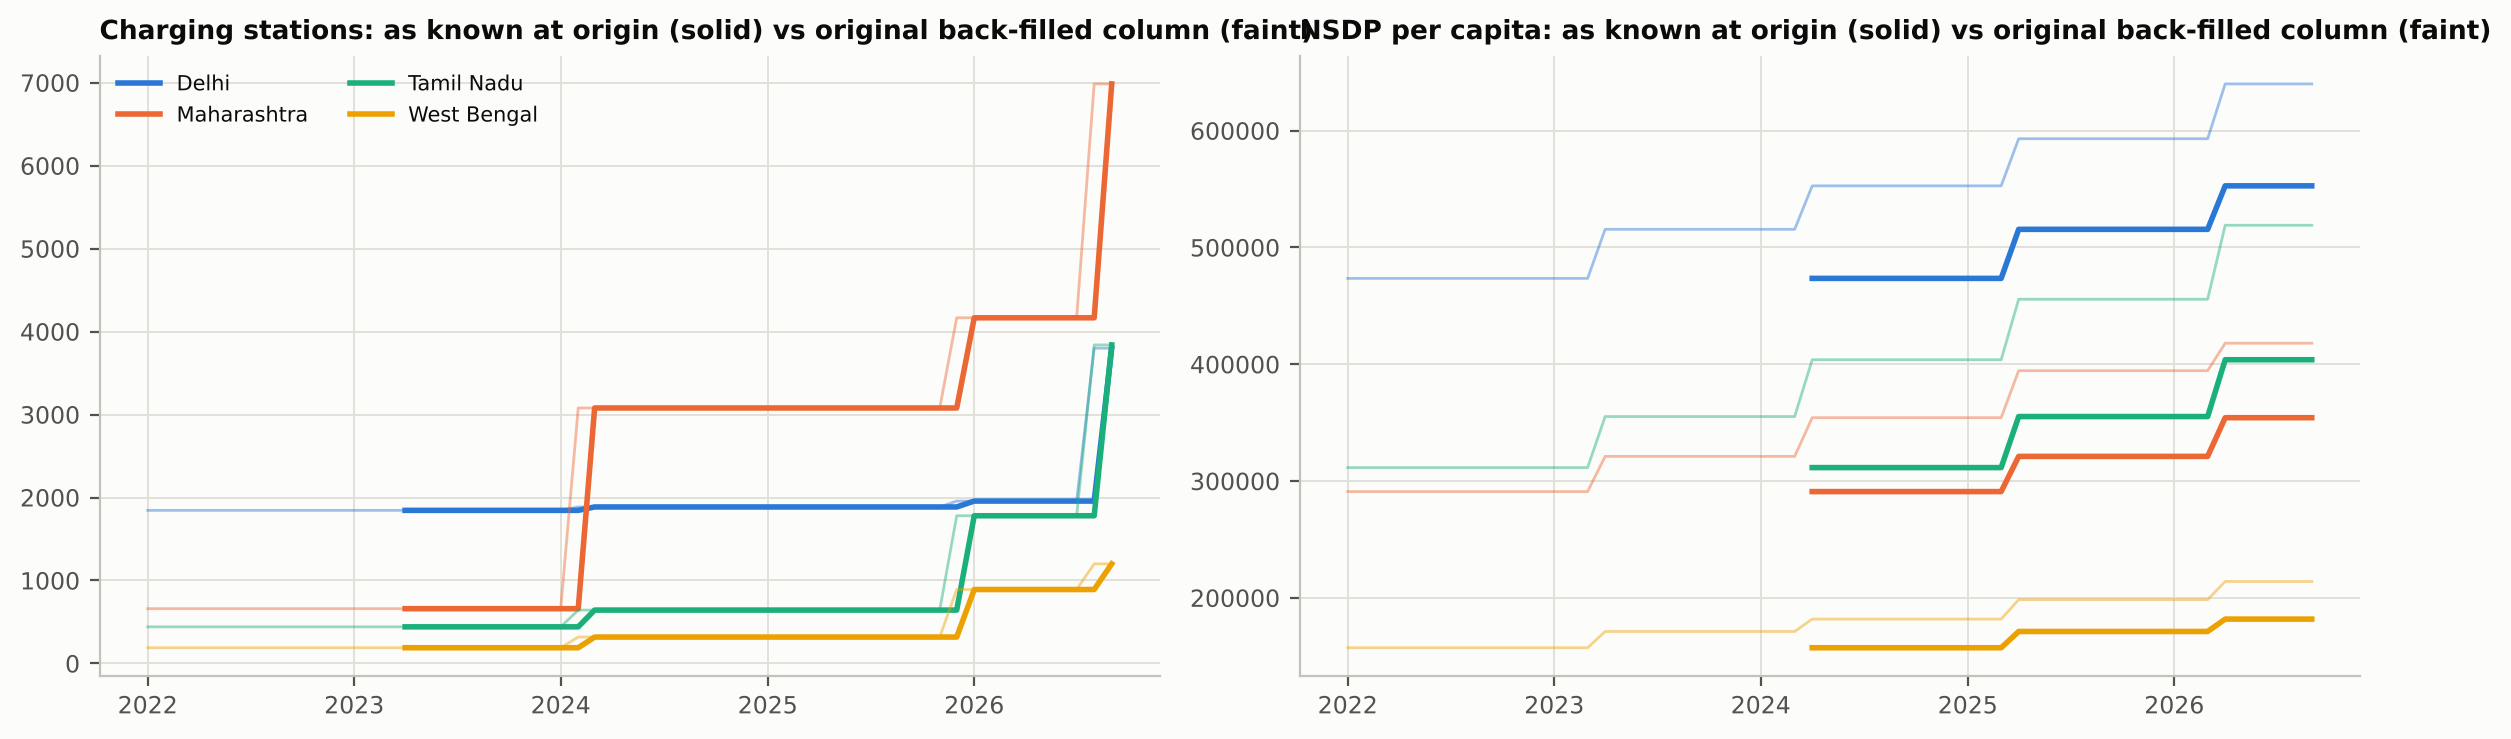

  [figure] outputs/figures/fig00_vintage_vs_backfilled.png


PosixPath('/home/claude/ev_adoption_project/outputs/figures/fig00_vintage_vs_backfilled.png')

In [3]:
from common import *
from vintage import build_vintage_panel, release_calendar, charging_snapshots

raw = load_data(complete=False)
panel = build_vintage_panel(raw)
panel.to_csv(BASE_DIR / "data" / "ev_panel_vintage.csv", index=False)
cal = release_calendar()
cal.to_csv(BASE_DIR / "data" / "release_calendar.csv", index=False)
print(f"vintage panel: {panel.shape}  ->  data/ev_panel_vintage.csv\n")
print(cal.to_string(index=False))

# Audit: how much of the original (back-filled) covariate information was NOT yet available at each origin?
chk = raw[["state", "date", "charging_stations", "nsdp_per_capita"]].merge(
    panel[["state", "date", "charging_stations", "nsdp_per_capita"]], on=["state", "date"], suffixes=("_backfilled", "_asof"))
rows = []
for c in ["charging_stations", "nsdp_per_capita"]:
    b, a = chk[f"{c}_backfilled"], chk[f"{c}_asof"]
    rows.append({"variable": c, "months_missing_at_origin_%": 100 * a.isna().mean(),
                 "months_where_value_differs_from_backfilled_%": 100 * ((a != b) & a.notna()).mean(),
                 "mean_abs_gap_when_differs_%": 100 * ((a - b).abs() / b)[(a != b) & a.notna()].mean()})
aud = pd.DataFrame(rows).round(2)
print("\nHow different is the vintage-aligned view from the original back-filled column?\n", aud.to_string(index=False))
save_table(aud, "00_vintage_audit", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, c, ttl in zip(axes, ["charging_stations", "nsdp_per_capita"], ["Charging stations", "NSDP per capita"]):
    for s in STATES:
        g = chk[chk.state == s]
        ax.plot(g.date, g[f"{c}_backfilled"], color=STATE_COLORS[s], lw=1, alpha=.45)
        ax.plot(g.date, g[f"{c}_asof"], color=STATE_COLORS[s], lw=2, label=s)
    ax.set_title(f"{ttl}: as known at origin (solid) vs original back-filled column (faint)", fontsize=9.5)
axes[0].legend(fontsize=7.5, ncol=2)
fig.tight_layout(); save_fig(fig, "fig00_vintage_vs_backfilled")


## `01_data_audit_eda.py`
01_data_audit_eda.py -- Stage 01: data audit and exploratory data analysis (retrospective, same-month data)
Run from the project root:  python 01_data_audit_eda.py

Panel used: 224 rows x 50 cols | states=4 | Jan 2022 -> Aug 2026  (COVARIATE_CUTOFF = Aug 2026; registrations run to Sep 2026)
            registrations_vs_trailing_median  env_columns_identical_across_states  dominant_pollutant_unknown  verdict
date                                                                                                                  
2026-05-01                              0.86                                    0                       False       ok
2026-06-01                              1.01                                    0                       False       ok
2026-07-01                              1.04                                    0                       False       ok
2026-08-01                              0.94                                    0                       False       ok
2026-09-01                              1.04                                    0                       False       ok
2026-10-01                              

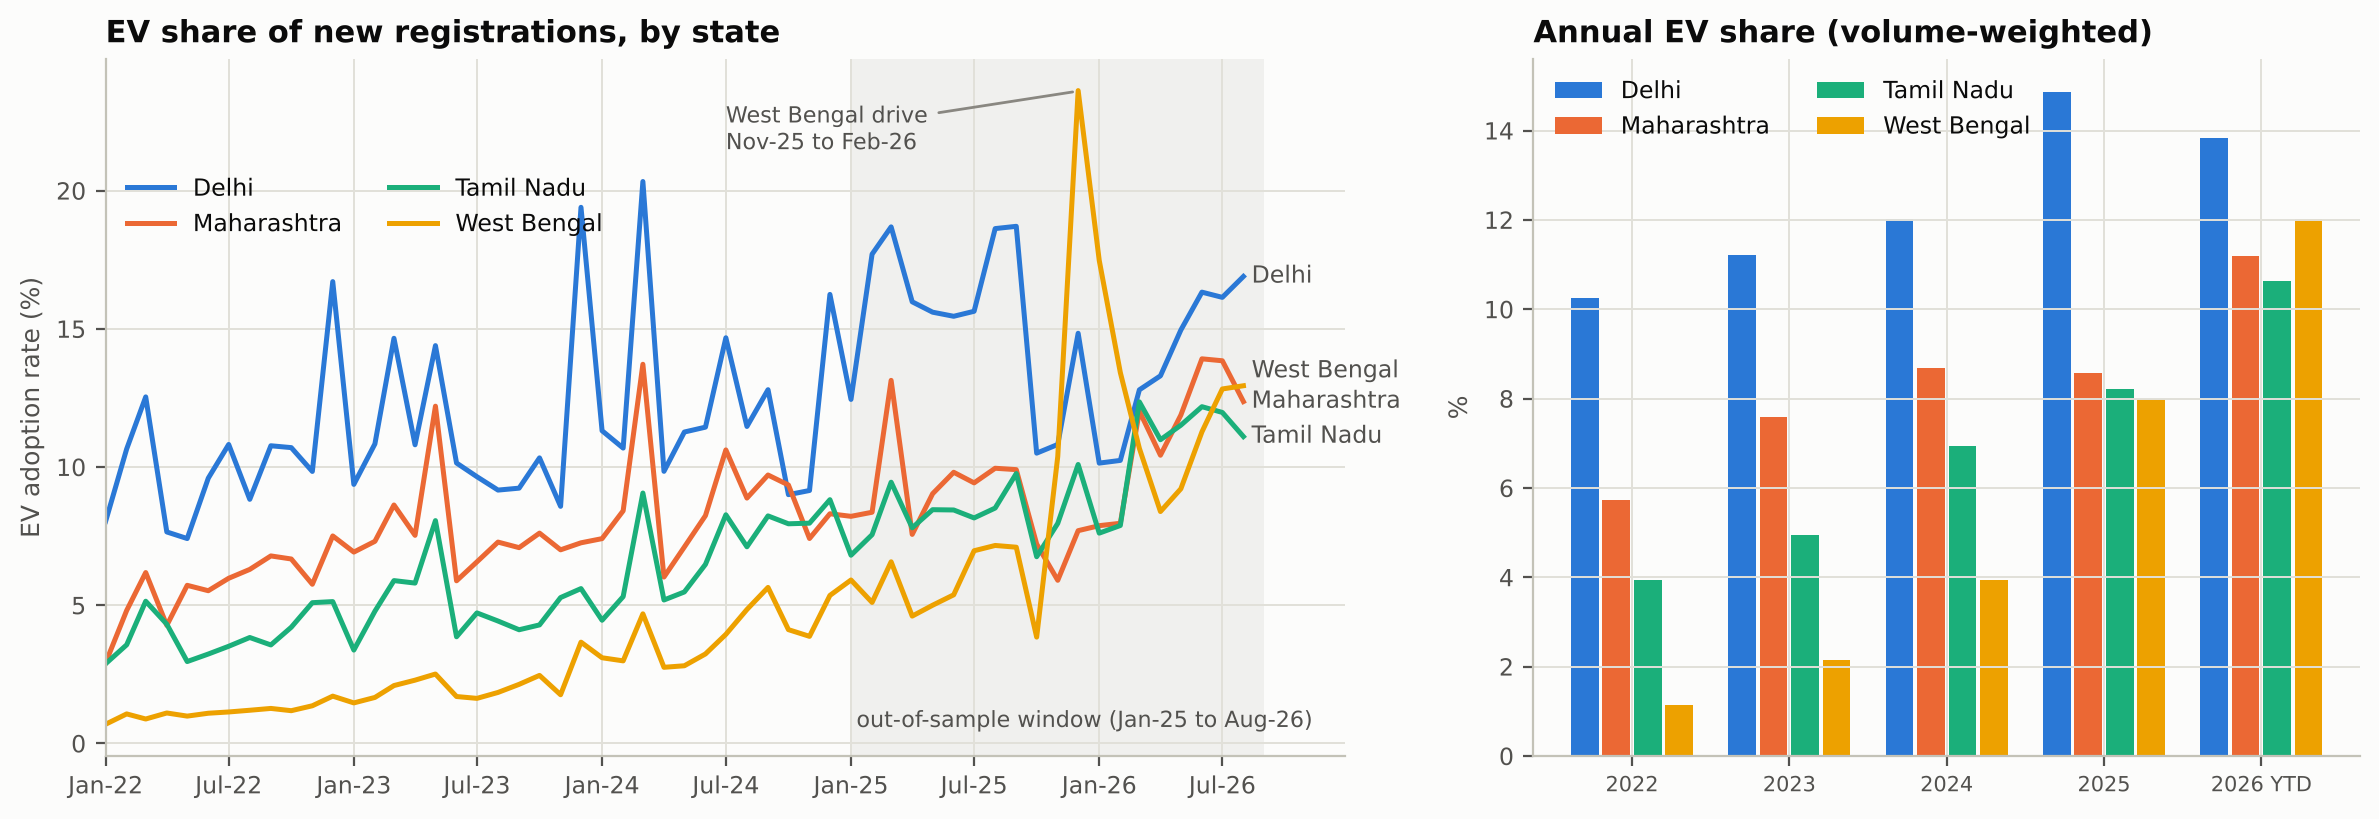

  [figure] outputs/figures/fig01_adoption_trajectories.png


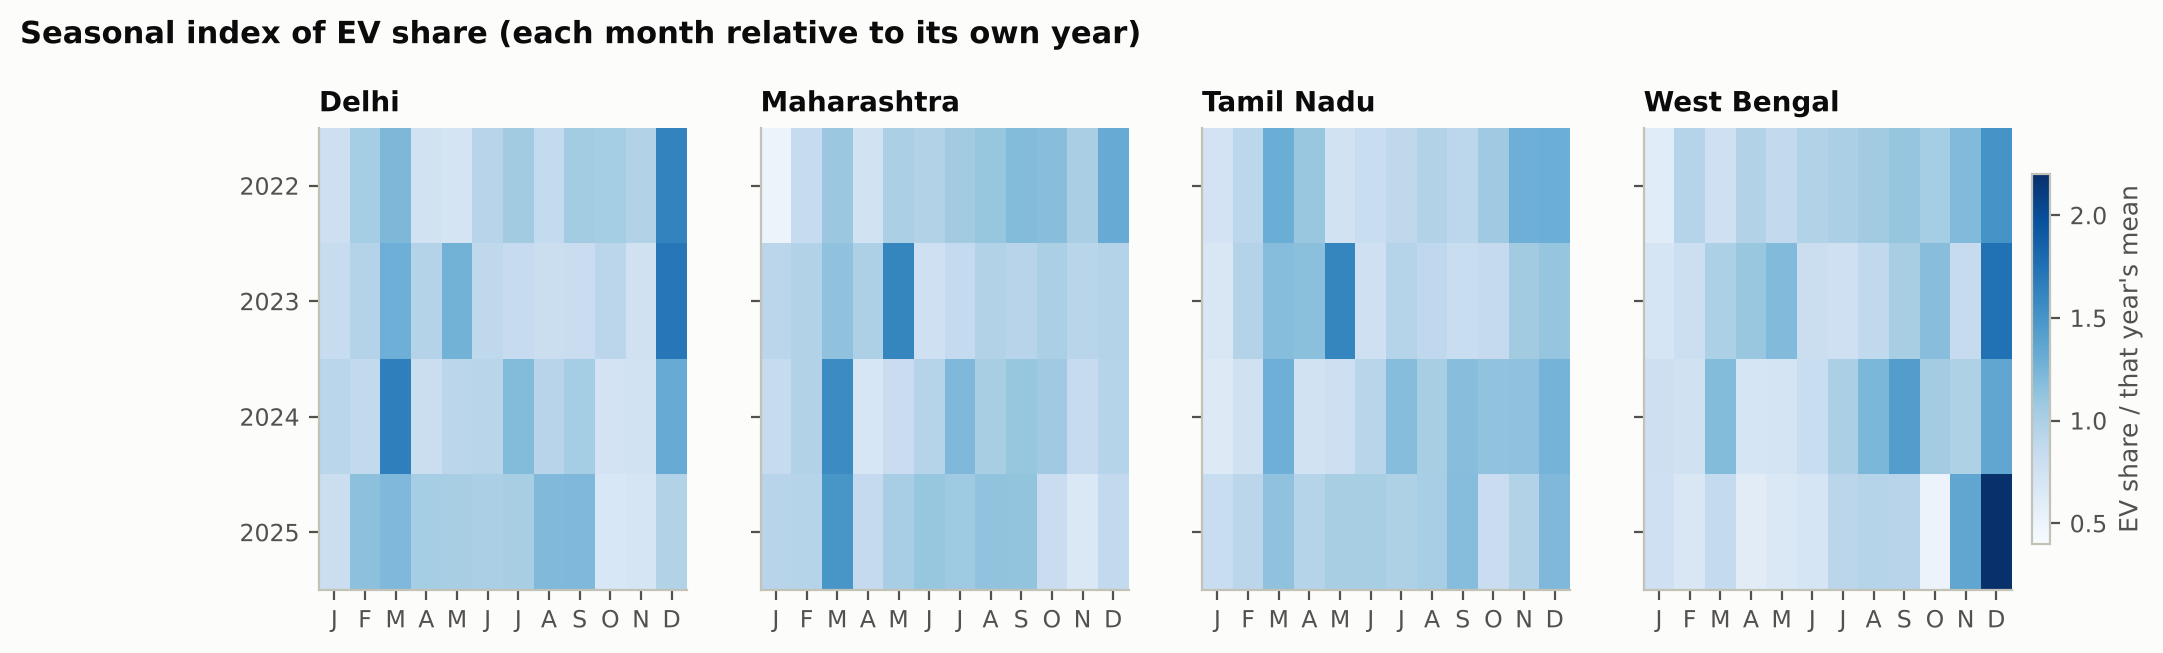

  [figure] outputs/figures/fig02_seasonality_heatmap.png


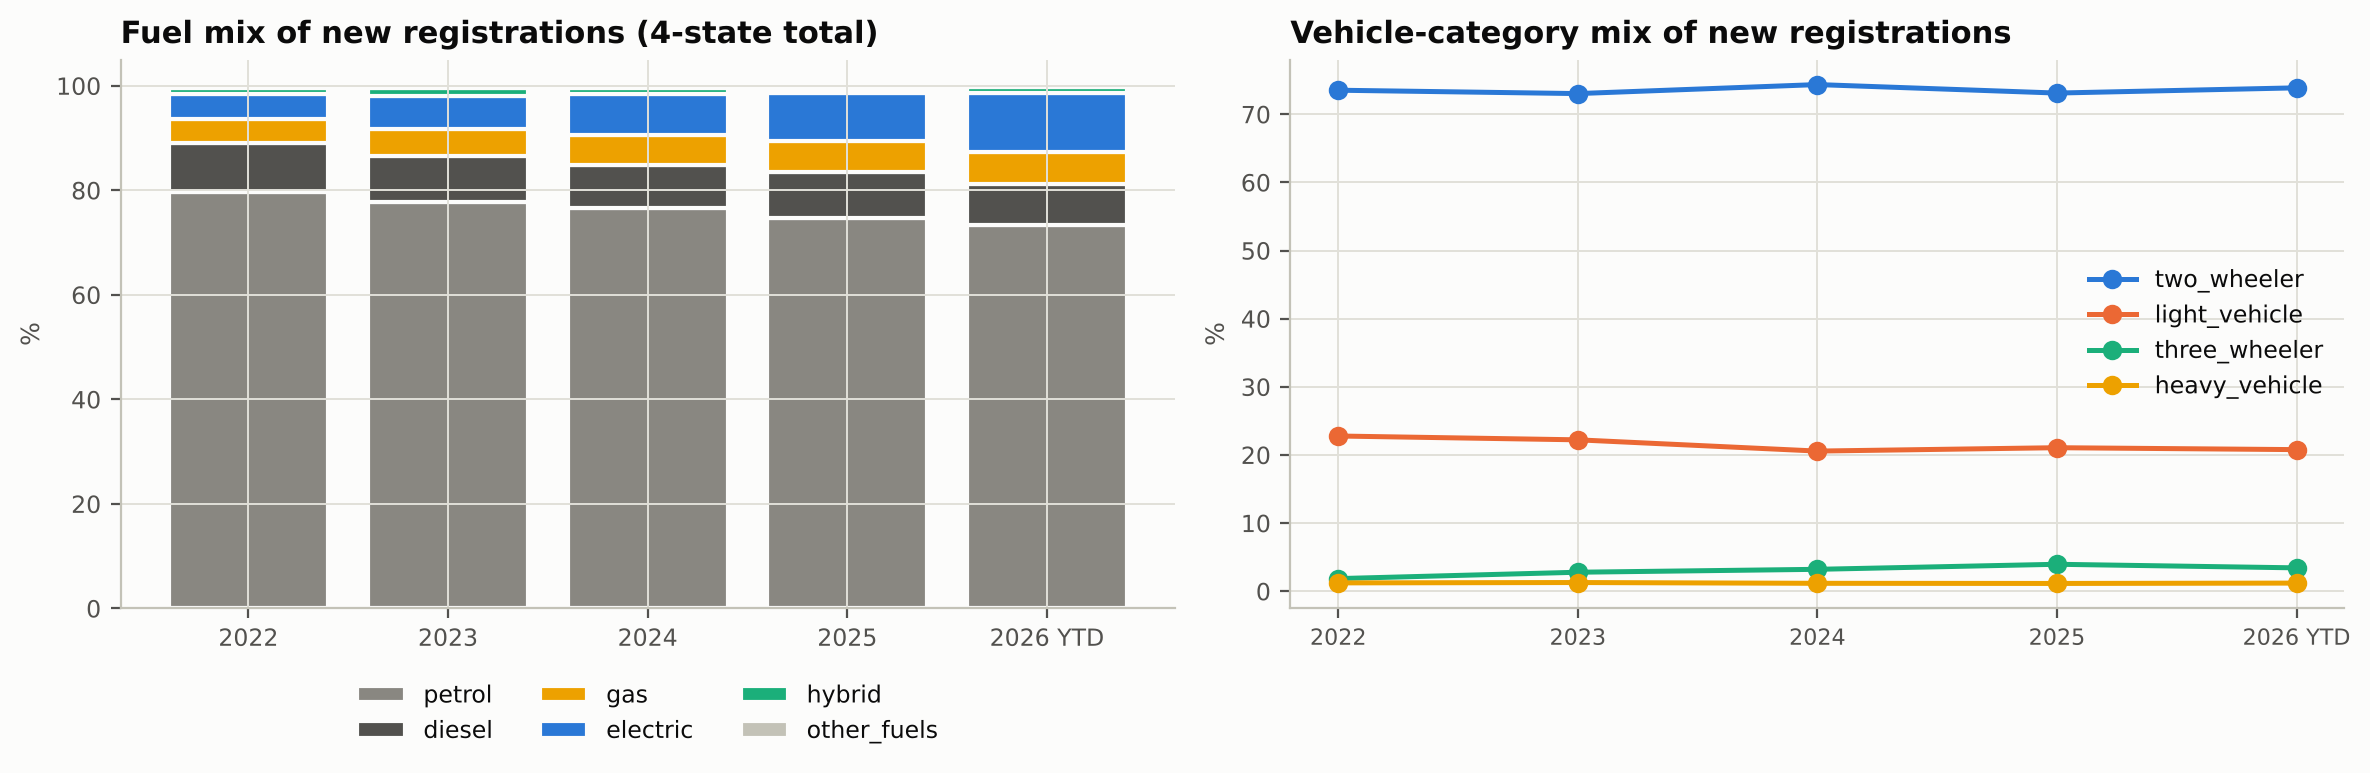

  [figure] outputs/figures/fig03_fuel_and_category_mix.png


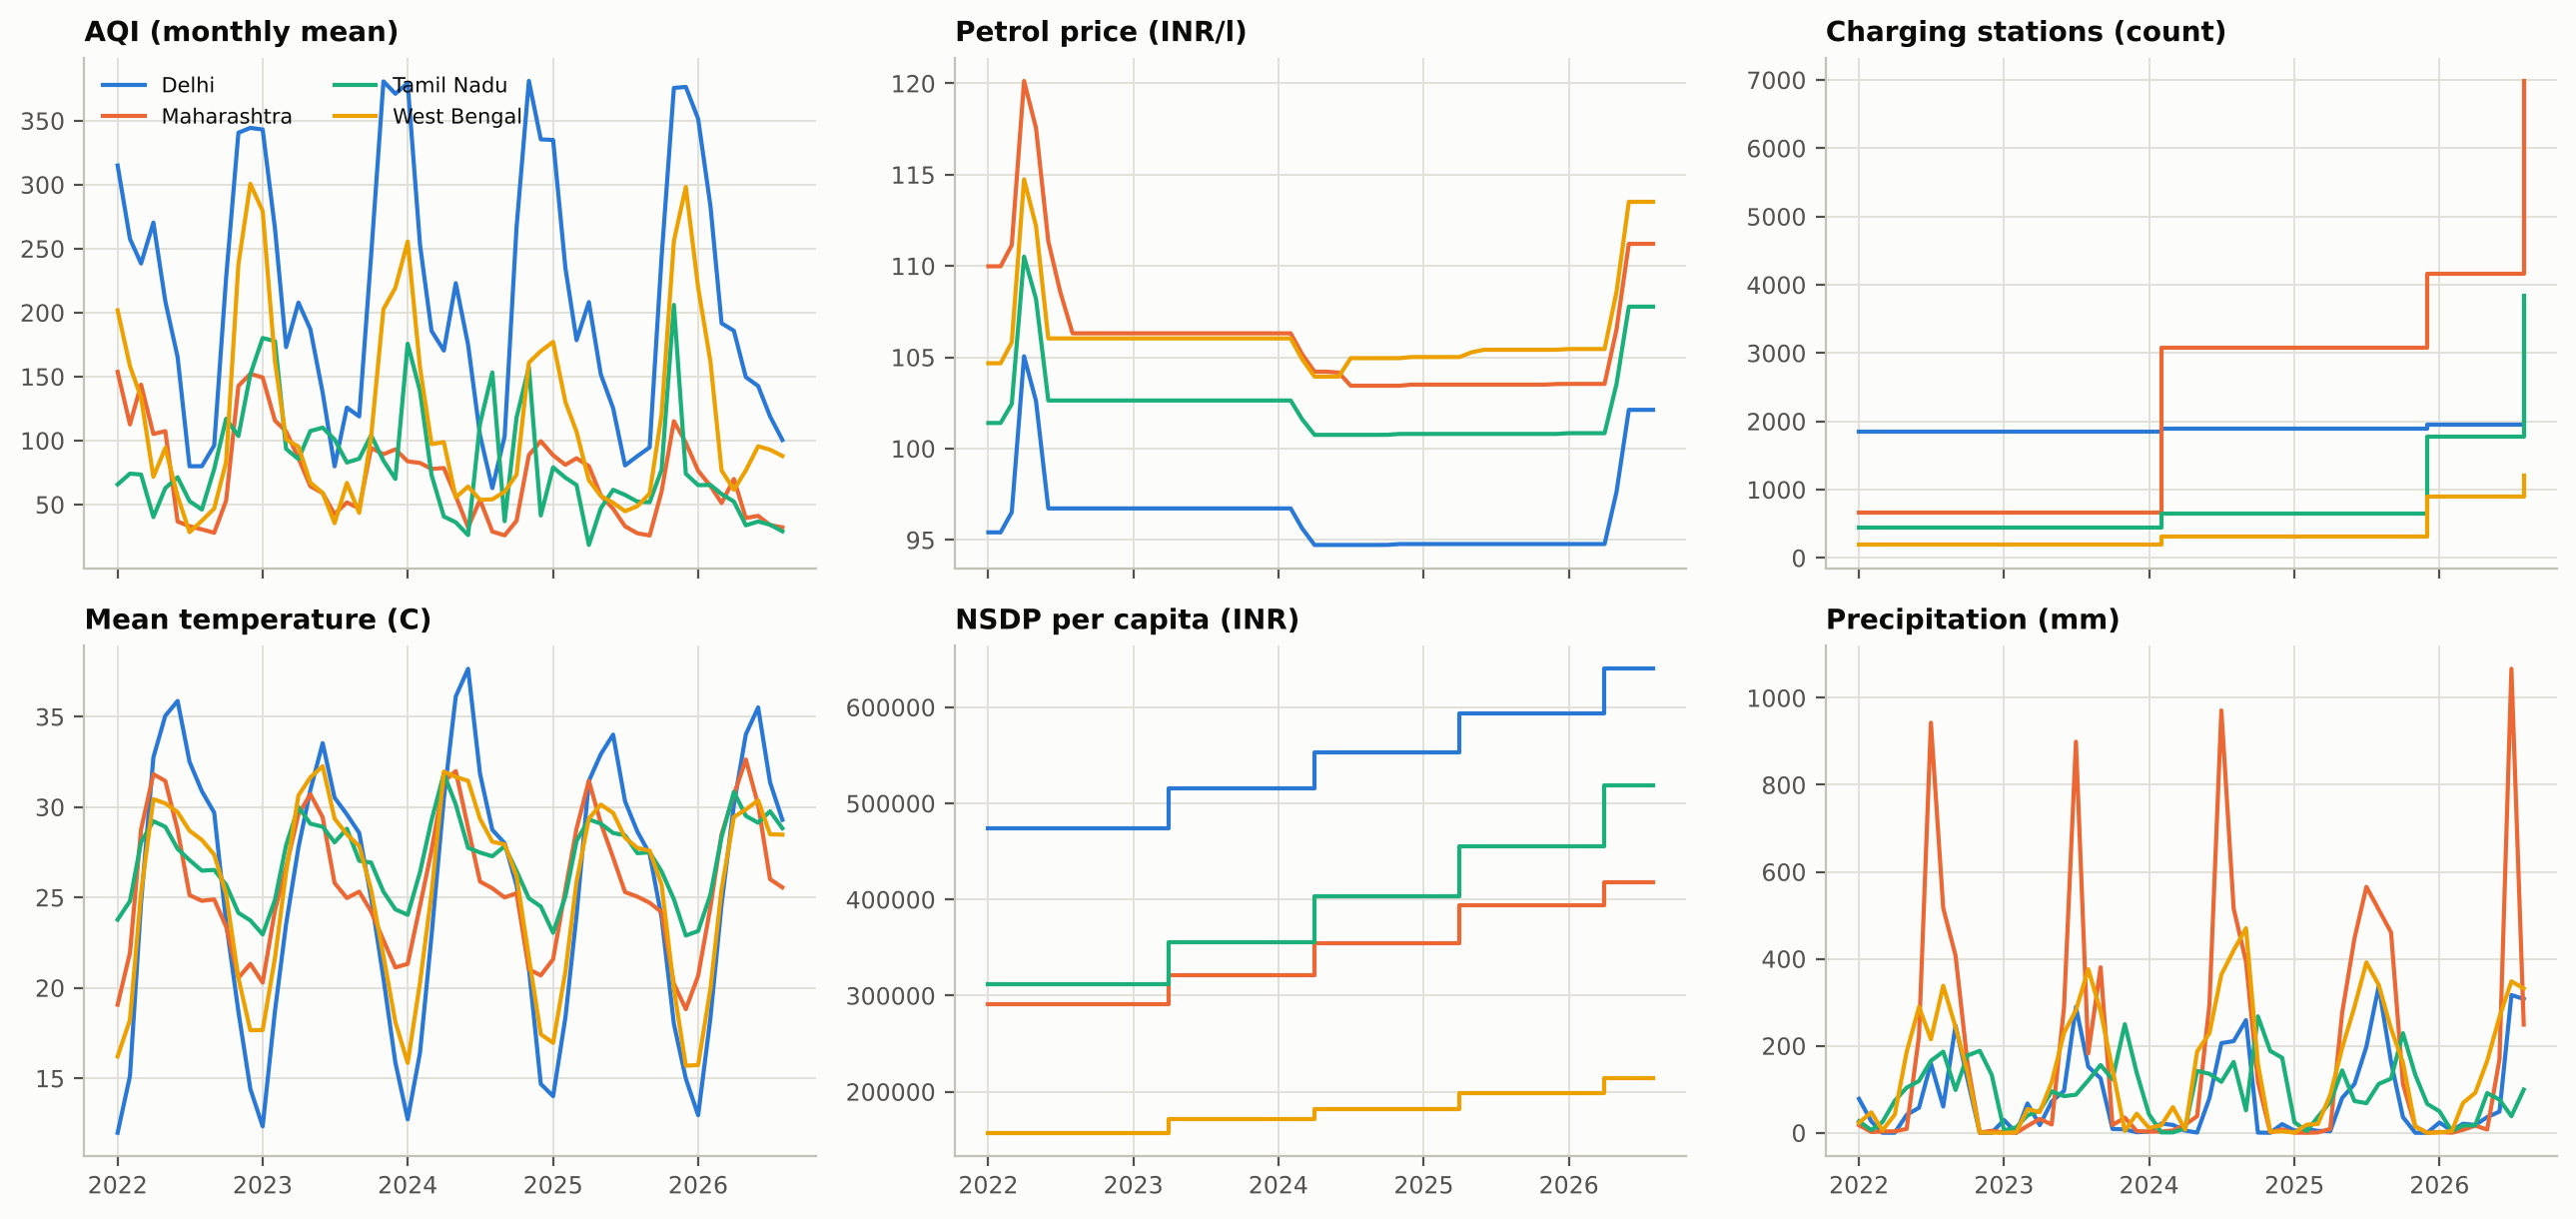

  [figure] outputs/figures/fig04_driver_timeseries.png


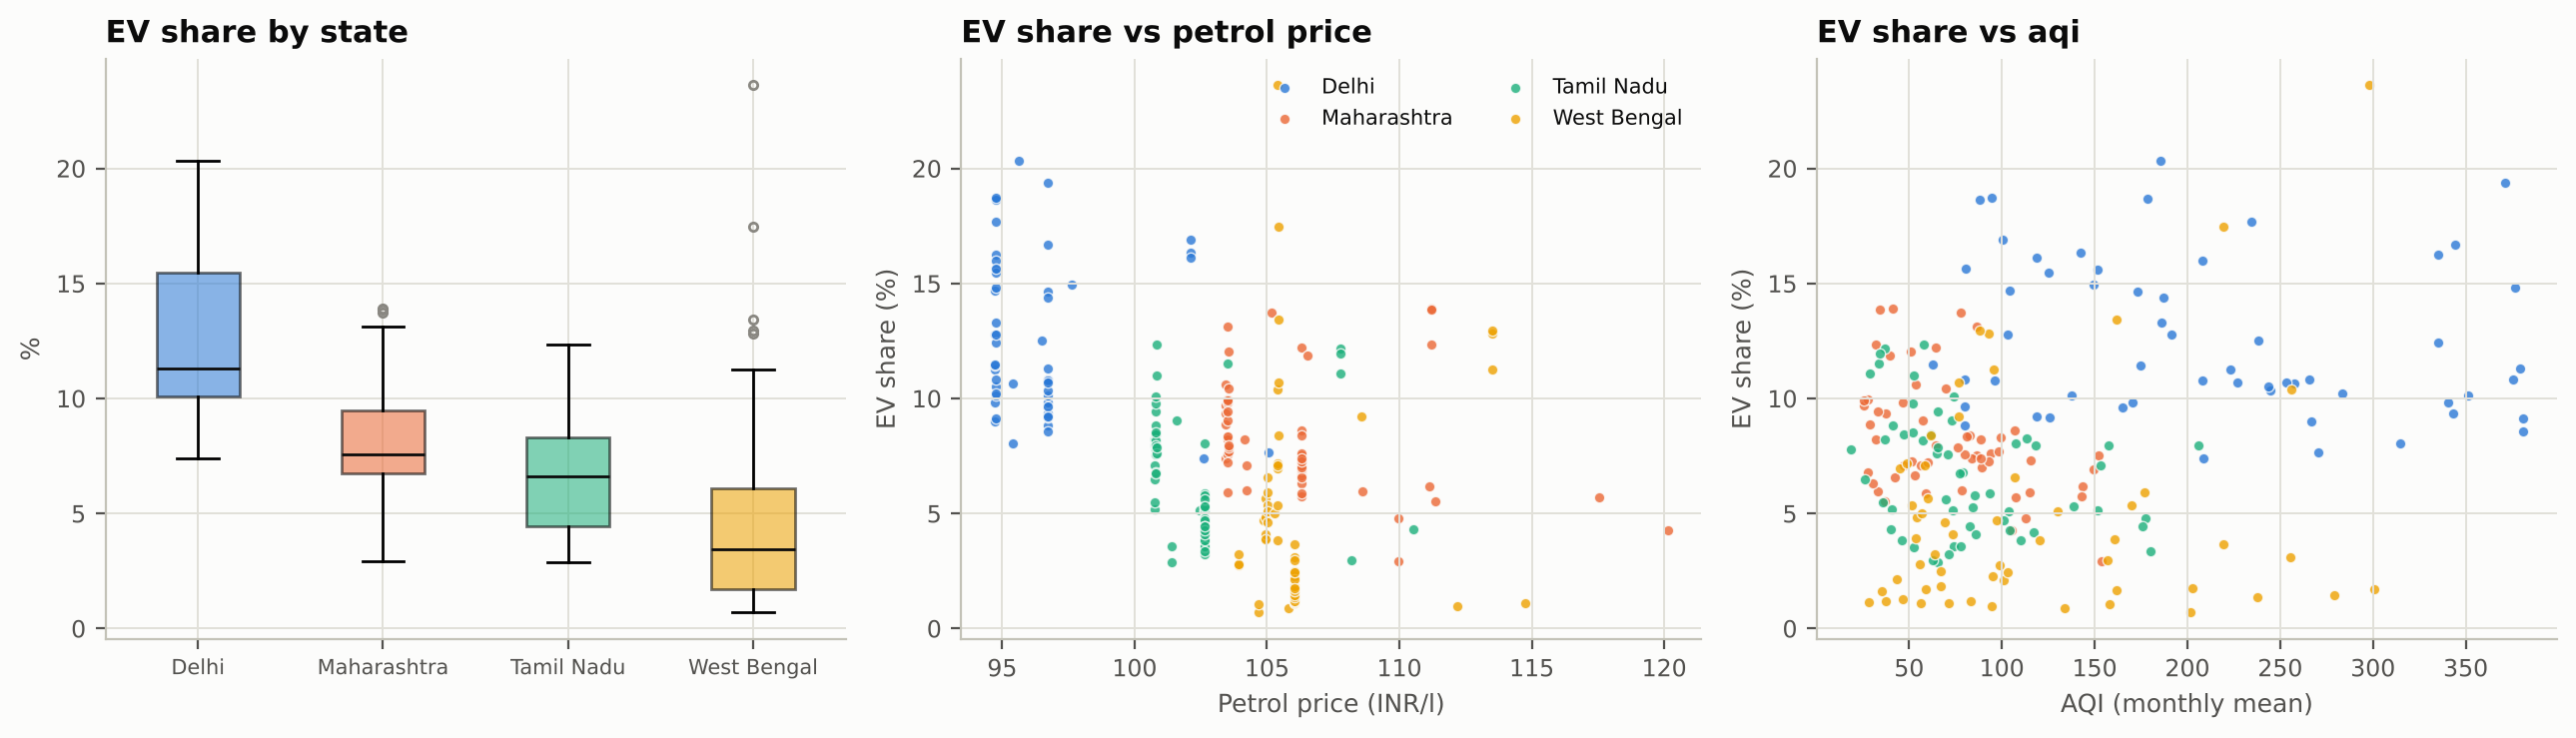

  [figure] outputs/figures/fig05_target_distribution_and_scatter.png


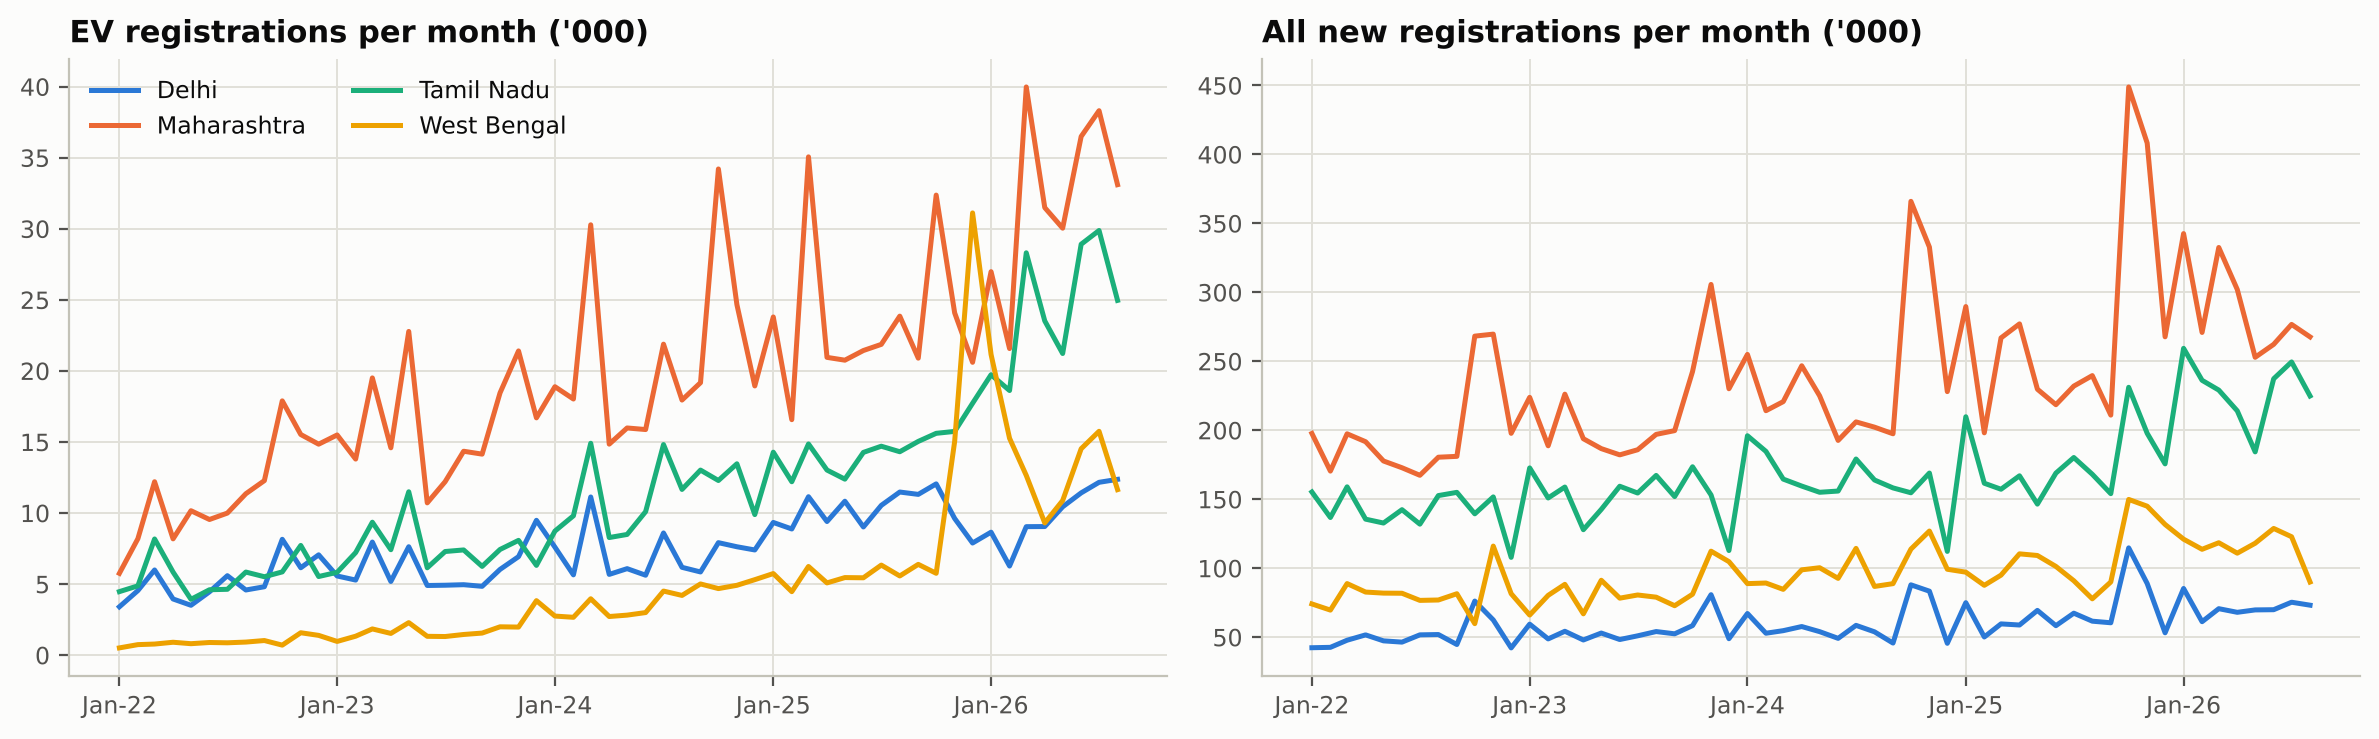

  [figure] outputs/figures/fig06_volumes.png
EV share (volume-weighted, %):
              2022   2025  2026 YTD  x 2022->2025
state                                            
Delhi        10.24  14.86     13.84          1.45
Maharashtra   5.73   8.58     11.18          1.50
Tamil Nadu    3.94   8.22     10.64          2.09
West Bengal   1.15   7.98     12.03          6.96

Ranking by 2022 share: Delhi, Maharashtra, Tamil Nadu, West Bengal | by 2025: Delhi, Maharashtra, Tamil Nadu, West Bengal | by 2026 YTD: Delhi, West Bengal, Maharashtra, Tamil Nadu
Note: West Bengal's 2025 and 2026 figures include the Nov-25..Feb-26 registration-drive episode.
Seasonal peaks recur around March (fiscal year-end) and Oct-Dec (festive season) - modelled explicitly in later stages.


In [4]:
from common import *

import matplotlib.dates as mdates
from statsmodels.tsa.seasonal import STL

df = load_data()
print(f"Panel used: {df.shape[0]} rows x {df.shape[1]} cols | states={df.state.nunique()} | "
      f"{df.date.min():%b %Y} -> {df.date.max():%b %Y}  (COVARIATE_CUTOFF = {COVARIATE_CUTOFF:%b %Y}; registrations run to {DATA_CUTOFF:%b %Y})")

# ## 0. Screening of the raw file - which trailing months can be trusted?
# A month is excluded when (a) its total registrations are < 40% of the trailing 6-month median
# (partial month) or (b) the environmental columns are *identical in every state* (placeholder fill).

raw = load_data(apply_cutoff=False)
tot = raw.groupby("date").vehicle_total.sum()
ratio = (tot / tot.shift(1).rolling(6).median()).rename("registrations_vs_trailing_median")
ENV_COLS = ["aqi_mean", "pm25_mean", "pm10_mean", "no2_mean", "so2_mean", "aqi_max", "mean_temp_c", "precipitation_mm"]
screen = pd.DataFrame({"registrations_vs_trailing_median": ratio,
                       "env_columns_identical_across_states": [sum(g[c].nunique() == 1 for c in ENV_COLS)
                                                               for _, g in raw.groupby("date")]}, index=tot.index)
screen["dominant_pollutant_unknown"] = raw.groupby("date").dominant_pollutant.apply(lambda x: (x == "Unknown").all()).values
screen["verdict"] = np.where((screen.registrations_vs_trailing_median < 0.4) | (screen.env_columns_identical_across_states >= 4)
                             | screen.dominant_pollutant_unknown, "EXCLUDE", "ok")
print(screen.tail(6).round(2).to_string())
bad = screen[screen.verdict == "EXCLUDE"].index
print(f"\nExcluded months: {[d.strftime('%b-%Y') for d in bad]}  -> analysis cut-off = {DATA_CUTOFF:%b %Y}")
assert all(d > DATA_CUTOFF for d in bad), "an excluded month lies inside the analysis window - revisit DATA_CUTOFF"
print(f"Registrations used through {DATA_CUTOFF:%b-%Y}; same-month explanatory stages use complete covariates only, through {COVARIATE_CUTOFF:%b-%Y} (later covariates are NaN).")
save_table(screen.round(3), "01_trailing_month_screen")

# ## 1. Structural audit - completeness, balance, internal consistency

FUEL = ["petrol", "diesel", "gas", "electric", "hybrid", "lpg", "alternative", "not_applicable"]
CATS = ["two_wheeler", "three_wheeler", "four_wheeler", "light_vehicle", "medium_vehicle", "heavy_vehicle", "other"]

expected_months = pd.date_range(df.date.min(), df.date.max(), freq="MS")
checks = {
    "Missing values (total)": int(df.isna().sum().sum()),
    "Duplicate state-month rows": int(df.duplicated(["state", "date"]).sum()),
    f"Panel balanced ({len(expected_months)} months x 4 states)": bool(
        (df.groupby("state").date.nunique() == len(expected_months)).all()),
    "No gaps in monthly calendar": bool(
        all((g.date.values == expected_months.values).all() for _, g in df.groupby("state"))),
    "ev_count == electric (all rows)": bool((df.ev_count == df.electric).all()),
    "ev_adoption_rate == ev_count / vehicle_total (max abs err)": float(
        (df.ev_count / df.vehicle_total - df[TARGET]).abs().max()),
    "Fuel-type columns sum to vehicle_total": bool((df[FUEL].sum(axis=1) == df.vehicle_total).all()),
    "Vehicle-category columns sum to vehicle_total": bool((df[CATS].sum(axis=1) == df.vehicle_total).all()),
    "Target within (0,1)": bool(df[TARGET].between(0, 1, inclusive="neither").all()),
    "Rows with dominant_pollutant == 'Insufficient data'": int((df.dominant_pollutant == "Insufficient data").sum()),
    "'four_wheeler' max monthly count (looks like a mapping artefact)": int(df.four_wheeler.max()),
}
audit = pd.Series(checks, name="result").to_frame()
display(audit) if "display" in globals() else print(audit.to_string())
save_table(audit, "01_integrity_checks")

# ## 2. Granularity audit - how often does each driver actually change?
# Charging stations and per-capita income are *low-frequency snapshots* repeated across months.
# This limits what any model can learn about them (see stage 03 caveats).

rows = []
for col in ["petrol_price", "diesel_price", "charging_stations", "nsdp_per_capita", "aqi_mean", "mean_temp_c"]:
    for s, g in df.groupby("state"):
        ch = g.loc[g[col].diff().fillna(0) != 0, "date"]
        rows.append({"variable": col, "state": s, "distinct_values": g[col].nunique(),
                     "n_changes": int(len(ch)),
                     "change_dates": ", ".join(d.strftime("%b-%y") for d in ch[:6])
                     if col in ("charging_stations", "nsdp_per_capita") else ""})
gran = pd.DataFrame(rows)
piv = gran.pivot(index="variable", columns="state", values="distinct_values")[STATES]
print(f"Distinct values per state ({df.t.max() + 1} months):")
print(piv.to_string())
print("\nCharging-station / income change dates:")
print(gran[gran.variable.isin(["charging_stations", "nsdp_per_capita"])]
      [["variable", "state", "change_dates"]].to_string(index=False))
save_table(gran, "01_granularity_audit", index=False)

# Per-capita income: annual change by state.  2026 values are state-government ESTIMATES (actuals not yet released).
nsdp = df.groupby(["state", "year"]).nsdp_per_capita.first().unstack("state")[STATES]
nsdp_chg = (nsdp.pct_change() * 100).round(1)
print("\nNSDP per capita, annual % change (latest years are state-government estimates):")
print(nsdp_chg.to_string())
odd = [(s_, int(y_)) for y_ in nsdp_chg.index for s_ in STATES if pd.notna(nsdp_chg.loc[y_, s_]) and (nsdp_chg.loc[y_, s_] < 0 or nsdp_chg.loc[y_, s_] > 15)]
print("Check basis / source (decline or >15% jump):", odd)
carried = [int(y_) for y_ in nsdp_chg.index if (nsdp_chg.loc[y_].fillna(1) == 0).all()]
print("Years whose income value is simply carried forward from the previous year (0% change in all states):", carried)
save_table(nsdp_chg, "01_nsdp_annual_change")

# ## 3. Outlier / anomaly screen
# Seasonal spikes (March, festive season) are real and recurring, so a plain z-score would flag them.
# Instead each month is compared with (a) the highest value of the *previous 12 months* and
# (b) the mean of the previous 3 months.  A month is "suspect" when it exceeds BOTH by a wide margin.

rows = []
for s, g in df.groupby("state"):
    g = g.set_index("date")[TARGET]
    prior_max12 = g.shift(1).rolling(12).max()
    prior_mean3 = g.shift(1).rolling(3).mean()
    r = pd.DataFrame({"state": s, "rate_%": 100 * g, "x_prior12_max": g / prior_max12, "x_prior3_mean": g / prior_mean3}).dropna()
    rows.append(r.reset_index())
scr = pd.concat(rows)
scr["suspect"] = (scr.x_prior12_max > 1.8) & (scr.x_prior3_mean > 2.0)
print("Top-8 months by exceedance of the previous-12-month maximum:")
print(scr.sort_values("x_prior12_max", ascending=False).head(8).round(2).to_string(index=False))
print("\nMonths flagged suspect:", scr.loc[scr.suspect, ["state", "date"]].astype(str).values.tolist())
flag_df = scr.sort_values("x_prior12_max", ascending=False).head(15)
save_table(flag_df, "01_anomaly_screen", index=False)

wb = df[(df.state == ANOMALY_STATE) & (df.date >= "2025-08-01")][["date", "vehicle_total", "ev_count", TARGET, "charging_stations"]]
print("\nWest Bengal, last months:\n", wb.round(4).to_string(index=False))
print(f"\n>> West Bengal {ANOMALY_START:%b-%Y}..{ANOMALY_END:%b-%Y} is flagged (anomaly_flag=1): a surge that decays over ~3 months, so\n   probably a real event rather than a typo - but verify against the raw Vahan extract.")

# ## 4. Descriptive statistics

desc_cols = [TARGET, "ev_count", "vehicle_total"] + CANDIDATE_DRIVERS
desc = df.groupby("state")[desc_cols].agg(["mean", "std", "min", "max"]).T
desc.index.names = ["variable", "stat"]
save_table(desc.round(3), "01_descriptives_by_state")

yearly = (df.groupby(["state", "year"]).agg(ev_count=("ev_count", "sum"), total=("vehicle_total", "sum"), months=("month", "nunique"))
          .assign(rate_pct=lambda x: 100 * x.ev_count / x.total).round(2))
yearly["ev_yoy_growth_%"] = (yearly.groupby("state").ev_count.pct_change() * 100).round(1)
yearly.loc[yearly.months < 12, "ev_yoy_growth_%"] = np.nan          # partial year: not comparable with a full year
print(yearly.to_string())
save_table(yearly, "01_yearly_adoption_summary")

# like-for-like growth of the latest (partial) year: same months of the previous year
LAST_Y = int(df.year.max()); LAST_M = int(df[df.year == LAST_Y].month.max())
ytd = (df[df.month <= LAST_M].groupby(["state", "year"]).agg(ev=("ev_count", "sum"), tot=("vehicle_total", "sum")).reset_index())
ytd["rate_%"] = 100 * ytd.ev / ytd.tot
ytd_cmp = ytd[ytd.year.isin([LAST_Y - 1, LAST_Y])].pivot(index="state", columns="year", values=["ev", "rate_%"]).loc[STATES]
ytd_cmp[("ev_growth_%", LAST_Y)] = 100 * (ytd_cmp[("ev", LAST_Y)] / ytd_cmp[("ev", LAST_Y - 1)] - 1)
print(f"\nJan-{pd.Timestamp(2000, LAST_M, 1):%b} {LAST_Y} vs same months of {LAST_Y - 1}:")
print(ytd_cmp.round(1).to_string())
save_table(ytd_cmp.round(2), "01_ytd_comparison")

# ## 5. Figures
# ### Fig 1 - Adoption trajectories (RQ1)

set_style()
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
W = wide(df)
for s in STATES:
    ax.plot(W.index, 100 * W[s], color=STATE_COLORS[s], label=s)
# end-of-line labels, nudged apart so that close values do not overlap
ends = sorted(((100 * W[s].iloc[-1], s) for s in STATES))
pos, last = {}, -99
for v, s in ends:
    pos[s] = max(v, last + 1.1); last = pos[s]
for s in STATES:
    ax.text(W.index[-1] + pd.Timedelta(days=12), pos[s], s, color=INK2, va="center", fontsize=8.5)
ax.axvspan(TEST_START, COVARIATE_CUTOFF + pd.offsets.MonthEnd(0), color="#898781", alpha=0.10, lw=0)
ax.text(TEST_START + pd.Timedelta(days=8), 0.4, f"out-of-sample window ({TEST_START:%b-%y} to {COVARIATE_CUTOFF:%b-%y})", color=INK2, fontsize=8, va="bottom")
ax.annotate("West Bengal drive\nNov-25 to Feb-26", xy=(pd.Timestamp("2025-12-01"), 23.6),
            xytext=(pd.Timestamp("2024-07-01"), 21.5), fontsize=8, color=INK2,
            arrowprops=dict(arrowstyle="-", color=MUTED))
ax.set_title("EV share of new registrations, by state")
ax.set_ylabel("EV adoption rate (%)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
ax.set_xlim(W.index[0], W.index[-1] + pd.Timedelta(days=150))
ax.legend(loc="upper left", ncol=2, bbox_to_anchor=(0.0, 0.86))

ax = axes[1]
y = yearly.reset_index().pivot(index="year", columns="state", values="rate_pct")[STATES]
x = np.arange(len(y.index)); w = 0.2
for i, s in enumerate(STATES):
    ax.bar(x + (i - 1.5) * w, y[s], w * 0.88, color=STATE_COLORS[s], label=s)
ax.set_xticks(x, [f"{i}{' YTD' if yearly.loc[(STATES[0], i), 'months'] < 12 else ''}" for i in y.index])
ax.set_title("Annual EV share (volume-weighted)"); ax.set_ylabel("%"); ax.tick_params(axis="x", labelsize=7.5)
ax.legend(ncol=2, loc="upper left")
fig.tight_layout()
save_fig(fig, "fig01_adoption_trajectories")

# ### Fig 2 - Seasonality: the registration calendar matters (festive season, fiscal year-end)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.0), sharey=True)
for ax, s in zip(axes, STATES):
    g = df[(df.state == s) & (df.year < LAST_Y)]          # complete calendar years only (a partial year would bias the index)
    # detrend by dividing each month by its calendar-year mean -> seasonal index
    idx = g[TARGET] / g.groupby("year")[TARGET].transform("mean")
    h = pd.DataFrame({"year": g.year, "month": g.month, "idx": idx}).pivot(index="year", columns="month", values="idx")
    im = ax.imshow(h.values, cmap="Blues", vmin=0.4, vmax=2.2, aspect="auto")
    ax.set_xticks(range(12), list("JFMAMJJASOND")); ax.set_yticks(range(len(h.index)), h.index)
    ax.set_title(s, fontsize=10); ax.grid(False)
cbar = fig.colorbar(im, ax=axes, shrink=0.8, pad=0.01); cbar.set_label("EV share / that year's mean")
fig.suptitle("Seasonal index of EV share (each month relative to its own year)", x=0.01, y=1.06, ha="left", fontweight="bold", fontsize=11)
save_fig(fig, "fig02_seasonality_heatmap")

# ### Fig 3 - Fuel-type mix and vehicle-category mix (what is being electrified?)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fuel_share = df.groupby("year")[FUEL].sum()
fuel_share = fuel_share.div(fuel_share.sum(axis=1), axis=0) * 100
YEAR_LABEL = {y_: f"{y_} YTD" if y_ == LAST_Y and LAST_M < 12 else str(y_) for y_ in fuel_share.index}
order = ["petrol", "diesel", "gas", "electric", "hybrid"]
cols = ["#898781", "#52514e", "#eda100", "#2a78d6", "#1baf7a"]
fuel_share = fuel_share.assign(other_fuels=100 - fuel_share[order].sum(axis=1))
bottom = np.zeros(len(fuel_share))
for c, col in zip(order + ["other_fuels"], cols + ["#c3c2b7"]):
    axes[0].bar([YEAR_LABEL[i] for i in fuel_share.index], fuel_share[c], bottom=bottom, color=col, label=c, edgecolor=SURFACE, linewidth=1.5)
    bottom += fuel_share[c].values
axes[0].set_title("Fuel mix of new registrations (4-state total)"); axes[0].set_ylabel("%")
axes[0].legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.1))
cat_share = df.groupby("year")[CATS].sum(); cat_share = cat_share.div(cat_share.sum(axis=1), axis=0) * 100
cat_share[["two_wheeler", "light_vehicle", "three_wheeler", "heavy_vehicle"]].plot(
    ax=axes[1], color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100"], marker="o")
axes[1].set_title("Vehicle-category mix of new registrations"); axes[1].set_ylabel("%"); axes[1].set_xlabel("")
axes[1].set_xticks(cat_share.index, [YEAR_LABEL[i] for i in cat_share.index], fontsize=8)
fig.tight_layout()
save_fig(fig, "fig03_fuel_and_category_mix")

# ### Fig 4 - Candidate drivers over time (are they aligned in state x month?)

panel = [("aqi_mean", "AQI (monthly mean)"), ("petrol_price", "Petrol price (INR/l)"),
         ("charging_stations", "Charging stations (count)"), ("mean_temp_c", "Mean temperature (C)"),
         ("nsdp_per_capita", "NSDP per capita (INR)"), ("precipitation_mm", "Precipitation (mm)")]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.2), sharex=True)
for ax, (c, t) in zip(axes.ravel(), panel):
    Wc = wide(df, c)
    for s in STATES:
        ax.plot(Wc.index, Wc[s], color=STATE_COLORS[s], lw=1.5, label=s,
                drawstyle="steps-post" if c in ("charging_stations", "nsdp_per_capita") else "default")
    ax.set_title(t, fontsize=10); ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[0, 0].legend(ncol=2, loc="upper left", fontsize=7.5)
fig.tight_layout()
save_fig(fig, "fig04_driver_timeseries")

# ### Fig 5 - Distribution of the target and raw bivariate relationships

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
bp = axes[0].boxplot([100 * df.loc[df.state == s, TARGET] for s in STATES], tick_labels=STATES, patch_artist=True,
                     medianprops=dict(color=INK), flierprops=dict(markersize=3, markeredgecolor=MUTED))
for patch, s in zip(bp["boxes"], STATES):
    patch.set_facecolor(STATE_COLORS[s]); patch.set_alpha(0.55)
axes[0].set_title("EV share by state"); axes[0].set_ylabel("%"); axes[0].tick_params(axis="x", labelsize=7.5)
for ax, (c, t) in zip(axes[1:], [("petrol_price", "Petrol price (INR/l)"), ("aqi_mean", "AQI (monthly mean)")]):
    for s in STATES:
        g = df[df.state == s]
        ax.scatter(g[c], 100 * g[TARGET], s=14, color=STATE_COLORS[s], alpha=0.8, edgecolor=SURFACE, linewidth=0.5, label=s)
    ax.set_xlabel(t); ax.set_ylabel("EV share (%)"); ax.set_title(f"EV share vs {t.split(' (')[0].lower()}")
axes[1].legend(fontsize=7.5, ncol=2)
fig.tight_layout()
save_fig(fig, "fig05_target_distribution_and_scatter")

# ### Fig 6 - EV volumes vs total registrations (denominator effects)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for s in STATES:
    g = df[df.state == s]
    axes[0].plot(g.date, g.ev_count / 1000, color=STATE_COLORS[s], label=s)
    axes[1].plot(g.date, g.vehicle_total / 1000, color=STATE_COLORS[s], label=s)
axes[0].set_title("EV registrations per month ('000)"); axes[1].set_title("All new registrations per month ('000)")
axes[0].legend(ncol=2)
for ax in axes: ax.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))
fig.tight_layout()
save_fig(fig, "fig06_volumes")

# ## 6. Key EDA take-aways (printed so they can be pasted into the report)

def share(frame):
    return frame.groupby("state").apply(lambda g: 100 * g.ev_count.sum() / g.vehicle_total.sum())


s22, s25 = share(df[df.year == 2022]), share(df[df.year == 2025])
s26 = share(df[df.year == LAST_Y])
print("EV share (volume-weighted, %):")
print(pd.DataFrame({"2022": s22, "2025": s25, f"{LAST_Y} YTD": s26, "x 2022->2025": s25 / s22}).round(2).loc[STATES].to_string())
print("\nRanking by 2022 share:", ", ".join(s22.sort_values(ascending=False).index),
      "| by 2025:", ", ".join(s25.sort_values(ascending=False).index), f"| by {LAST_Y} YTD:", ", ".join(s26.sort_values(ascending=False).index))
print(f"Note: West Bengal's 2025 and {LAST_Y} figures include the Nov-25..Feb-26 registration-drive episode.")
print("Seasonal peaks recur around March (fiscal year-end) and Oct-Dec (festive season) - modelled explicitly in later stages.")



## `02_statistical_diagnostics.py`
02_statistical_diagnostics.py -- Stage 02: statistical diagnostics, leakage audit and feature selection
Run from the project root:  python 02_statistical_diagnostics.py

role
EXCLUDED (leakage)    17
id / calendar         13
candidate driver      12
unclassified           6
TARGET                 1
EXCLUDED               1
  [table]  outputs/tables/02_leakage_and_role_audit.csv
                   between_state_share_%  within_state_share_%  distinct_values_per_state
nsdp_per_capita                     87.5                  12.5                        5.0
petrol_price                        70.6                  29.4                       13.5
pm10_mean                           49.9                  50.1                       56.0
charging_stations                   45.9                  54.1                        4.0
ev_adoption_rate                    42.0                  58.0                       56.0
aqi_mean                            40.9                  59.1                       56.0
no2_mean                            39.1                  60.9                       56.0
pm25_mean                           37.5                  62.5       

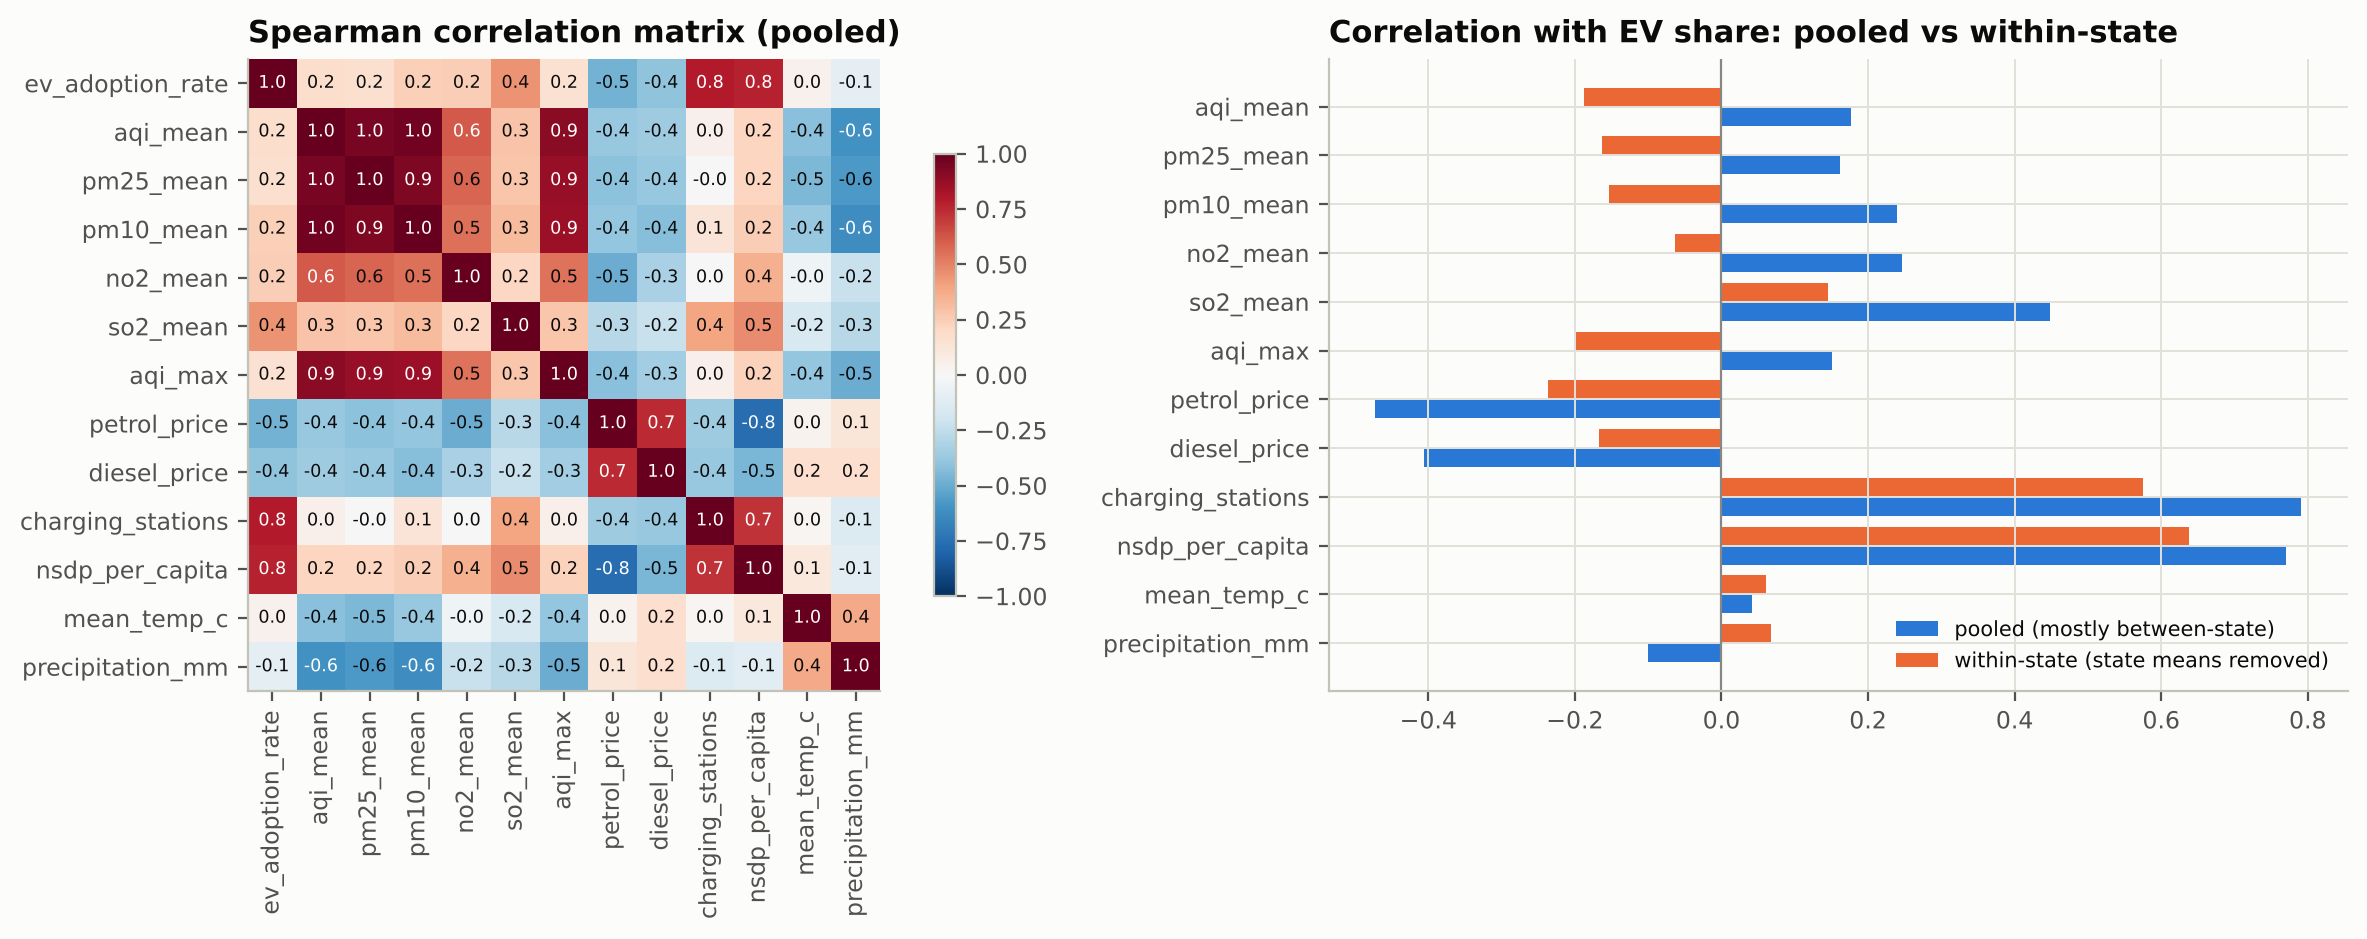

  [figure] outputs/figures/fig07_correlation_pooled_vs_within.png


Manually dropped: {'aqi_max': 'within-month extreme of the same AQI index; adds noise, not information'}
Pruning history:
     dropped  its_VIF  max_VIF_before
   pm10_mean     21.3            28.4
   pm25_mean     16.5            18.7
diesel_price      9.0            18.1

Final driver set and VIF:
aqi_mean             3.29
no2_mean             1.81
so2_mean             1.48
petrol_price         2.83
charging_stations    1.75
nsdp_per_capita      4.27
mean_temp_c          1.98
precipitation_mm     1.25
  [table]  outputs/tables/02_vif_pruning_history.csv
  [table]  outputs/tables/02_vif_final.csv
             ADF_p (log rate, trend)  KPSS_p (log rate, trend)  ADF_p (diff log rate)  seasonal_strength  trend_strength
state                                                                                                                   
Delhi                          0.003                     0.100                  0.000              0.635           0.482
Maharashtra                    0

/tmp/ipykernel_191/3655962188.py:115: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_p = kpss(ly, regression="ct", nlags="auto")[1]
/tmp/ipykernel_191/3655962188.py:115: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_p = kpss(ly, regression="ct", nlags="auto")[1]
/tmp/ipykernel_191/3655962188.py:115: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_p = kpss(ly, regression="ct", nlags="auto")[1]


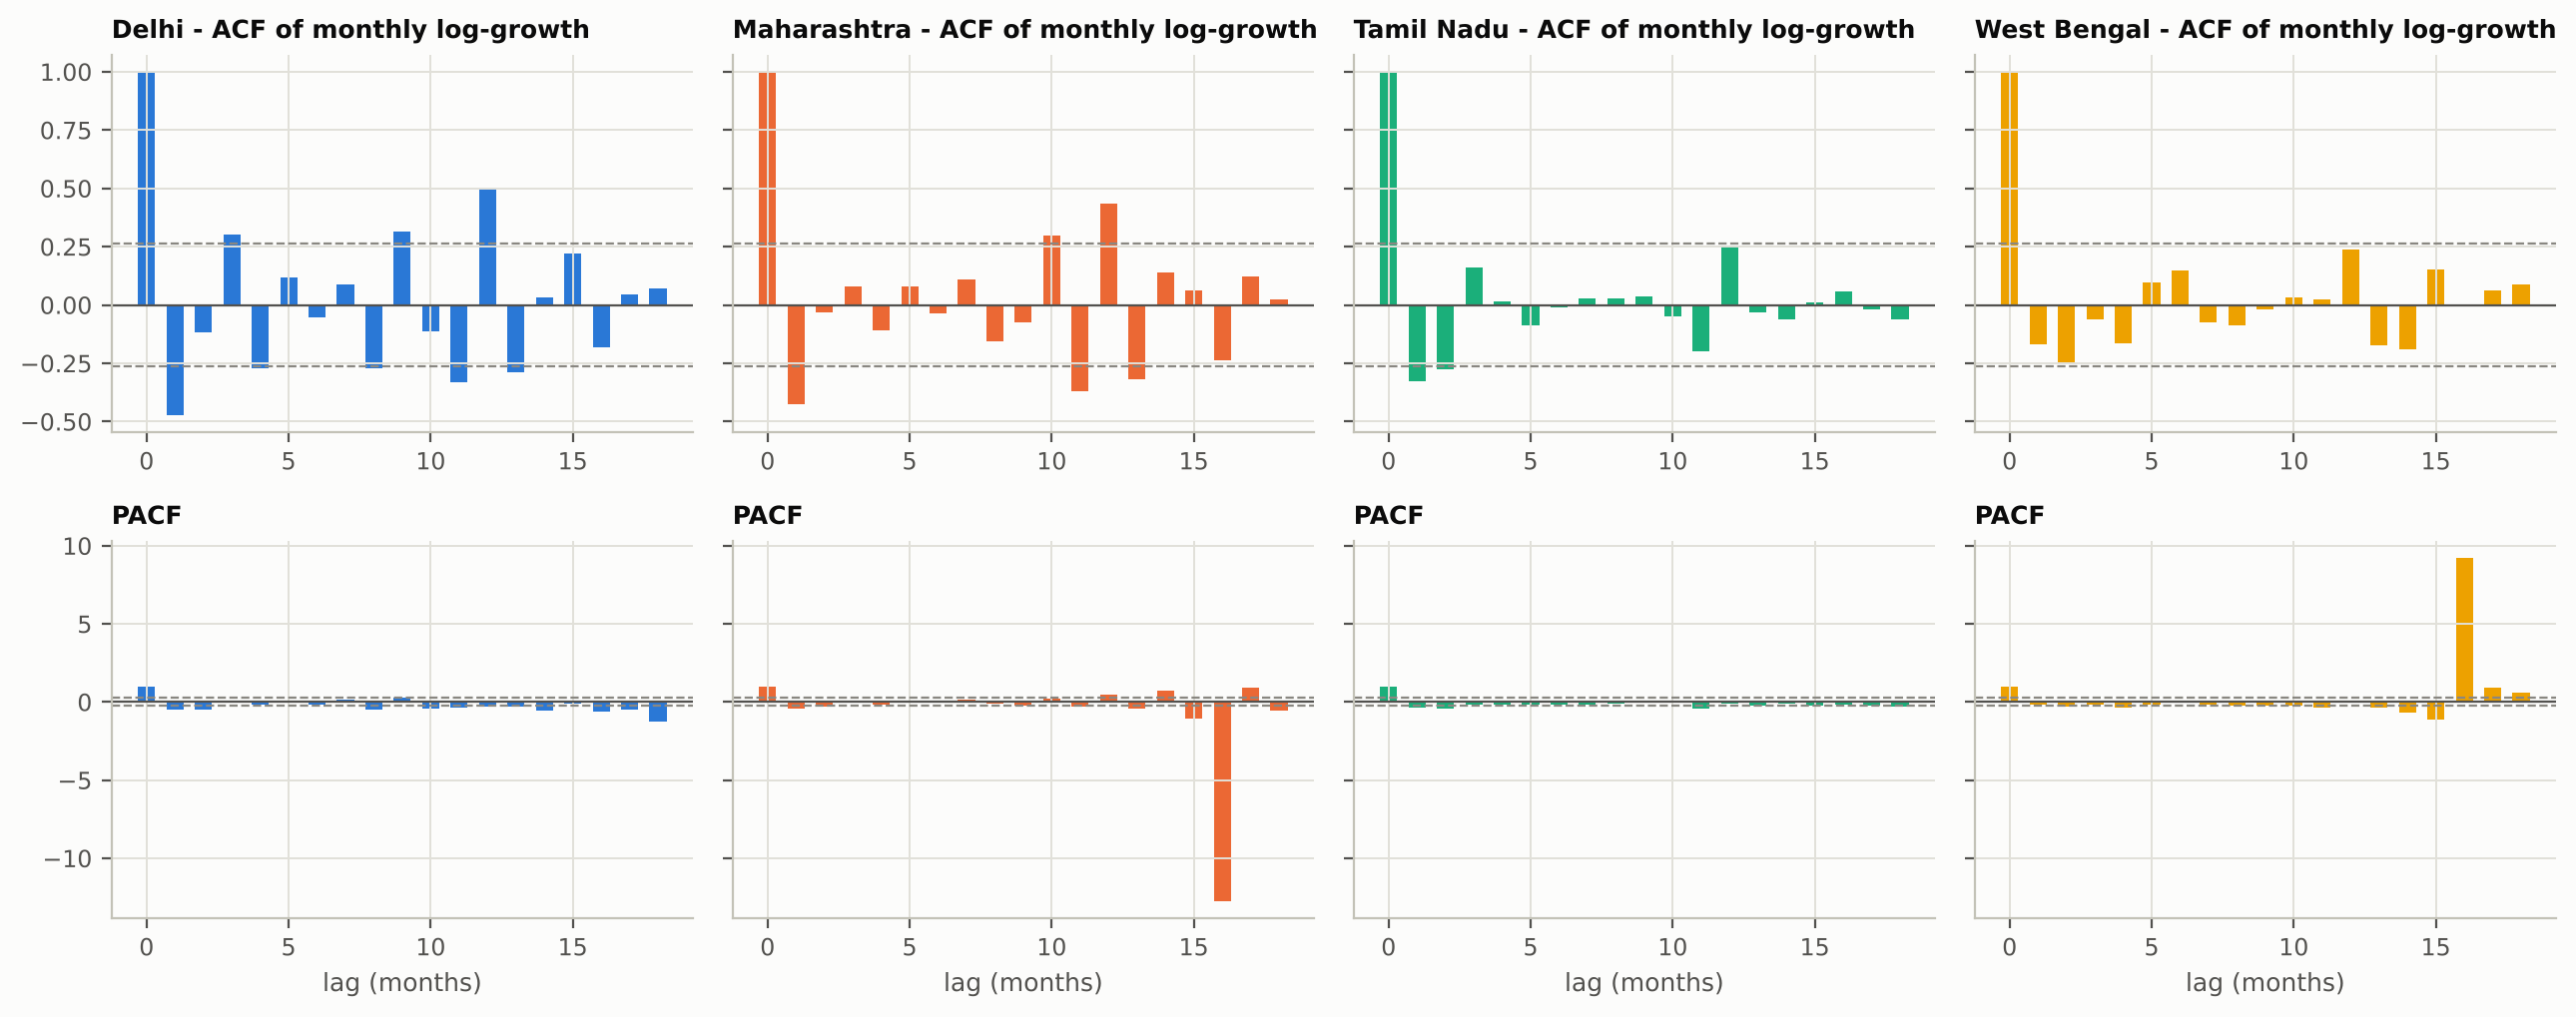

  [figure] outputs/figures/fig08_acf_pacf.png


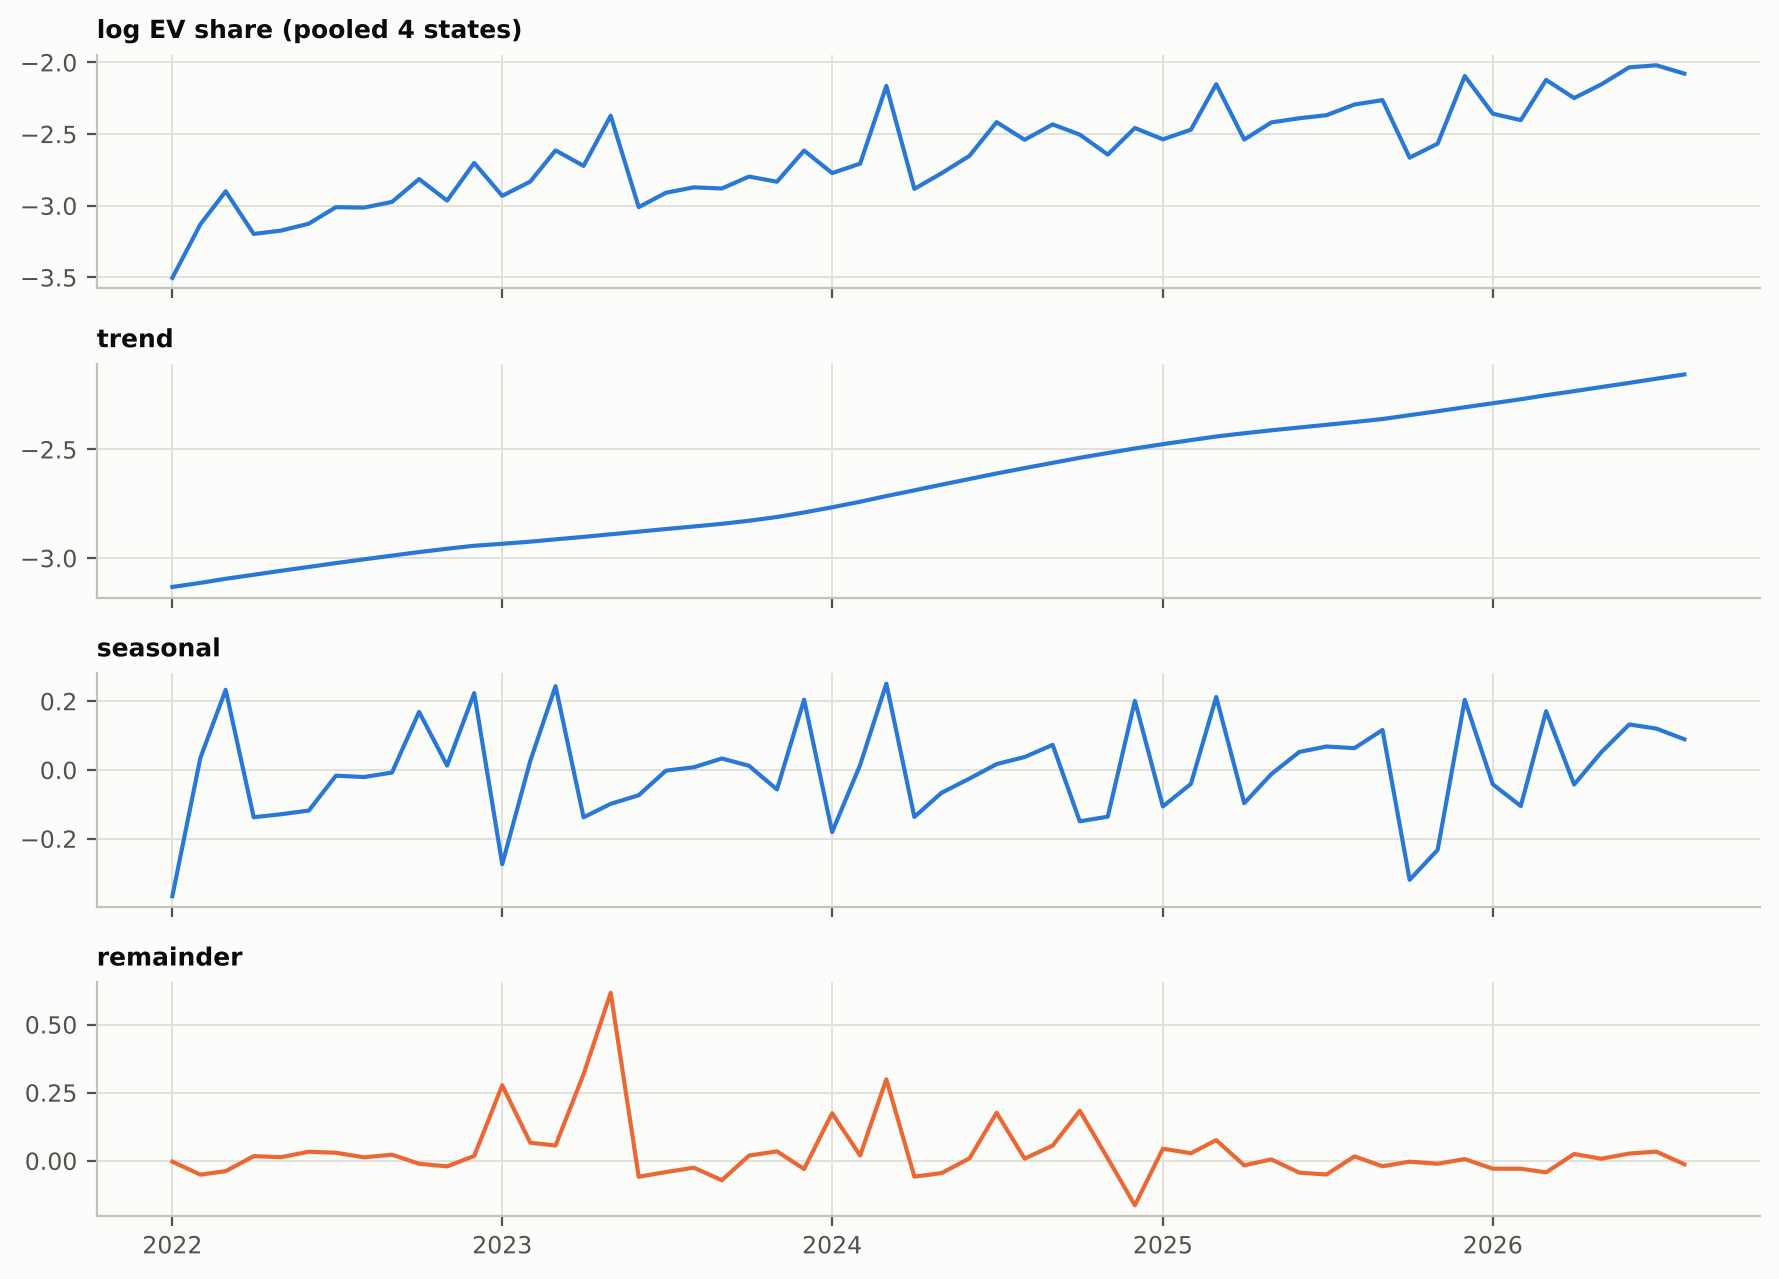

  [figure] outputs/figures/fig09_stl_decomposition.png
Multiplicative seasonal index by calendar month (1 = average):
date
1     0.82
2     0.99
3     1.25
4     0.90
5     0.95
6     0.99
7     1.04
8     1.04
9     1.06
10    0.93
11    0.90
12    1.23
  [table]  outputs/tables/02_pooled_seasonal_index.csv
  [json]   outputs/tables/02_selected_features_and_protocol.json
{
  "target": "ev_adoption_rate",
  "selected_drivers": [
    "aqi_mean",
    "no2_mean",
    "so2_mean",
    "petrol_price",
    "charging_stations",
    "nsdp_per_capita",
    "mean_temp_c",
    "precipitation_mm"
  ],
  "calendar_features": [
    "month_sin",
    "month_cos",
    "fy_end"
  ],
  "excluded_for_leakage": [
    "alternative",
    "diesel",
    "electric",
    "ev_count",
    "four_wheeler",
    "gas",
    "heavy_vehicle",
    "hybrid",
    "light_vehicle",
    "lpg",
    "medium_vehicle",
    "not_applicable",
    "other",
    "petrol",
    "three_wheeler",
    "two_wheeler",
    "vehicle_total"
  ],


In [5]:
from common import *

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.seasonal import STL
import statsmodels.api as sm

df = load_data()

# ## 1. Leakage audit

roles = []
for c in df.columns:
    if c == TARGET:
        role, why = "TARGET", "EV share of new registrations in the state-month"
    elif c in LEAKY_COLS:
        role, why = "EXCLUDED (leakage)", LEAKY_COLS[c]
    elif c in CANDIDATE_DRIVERS:
        role, why = "candidate driver", COL_TO_GROUP[c]
    elif c in ("state", "date", "year", "month", "month_name", "quarter", "season", "month_index", "t",
               "month_sin", "month_cos", "fy_end", "anomaly_flag"):
        role, why = "id / calendar", "known in advance"
    elif c == "dominant_pollutant":
        role, why = "EXCLUDED", "categorical label derived from the pollutants already used"
    else:
        role, why = "unclassified", ""
    roles.append({"column": c, "role": role, "note": why})
roles = pd.DataFrame(roles)
print(roles.role.value_counts().to_string())
save_table(roles, "02_leakage_and_role_audit", index=False)

# ## 2. Between- vs within-state variance of every driver
# A driver that is (almost) constant *within* each state can only be learned from the 4 state-level
# differences - i.e. effectively 4 data points. This sets the limit of what "driver importance" can mean.

def variance_split(col):
    tot = df[col].var(ddof=0)
    between = df.groupby("state")[col].transform("mean").var(ddof=0)
    return between / tot

vs = pd.DataFrame({c: {"between_state_share_%": 100 * variance_split(c)} for c in [TARGET] + CANDIDATE_DRIVERS}).T
vs["within_state_share_%"] = 100 - vs["between_state_share_%"]
vs["distinct_values_per_state"] = [df.groupby("state")[c].nunique().median() for c in vs.index]
vs = vs.sort_values("between_state_share_%", ascending=False)
print(vs.round(1).to_string())
save_table(vs.round(2), "02_between_within_variance")

# ## 3. Correlation structure and multicollinearity

set_style()
corr_cols = [TARGET] + CANDIDATE_DRIVERS
pooled = df[corr_cols].corr(method="spearman")[TARGET].drop(TARGET)
demeaned = df[corr_cols] - df.groupby("state")[corr_cols].transform("mean")   # remove state effects
within = demeaned.corr(method="spearman")[TARGET].drop(TARGET)
cmp = pd.DataFrame({"pooled_spearman": pooled, "within_state_spearman": within}).loc[CANDIDATE_DRIVERS]
print(cmp.round(2).to_string())
save_table(cmp.round(3), "02_pooled_vs_within_correlation")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.05, 1]})
cm = df[corr_cols].corr(method="spearman")
im = axes[0].imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
axes[0].set_xticks(range(len(cm)), cm.columns, rotation=90); axes[0].set_yticks(range(len(cm)), cm.columns)
for i in range(len(cm)):
    for j in range(len(cm)):
        axes[0].text(j, i, f"{cm.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6.3,
                     color="white" if abs(cm.iloc[i, j]) > 0.6 else INK)
axes[0].grid(False); axes[0].set_title("Spearman correlation matrix (pooled)")
fig.colorbar(im, ax=axes[0], shrink=0.7)
yy = np.arange(len(cmp))
axes[1].barh(yy + 0.2, cmp.pooled_spearman, 0.38, color="#2a78d6", label="pooled (mostly between-state)")
axes[1].barh(yy - 0.2, cmp.within_state_spearman, 0.38, color="#eb6834", label="within-state (state means removed)")
axes[1].set_yticks(yy, cmp.index); axes[1].invert_yaxis(); axes[1].axvline(0, color=MUTED, lw=0.8)
axes[1].set_title("Correlation with EV share: pooled vs within-state"); axes[1].legend(loc="lower right", fontsize=7.5)
fig.tight_layout()
save_fig(fig, "fig07_correlation_pooled_vs_within")

# ### Variance Inflation Factor (VIF) and iterative pruning
# AQI, PM2.5, PM10 and AQI-max are near-duplicates; petrol/diesel move together. Features are removed one at a
# time (highest VIF first) until all VIF < 10, **but** a priority order protects the business-critical drivers.

PROTECT = ["charging_stations", "petrol_price", "nsdp_per_capita", "aqi_mean"]   # keep these if at all possible


def vif_table(X: pd.DataFrame) -> pd.Series:
    Xc = sm.add_constant((X - X.mean()) / X.std())
    return pd.Series([variance_inflation_factor(Xc.values, i + 1) for i in range(X.shape[1])], index=X.columns)


MANUAL_DROP = {"aqi_max": "within-month extreme of the same AQI index; adds noise, not information"}
kept = [c for c in CANDIDATE_DRIVERS if c not in MANUAL_DROP]
history = []
while True:
    v = vif_table(df[kept])
    if v.max() < 10:
        break
    cand = v.drop(PROTECT, errors="ignore").sort_values(ascending=False)
    drop = cand.index[0]
    history.append({"dropped": drop, "its_VIF": round(v[drop], 1), "max_VIF_before": round(v.max(), 1)})
    kept.remove(drop)
final_vif = vif_table(df[kept]).round(2)
print("Manually dropped:", MANUAL_DROP)
print("Pruning history:"); print(pd.DataFrame(history).to_string(index=False))
print("\nFinal driver set and VIF:"); print(final_vif.to_string())
save_table(pd.DataFrame(history), "02_vif_pruning_history", index=False)
save_table(final_vif.to_frame("VIF"), "02_vif_final")

# ## 4. Time-series diagnostics of the target

rows = []
for s, g in df.groupby("state"):
    y = g.set_index("date")[TARGET]
    ly = np.log(y)
    adf_p = adfuller(ly, regression="ct", autolag="AIC")[1]
    adf_d = adfuller(ly.diff().dropna(), regression="c", autolag="AIC")[1]
    kpss_p = kpss(ly, regression="ct", nlags="auto")[1]
    stl = STL(ly, period=12, robust=True).fit()
    Fs = max(0, 1 - stl.resid.var() / (stl.resid + stl.seasonal).var())        # Hyndman seasonal strength
    Ft = max(0, 1 - stl.resid.var() / (stl.resid + stl.trend).var())          # trend strength
    rows.append({"state": s, "ADF_p (log rate, trend)": adf_p, "KPSS_p (log rate, trend)": kpss_p,
                 "ADF_p (diff log rate)": adf_d, "seasonal_strength": Fs, "trend_strength": Ft})
ts_diag = pd.DataFrame(rows).set_index("state").round(3)
print(ts_diag.to_string())
print("\nReading: ADF rejects a unit root once a deterministic trend is allowed (p<0.05) and KPSS does not reject trend-stationarity"
      "\nfor most states -> each series is a steadily rising trend plus seasonality. With only ~56 points per state both tests have low"
      "\npower, so the differencing order of SARIMA is chosen by AIC in stage 04 rather than fixed here.")
save_table(ts_diag, "02_timeseries_diagnostics")

fig, axes = plt.subplots(2, 4, figsize=(13, 5.2), sharey="row")
for j, s in enumerate(STATES):
    y = np.log(df[df.state == s].set_index("date")[TARGET]).diff().dropna()      # growth-rate series
    a = acf(y, nlags=18); p = pacf(y, nlags=18)
    conf = 1.96 / np.sqrt(len(y))
    for ax, vals, name in ((axes[0, j], a, "ACF"), (axes[1, j], p, "PACF")):
        ax.bar(range(len(vals)), vals, color=STATE_COLORS[s], width=0.6)
        ax.axhline(conf, color=MUTED, ls="--", lw=0.8); ax.axhline(-conf, color=MUTED, ls="--", lw=0.8)
        ax.axhline(0, color=INK2, lw=0.8)
        ax.set_title(f"{s} - {name} of monthly log-growth" if name == "ACF" else f"{name}", fontsize=9)
    axes[1, j].set_xlabel("lag (months)")
fig.tight_layout()
save_fig(fig, "fig08_acf_pacf")

# STL decomposition of the 4-state pooled EV share
pooled_rate = df.groupby("date").apply(lambda g: g.ev_count.sum() / g.vehicle_total.sum())
stl = STL(np.log(pooled_rate), period=12, robust=True).fit()
fig, axes = plt.subplots(4, 1, figsize=(9, 6.5), sharex=True)
for ax, (nm, ser) in zip(axes, [("log EV share (pooled 4 states)", np.log(pooled_rate)), ("trend", stl.trend),
                                 ("seasonal", stl.seasonal), ("remainder", stl.resid)]):
    ax.plot(ser.index, ser.values, color="#2a78d6" if nm != "remainder" else "#eb6834", lw=1.5)
    ax.set_title(nm, fontsize=9)
fig.tight_layout()
save_fig(fig, "fig09_stl_decomposition")

seas_idx = np.exp(stl.seasonal.groupby(stl.seasonal.index.month).mean())
print("Multiplicative seasonal index by calendar month (1 = average):")
print(seas_idx.round(2).to_string())
save_table(seas_idx.rename("seasonal_index").to_frame(), "02_pooled_seasonal_index")

# ## 5. Final modelling set-up (documented decisions)

SELECTED_DRIVERS = kept
protocol = {
    "target": TARGET,
    "selected_drivers": SELECTED_DRIVERS,
    "calendar_features": ["month_sin", "month_cos", "fy_end"],
    "excluded_for_leakage": sorted(LEAKY_COLS),
    "data_cutoff": f"{COVARIATE_CUTOFF:%Y-%m}",
    "tuning_period": f"{df.date.min():%Y-%m} .. {TRAIN_END:%Y-%m} (hyper-parameters are tuned here and then frozen)",
    "out_of_sample_period": f"{TEST_START:%Y-%m} .. {COVARIATE_CUTOFF:%Y-%m} ({int(df.date.between(TEST_START, COVARIATE_CUTOFF).sum() / 4)} months x 4 states)",
    "flagged_observations": f"{ANOMALY_STATE} {ANOMALY_START:%Y-%m} .. {ANOMALY_END:%Y-%m} surge episode (metrics reported with and without)",
    "cv_scheme": "expanding-window time-series CV inside the training period only (no shuffling)",
    "random_seed": SEED,
}
save_json(protocol, "02_selected_features_and_protocol")
print(json.dumps(protocol, indent=2))



## `03_explanatory_model_shap.py`
03_explanatory_model_shap.py -- Stage 03: explanatory models (SHAP) and fixed-effects triangulation - RETROSPECTIVE layer
Run from the project root:  python 03_explanatory_model_shap.py

Features: ['aqi_mean', 'no2_mean', 'so2_mean', 'petrol_price', 'charging_stations', 'nsdp_per_capita', 'mean_temp_c', 'precipitation_mm', 'month_sin', 'month_cos', 'fy_end']
train rows=144  test rows=80


              cv_MAE_pp                                                                                                                                                                            best_params
model                                                                                                                                                                                                         
Ridge          1.501751                                                                                                                                                                     {'alpha': 29.1544}
RandomForest   1.464738                                                                                                   {'max_depth': 5, 'max_features': 0.4732, 'min_samples_leaf': 9, 'n_estimators': 234}
XGBoost        1.505777                           {'colsample_bytree': 0.6101, 'learning_rate': 0.1028, 'max_depth': 4, 'min_child_weight': 3, 'n_estimators': 247, 'reg_lam

                              holdout_MAE_pp (all)  holdout_MAE_pp (excl. flagged)  holdout_R2 (excl. flagged)  holdout_sMAPE_% (excl. flagged)  LOSO_MAE_pp  LOSO_R2
model                                                                                                                                                                
Ridge                                        2.952                           2.484                       0.202                           27.585        2.280    0.469
RandomForest                                 3.007                           2.599                       0.126                           26.280        3.262    0.009
XGBoost                                      2.929                           2.539                       0.128                           26.914        2.956    0.115
LightGBM                                     2.905                           2.509                       0.185                           24.981        2.905    0.166
Refe

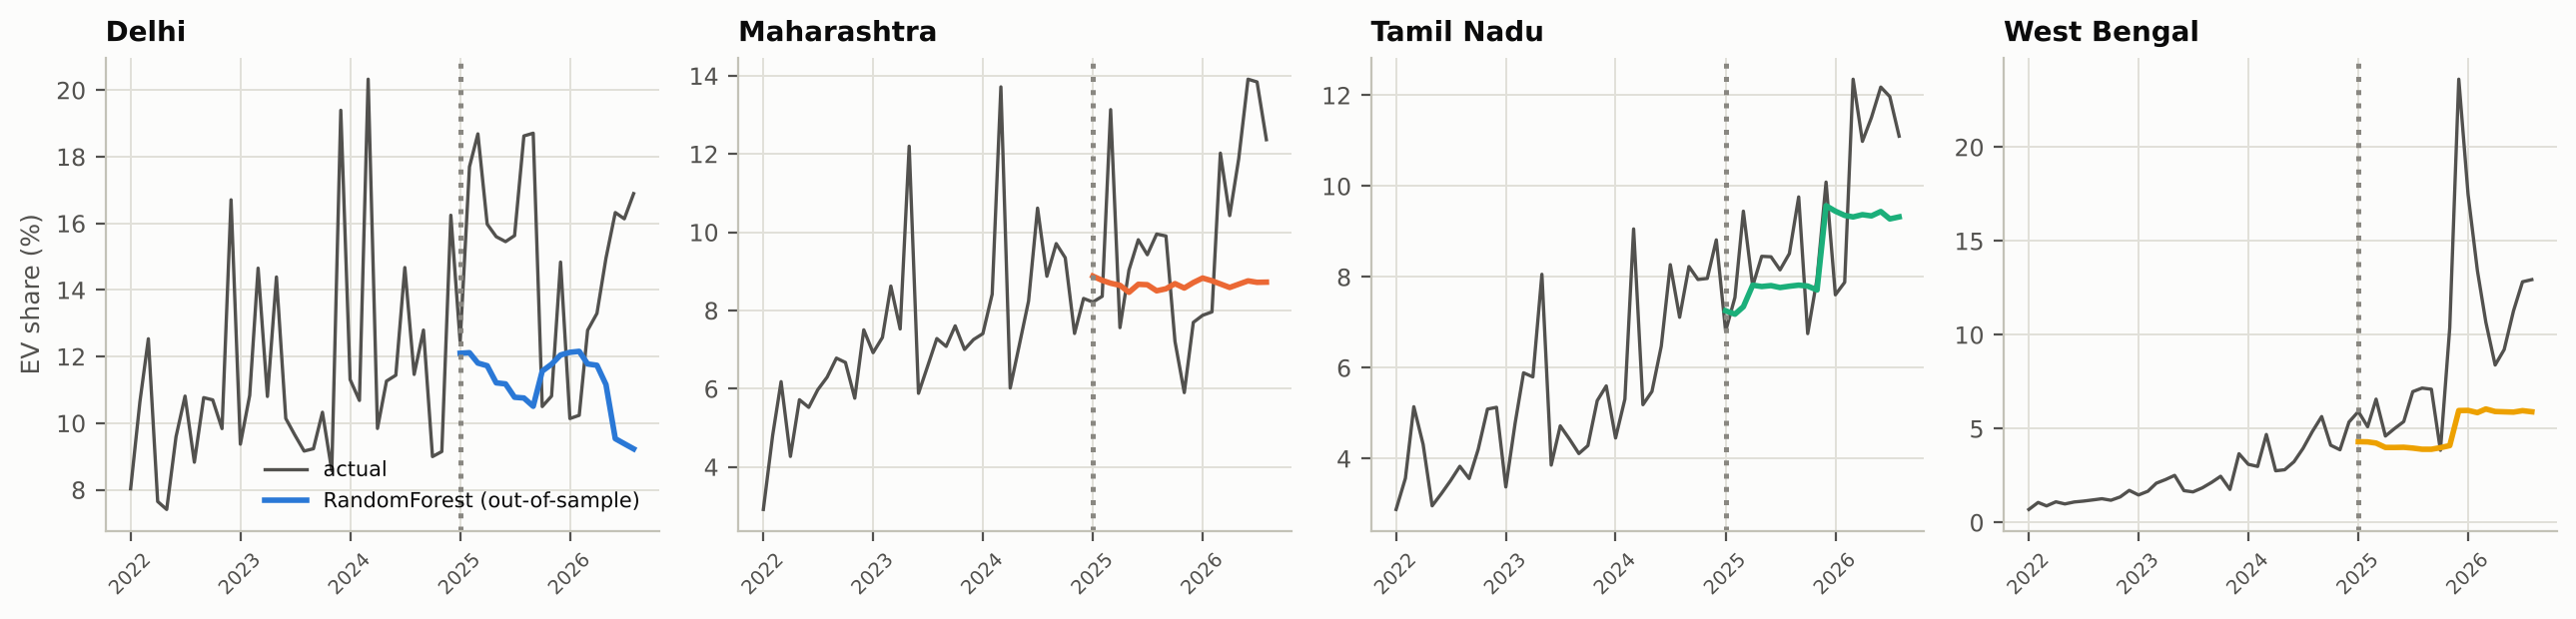

  [figure] outputs/figures/fig10_explanatory_holdout_fit.png


Base value (average prediction) = 8.10 %;  additivity check max err = 1.94e-16
charging_stations    2.166
nsdp_per_capita      0.658
petrol_price         0.356
so2_mean             0.206
no2_mean             0.189
aqi_mean             0.100
mean_temp_c          0.044
precipitation_mm     0.034
month_cos            0.030
month_sin            0.027
fy_end               0.004

Charging infrastructure    2.166
Income                     0.658
Air quality                0.495
Fuel prices                0.356
Weather                    0.077
Seasonality                0.061
  [table]  outputs/tables/03_shap_global_importance.csv
  [table]  outputs/tables/03_shap_group_importance.csv

Share of each feature's SHAP variance that is explained by state identity alone:
                   mean_|SHAP|_pp  between_state_share_of_SHAP_variance_%
charging_stations             2.2                                    54.6
nsdp_per_capita               0.7                                    70.2
petrol_pri

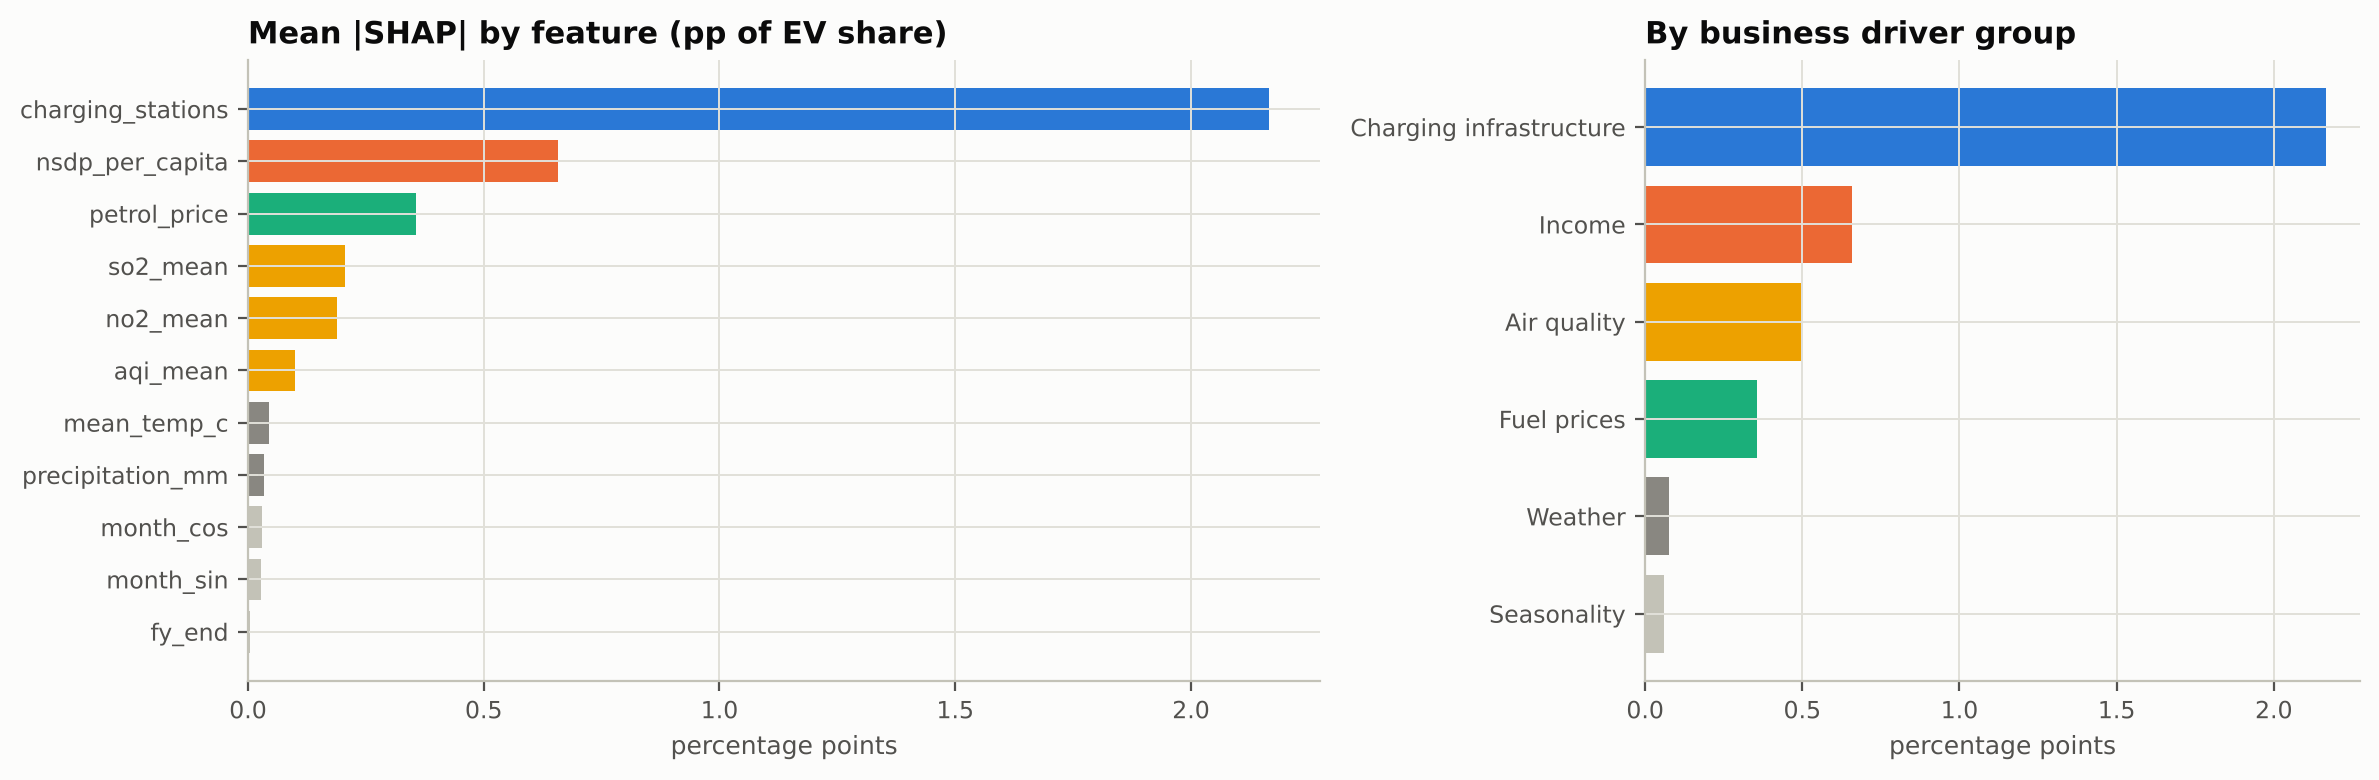

  [figure] outputs/figures/fig11_shap_global_importance.png


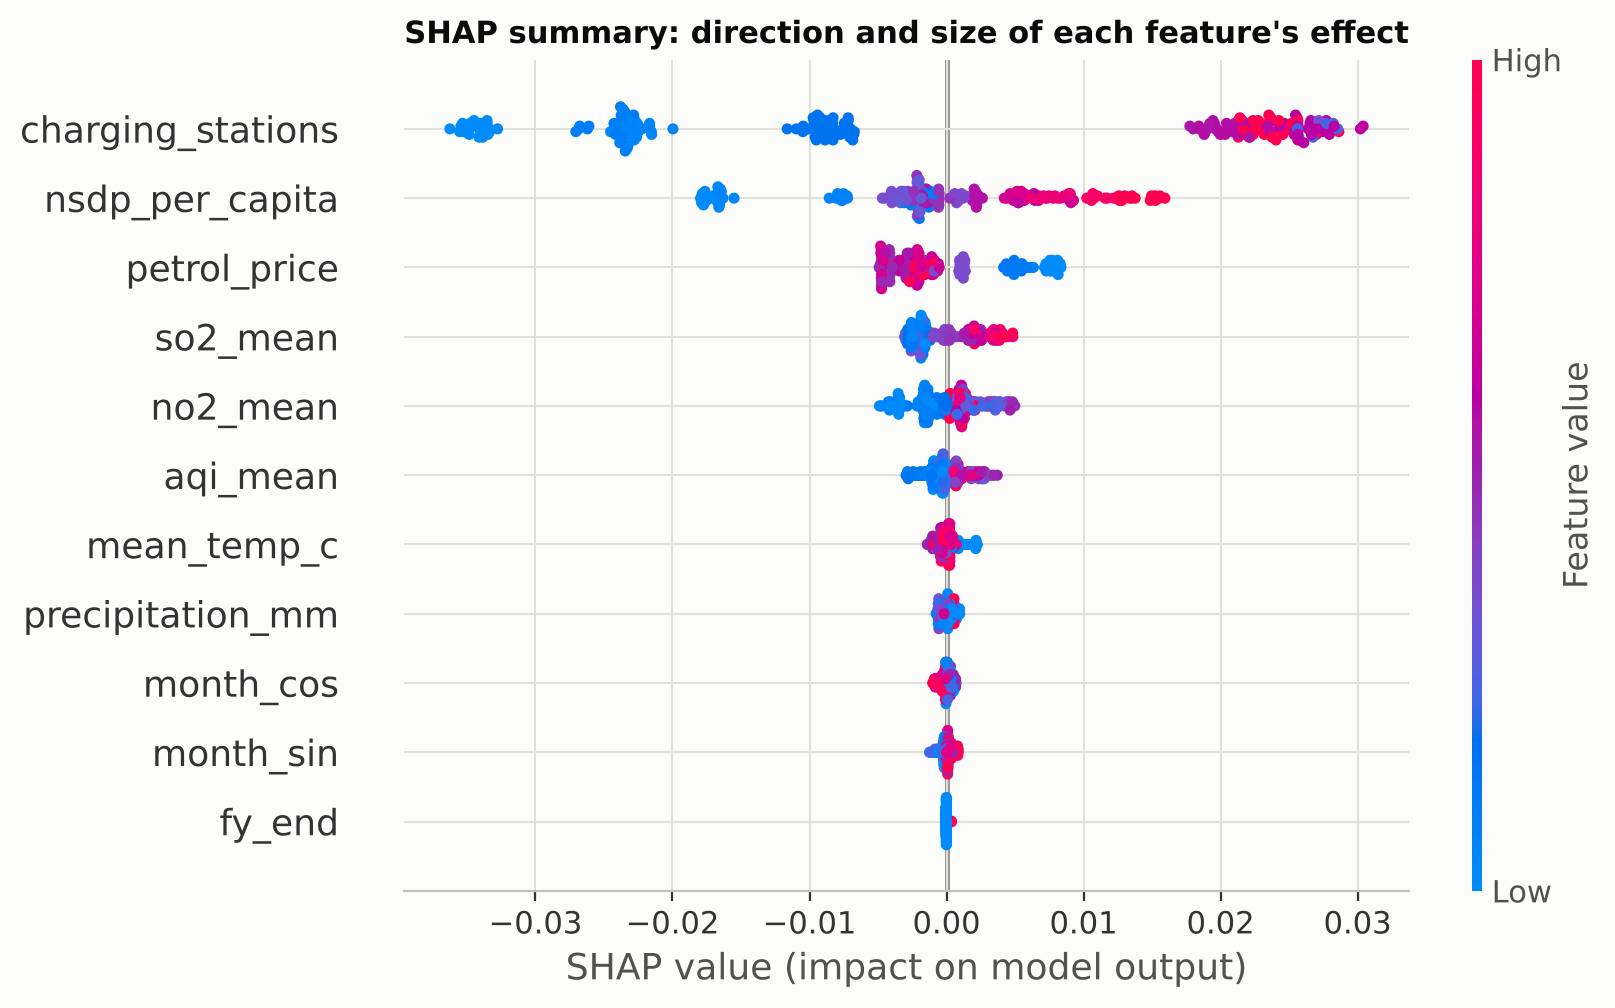

  [figure] outputs/figures/fig12_shap_beeswarm.png


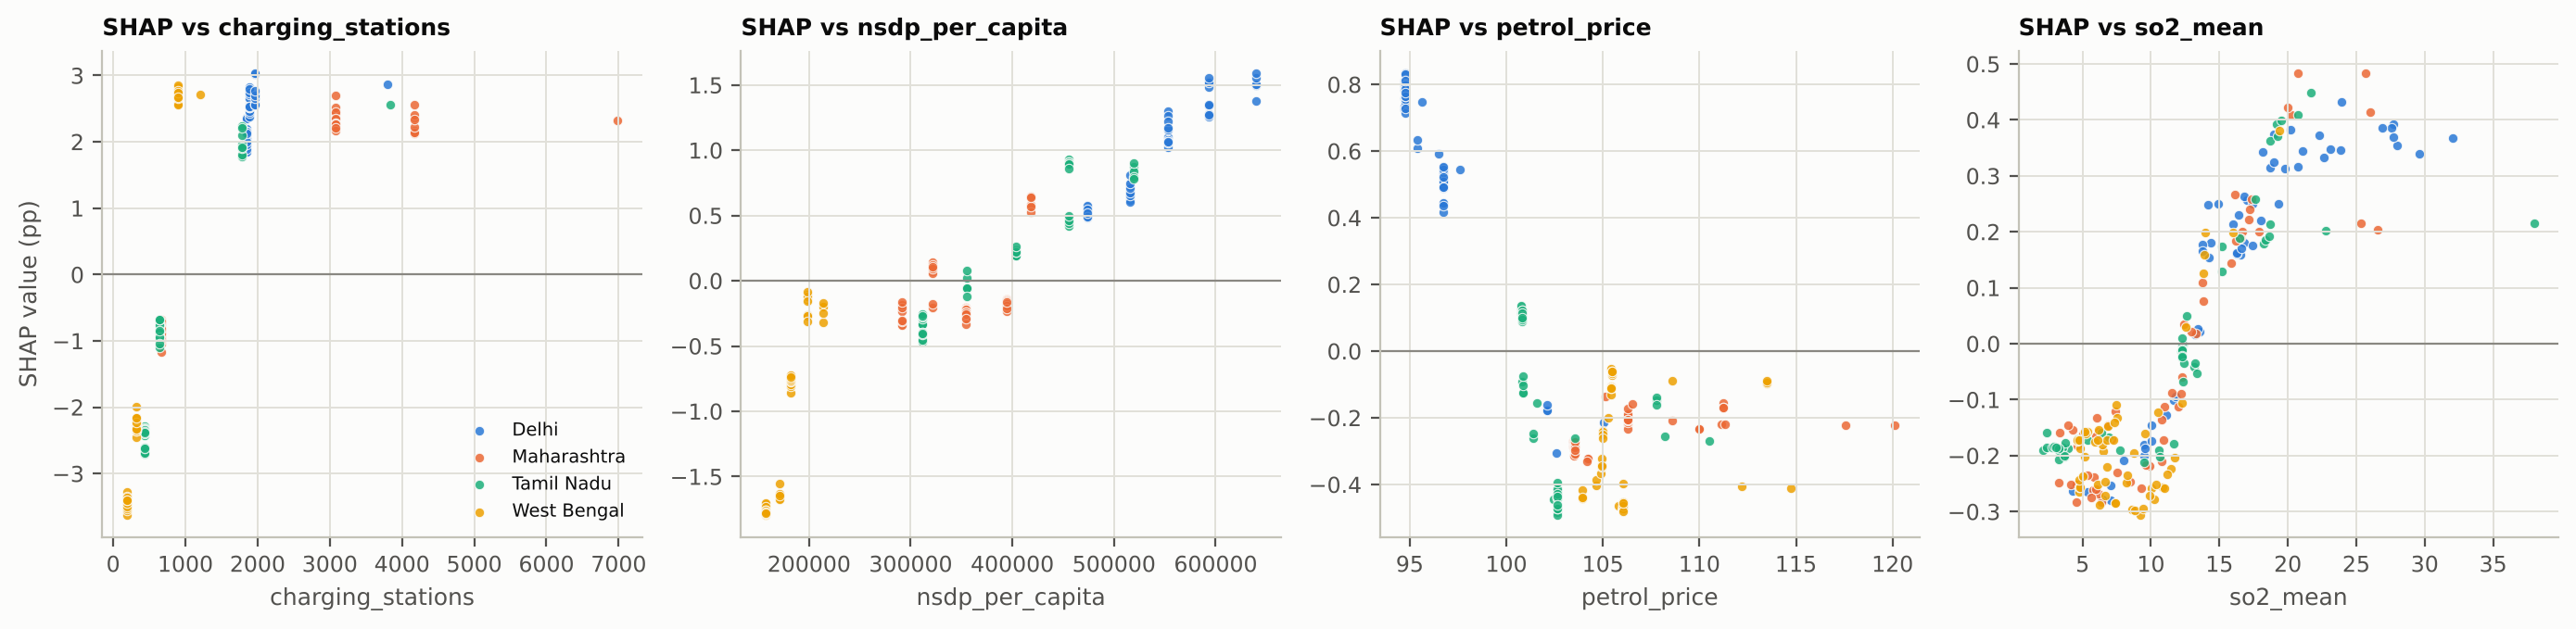

  [figure] outputs/figures/fig13_shap_dependence.png


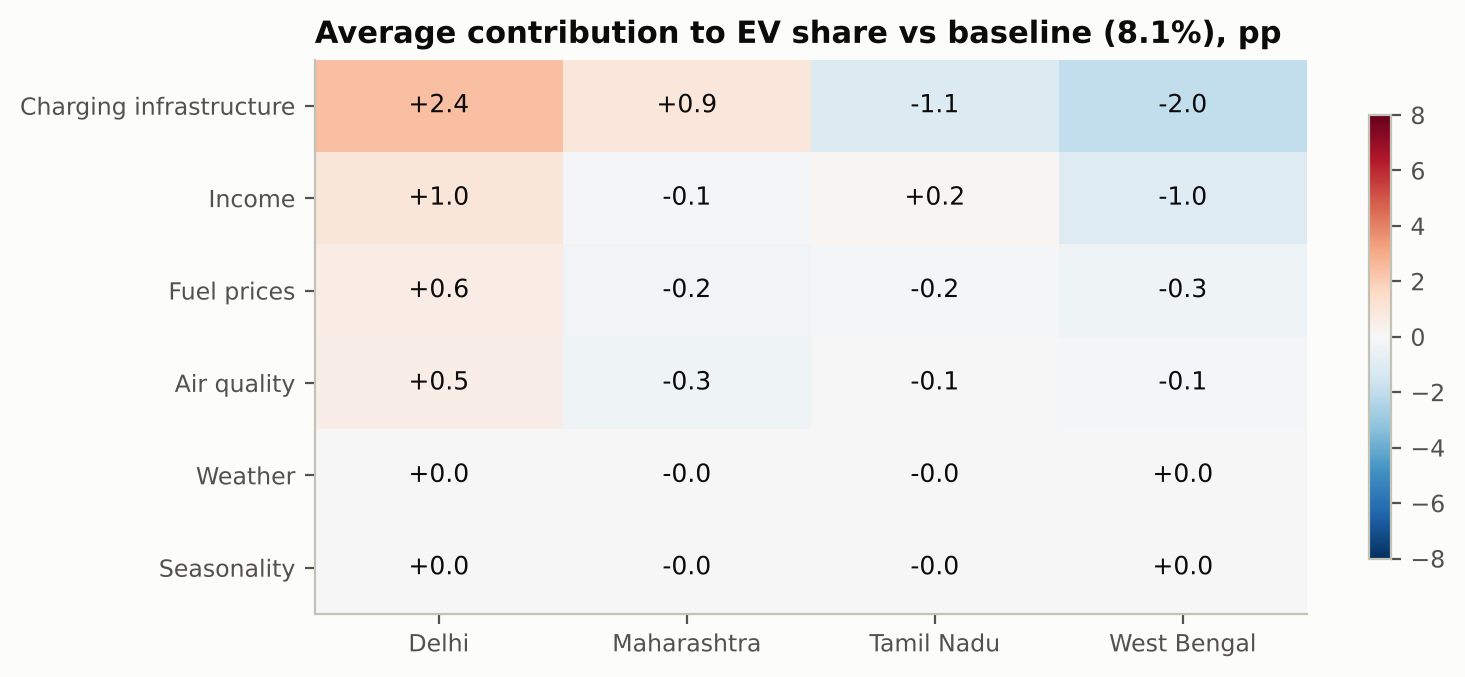

  [figure] outputs/figures/fig14_state_contribution_heatmap.png
  [table]  outputs/tables/03_state_group_contributions.csv
state                    Delhi  Maharashtra  Tamil Nadu  West Bengal
Charging infrastructure   2.38         0.89       -1.08        -1.99
Income                    0.97        -0.09        0.18        -1.04
Fuel prices               0.57        -0.24       -0.17        -0.32
Air quality               0.52        -0.33       -0.06        -0.12
Weather                   0.01        -0.01       -0.03         0.00
Seasonality               0.00        -0.00       -0.00         0.00


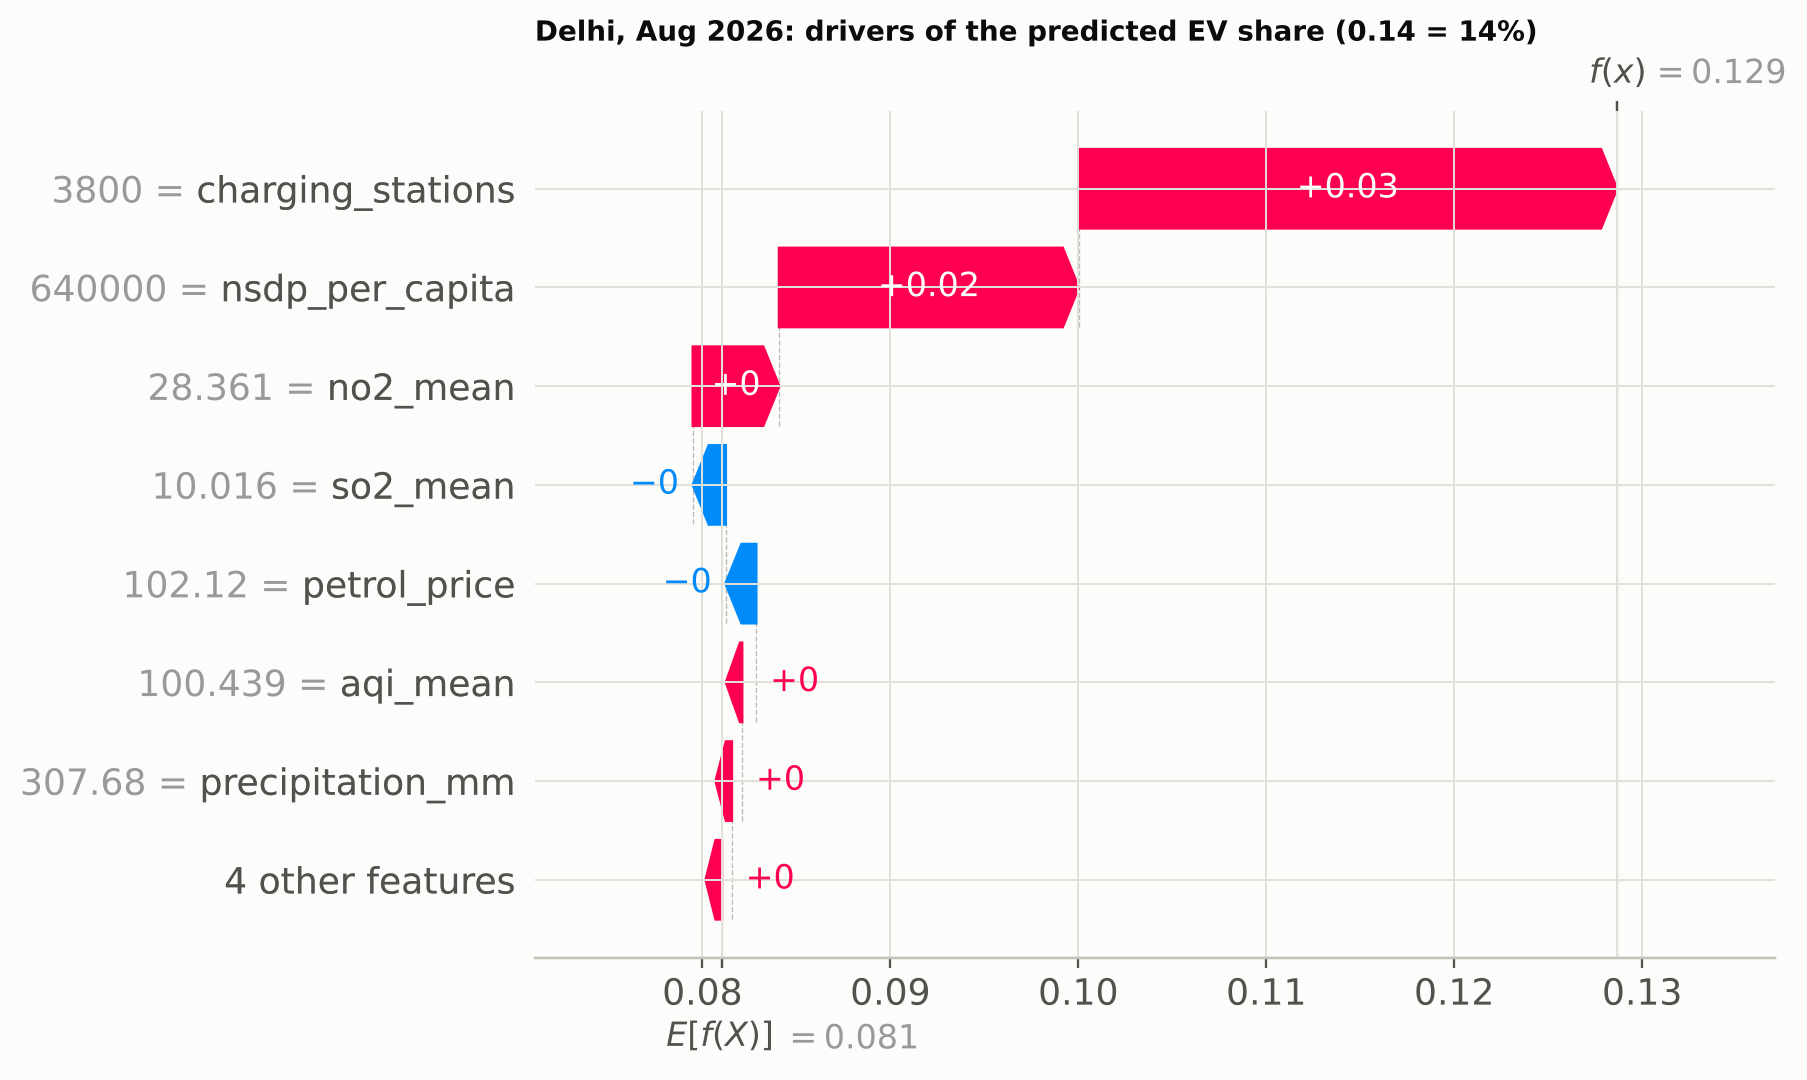

  [figure] outputs/figures/fig15a_waterfall_delhi.png


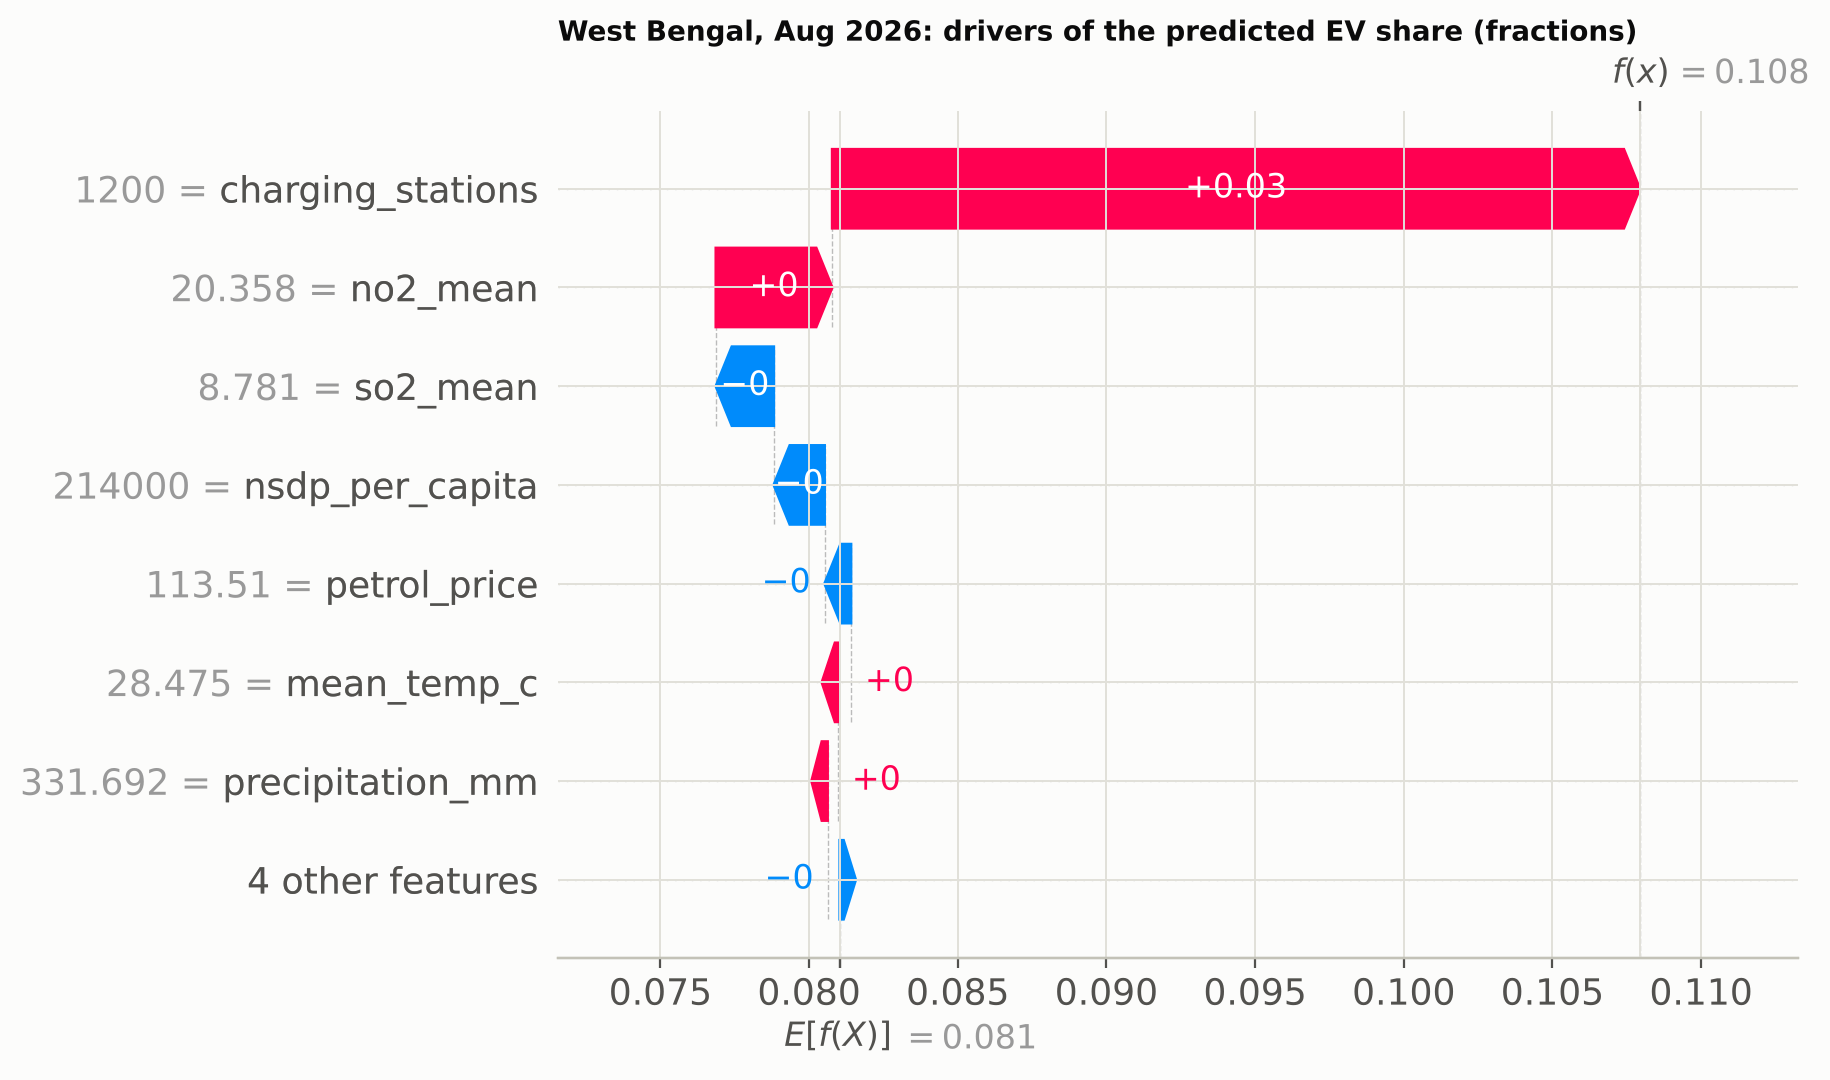

  [figure] outputs/figures/fig15b_waterfall_wb.png


                             spearman_vs_full_fit                                              top3
train-period model (2022-24)             0.972727  charging_stations, nsdp_per_capita, petrol_price
without Delhi                            0.963636      charging_stations, nsdp_per_capita, so2_mean
without Maharashtra                      0.972727  charging_stations, nsdp_per_capita, petrol_price
without Tamil Nadu                       0.990909  charging_stations, nsdp_per_capita, petrol_price
without West Bengal                      0.972727  charging_stations, nsdp_per_capita, petrol_price
  [table]  outputs/tables/03_shap_stability.csv
Spec A: drivers + state FE + month FE:  R2 = 0.718, n = 220
Spec B: A + linear time trend:  R2 = 0.889, n = 220
                                    pct_change_per_+1SD                                                             p_value                              
spec              Spec A: drivers + state FE + month FE Spec B: A + linear time trend 

PosixPath('/home/claude/ev_adoption_project/outputs/tables/03_summary.json')

In [6]:
from common import *

import shap
import lightgbm as lgb
import xgboost as xgb
from scipy.stats import spearmanr, randint, uniform, loguniform
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import statsmodels.formula.api as smf

df = load_data()
protocol = json.loads((TAB_DIR / "02_selected_features_and_protocol.json").read_text())
DRIVERS = protocol["selected_drivers"]
CAL = protocol["calendar_features"]
FEATURES = DRIVERS + CAL
print("Features:", FEATURES)

train = df[df.date <= TRAIN_END].reset_index(drop=True)
test = df[(df.date >= TEST_START) & (df.date <= COVARIATE_CUTOFF)].reset_index(drop=True)
print(f"train rows={len(train)}  test rows={len(test)}")

# ## 1. Time-aware hyper-parameter search (training period only)
# Three expanding-window folds: validate on 2023-H2, 2024-H1, 2024-H2, always training on the past.

def time_folds(frame: pd.DataFrame):
    cuts = [("2023-07-01", "2023-12-01"), ("2024-01-01", "2024-06-01"), ("2024-07-01", "2024-12-01")]
    folds = []
    for a, b in cuts:
        tr = frame.index[frame.date < a].to_numpy()
        va = frame.index[(frame.date >= a) & (frame.date <= b)].to_numpy()
        folds.append((tr, va))
    return folds


folds = time_folds(train)
Xtr, ytr = train[FEATURES], train[TARGET]

search_space = {
    "Ridge": (make_pipeline(StandardScaler(), Ridge()), {"ridge__alpha": loguniform(1e-2, 1e2)}, 25),
    "RandomForest": (RandomForestRegressor(random_state=SEED, n_jobs=-1),
                     {"n_estimators": randint(200, 600), "max_depth": randint(2, 8),
                      "min_samples_leaf": randint(2, 12), "max_features": uniform(0.4, 0.6)}, 30),
    "XGBoost": (xgb.XGBRegressor(random_state=SEED, n_jobs=1, objective="reg:squarederror"),
                {"n_estimators": randint(100, 500), "max_depth": randint(2, 5), "learning_rate": loguniform(0.02, 0.2),
                 "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.5, 0.5),
                 "min_child_weight": randint(1, 8), "reg_lambda": loguniform(0.1, 20)}, 40),
    "LightGBM": (lgb.LGBMRegressor(random_state=SEED, n_jobs=1, verbose=-1),
                 {"n_estimators": randint(100, 500), "num_leaves": randint(4, 20), "learning_rate": loguniform(0.02, 0.2),
                  "subsample": uniform(0.6, 0.4), "subsample_freq": [1], "colsample_bytree": uniform(0.5, 0.5),
                  "min_child_samples": randint(4, 20), "reg_lambda": loguniform(0.1, 20)}, 40),
}
tuned, cv_rows = {}, []
for name, (est, space, n_iter) in search_space.items():
    rs = RandomizedSearchCV(est, space, n_iter=n_iter, cv=folds, scoring="neg_mean_absolute_error",
                            random_state=SEED, n_jobs=-1, refit=True).fit(Xtr, ytr)
    tuned[name] = rs.best_estimator_
    cv_rows.append({"model": name, "cv_MAE_pp": -100 * rs.best_score_,
                    "best_params": {k.split("__")[-1]: (round(float(v), 4) if isinstance(v, (float, np.floating)) else (int(v) if isinstance(v, (int, np.integer)) else v))
                                    for k, v in rs.best_params_.items()}})
cv_tab = pd.DataFrame(cv_rows).set_index("model")
print(cv_tab.to_string())
save_table(cv_tab.assign(best_params=cv_tab.best_params.astype(str)), "03_tuning_results")

# ## 2. Validation: chronological hold-out and leave-one-state-out

from sklearn.base import clone

res = []
preds_test = {}
for name, est in tuned.items():
    p = est.predict(test[FEATURES]); preds_test[name] = p
    d = pd.DataFrame({"y_true": test[TARGET], "y_pred": p, "flag": test.anomaly_flag})
    clean = d[d.flag == 0]
    # leave-one-state-out (train on 3 states over the training period, predict the 4th state's 2022-25)
    lo = []
    for s in STATES:
        m = clone(est).fit(df.loc[(df.state != s) & (df.date <= TRAIN_END), FEATURES],
                           df.loc[(df.state != s) & (df.date <= TRAIN_END), TARGET])
        sub = df[(df.state == s) & (df.anomaly_flag == 0)]
        lo.append(pd.DataFrame({"y_true": sub[TARGET], "y_pred": m.predict(sub[FEATURES])}))
    lo = pd.concat(lo)
    res.append({"model": name,
                "holdout_MAE_pp (all)": 100 * mae(d.y_true, d.y_pred),
                "holdout_MAE_pp (excl. flagged)": 100 * mae(clean.y_true, clean.y_pred),
                "holdout_R2 (excl. flagged)": r2(clean.y_true, clean.y_pred),
                "holdout_sMAPE_% (excl. flagged)": 100 * smape(clean.y_true, clean.y_pred),
                "LOSO_MAE_pp": 100 * mae(lo.y_true, lo.y_pred), "LOSO_R2": r2(lo.y_true, lo.y_pred)})
# reference: predict every out-of-sample month with the state's 2024 mean (what a trivial model would do)
ref = test.merge(train[train.year == 2024].groupby("state")[TARGET].mean().rename("ref"), on="state")
ref = ref[ref.anomaly_flag == 0]
res.append({"model": "Reference: state's 2024 mean", "holdout_MAE_pp (all)": np.nan,
            "holdout_MAE_pp (excl. flagged)": 100 * mae(ref[TARGET], ref.ref),
            "holdout_R2 (excl. flagged)": r2(ref[TARGET], ref.ref)})
val_tab = pd.DataFrame(res).set_index("model").round(3)
print(val_tab.to_string())
save_table(val_tab, "03_explanatory_validation")

# Model choice uses ONLY the training-period CV score (never the hold-out), so the hold-out stays an honest test.
best_name = cv_tab["cv_MAE_pp"].idxmin()
print(f"\nSelected explanatory model (lowest time-series-CV MAE on 2022-24): {best_name}")
print(f"  its hold-out MAE (excl. flagged) = {val_tab.loc[best_name, 'holdout_MAE_pp (excl. flagged)']:.2f} pp  vs  "
      f"reference {val_tab.loc[chr(82)+'eference: state' + chr(39) + 's 2024 mean', 'holdout_MAE_pp (excl. flagged)']:.2f} pp")

# ### Hold-out fit plot

set_style()
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=False)
for ax, s in zip(axes, STATES):
    g = df[df.state == s]
    ax.plot(g.date, 100 * g[TARGET], color=INK2, lw=1.2, label="actual")
    mt = test.state == s
    ax.plot(test.date[mt], 100 * preds_test[best_name][mt.values], color=STATE_COLORS[s], lw=2, label=f"{best_name} (out-of-sample)")
    ax.axvline(TEST_START, color=MUTED, ls=":")
    ax.set_title(s, fontsize=10); ax.tick_params(axis="x", labelrotation=45, labelsize=7)
axes[0].set_ylabel("EV share (%)"); axes[0].legend(fontsize=7.5)
fig.tight_layout()
save_fig(fig, "fig10_explanatory_holdout_fit")

# ## 3. SHAP explanations
# The model explains observations inside the range of history; it is refit on **all 192 state-months** for
# interpretation (standard practice for explanation; validation above is what justifies trusting it).

final_model = clone(tuned[best_name]).fit(df[FEATURES], df[TARGET])
X_all = df[FEATURES]
explainer = shap.TreeExplainer(final_model)
sv = explainer(X_all)                       # shap.Explanation (values in EV-share units)
shap_df = pd.DataFrame(sv.values, columns=FEATURES, index=df.index)
base = float(np.ravel(sv.base_values)[0])
print(f"Base value (average prediction) = {100 * base:.2f} %;  additivity check max err = "
      f"{np.abs(shap_df.sum(axis=1) + base - final_model.predict(X_all)).max():.2e}")

glob = shap_df.abs().mean().mul(100).sort_values(ascending=False).rename("mean_|SHAP|_pp")
grp = glob.groupby(lambda c: COL_TO_GROUP[c]).sum().sort_values(ascending=False).rename("group_mean_|SHAP|_pp")
print(glob.round(3).to_string()); print(); print(grp.round(3).to_string())
save_table(glob.round(4).to_frame(), "03_shap_global_importance")
save_table(grp.round(4).to_frame(), "03_shap_group_importance")

# Is a feature's SHAP signal a *state identity* effect or a *within-state over-time* effect?
def between_share(series):
    return float(series.groupby(df.state).transform("mean").var(ddof=0) / series.var(ddof=0))


shap_bw = pd.DataFrame({"mean_|SHAP|_pp": glob,
                        "between_state_share_of_SHAP_variance_%": [100 * between_share(shap_df[c]) for c in glob.index]})
print("\nShare of each feature's SHAP variance that is explained by state identity alone:")
print(shap_bw.round(1).to_string())
save_table(shap_bw.round(3), "03_shap_between_vs_within")

# Fig 11: global importance (by feature, coloured by business group) + group totals
GROUP_COL = {"Charging infrastructure": "#2a78d6", "Income": "#eb6834", "Fuel prices": "#1baf7a",
             "Air quality": "#eda100", "Weather": "#898781", "Seasonality": "#c3c2b7"}
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.5, 1]})
g_sorted = glob.sort_values()
axes[0].barh(g_sorted.index, g_sorted.values, color=[GROUP_COL[COL_TO_GROUP[c]] for c in g_sorted.index])
axes[0].set_title("Mean |SHAP| by feature (pp of EV share)"); axes[0].set_xlabel("percentage points")
g2 = grp.sort_values()
axes[1].barh(g2.index, g2.values, color=[GROUP_COL[g] for g in g2.index])
axes[1].set_title("By business driver group"); axes[1].set_xlabel("percentage points")
fig.tight_layout()
save_fig(fig, "fig11_shap_global_importance")

# Fig 12: beeswarm
plt.figure(figsize=(8.5, 5))
shap.summary_plot(sv, X_all, show=False, max_display=len(FEATURES), plot_size=(8.5, 5))
plt.title("SHAP summary: direction and size of each feature's effect", loc="left", fontsize=11, fontweight="bold")
save_fig(plt.gcf(), "fig12_shap_beeswarm")

# Fig 13: dependence plots for the 4 most important drivers (colour = state)
top4 = [c for c in glob.index if c in DRIVERS][:4]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, c in zip(axes, top4):
    for s in STATES:
        m = df.state == s
        ax.scatter(df.loc[m, c], 100 * shap_df.loc[m, c], s=14, color=STATE_COLORS[s], alpha=0.85,
                   edgecolor=SURFACE, linewidth=0.4, label=s)
    ax.axhline(0, color=MUTED, lw=0.8); ax.set_xlabel(c); ax.set_title(f"SHAP vs {c}", fontsize=9)
axes[0].set_ylabel("SHAP value (pp)"); axes[0].legend(fontsize=7)
fig.tight_layout()
save_fig(fig, "fig13_shap_dependence")

# Fig 14: why does each state differ?  mean SHAP per state, by group (deviation from the 4-state baseline)
state_grp = shap_df.groupby(df.state).mean().T.groupby(lambda c: COL_TO_GROUP[c]).sum().mul(100)[STATES]
state_grp["_abs"] = state_grp.abs().sum(axis=1); state_grp = state_grp.sort_values("_abs", ascending=False).drop(columns="_abs")
fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.imshow(state_grp.values, cmap="RdBu_r", vmin=-8, vmax=8, aspect="auto")
ax.set_xticks(range(4), STATES); ax.set_yticks(range(len(state_grp)), state_grp.index); ax.grid(False)
for i in range(state_grp.shape[0]):
    for j in range(4):
        ax.text(j, i, f"{state_grp.iloc[i, j]:+.1f}", ha="center", va="center", fontsize=9,
                color="white" if abs(state_grp.iloc[i, j]) > 4.5 else INK)
ax.set_title(f"Average contribution to EV share vs baseline ({100 * base:.1f}%), pp")
fig.colorbar(im, ax=ax, shrink=0.8)
save_fig(fig, "fig14_state_contribution_heatmap")
save_table(state_grp.round(3), "03_state_group_contributions")
print(state_grp.round(2).to_string())

# Fig 15: local explanations (waterfall) - the latest month of the two states at both ends of the ranking
def waterfall(i, title, name):
    plt.figure(figsize=(7.5, 4.2))
    shap.plots.waterfall(sv[i], max_display=8, show=False)
    plt.title(title, loc="left", fontsize=10, fontweight="bold")
    save_fig(plt.gcf(), name)


LATEST = df.date.max()
i_del = df.index[(df.state == "Delhi") & (df.date == LATEST)][0]
i_wb = df.index[(df.state == "West Bengal") & (df.date == LATEST)][0]
waterfall(i_del, f"Delhi, {LATEST:%b %Y}: drivers of the predicted EV share (0.14 = 14%)", "fig15a_waterfall_delhi")
waterfall(i_wb, f"West Bengal, {LATEST:%b %Y}: drivers of the predicted EV share (fractions)", "fig15b_waterfall_wb")

# ## 4. Robustness of the explanation
# (a) Do the SHAP rankings change when the model is trained on the training period only?
# (b) ... or when a state is left out?  (c) Does a fixed-effects regression agree on the signs?

def rank_vec(model, rows):
    s = pd.DataFrame(shap.TreeExplainer(model)(rows[FEATURES]).values, columns=FEATURES).abs().mean()
    return s.reindex(FEATURES)


ref_rank = glob.reindex(FEATURES)
stab = {"train-period model (2022-24)": rank_vec(clone(tuned[best_name]).fit(train[FEATURES], train[TARGET]), df)}
for s in STATES:
    sub = df[df.state != s]
    stab[f"without {s}"] = rank_vec(clone(tuned[best_name]).fit(sub[FEATURES], sub[TARGET]), df)
stab_tab = pd.DataFrame({k: {"spearman_vs_full_fit": spearmanr(v, ref_rank)[0],
                             "top3": ", ".join(v.sort_values(ascending=False).index[:3])} for k, v in stab.items()}).T
print(stab_tab.to_string())
save_table(stab_tab, "03_shap_stability")

# Fixed-effects regression: log(EV share) on standardised drivers, state + calendar-month fixed effects
fe_df = df.copy()
for c in DRIVERS:
    fe_df[c + "_z"] = (fe_df[c] - fe_df[c].mean()) / fe_df[c].std()
fe_df["log_rate"] = np.log(fe_df[TARGET]); fe_df = fe_df[fe_df.anomaly_flag == 0]
rhs = " + ".join(c + "_z" for c in DRIVERS)
rows = []
for label, extra in [("Spec A: drivers + state FE + month FE", ""), ("Spec B: A + linear time trend", " + t")]:
    m = smf.ols(f"log_rate ~ {rhs} + C(state) + C(month){extra}", fe_df).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
    for c in DRIVERS:
        b, se, pv = m.params[c + "_z"], m.bse[c + "_z"], m.pvalues[c + "_z"]
        rows.append({"spec": label, "driver": c, "pct_change_per_+1SD": 100 * (np.exp(b) - 1), "p_value": pv})
    print(f"{label}:  R2 = {m.rsquared:.3f}, n = {int(m.nobs)}")
fe_tab = pd.DataFrame(rows).pivot(index="driver", columns="spec", values=["pct_change_per_+1SD", "p_value"]).round(3)
print(fe_tab.to_string())
save_table(fe_tab, "03_fixed_effects_regression")

# A driver is called "robust" when (i) SHAP direction, (ii) FE spec A and (iii) FE spec B all agree in sign
# and both FE specs are significant at 10%.  Everything else is reported as fragile.
shap_sign = {c: np.sign(spearmanr(df[c], shap_df[c])[0]) for c in DRIVERS}
A, B = "Spec A: drivers + state FE + month FE", "Spec B: A + linear time trend"
verdict = {}
for c in DRIVERS:
    ba, bb = fe_tab.loc[c, ("pct_change_per_+1SD", A)], fe_tab.loc[c, ("pct_change_per_+1SD", B)]
    pa, pb = fe_tab.loc[c, ("p_value", A)], fe_tab.loc[c, ("p_value", B)]
    same = np.sign(ba) == np.sign(bb) == shap_sign[c]
    verdict[c] = "ROBUST" if (same and pa < 0.1 and pb < 0.1) else "fragile"
verdict_tab = pd.DataFrame({"SHAP_direction": {c: "+" if v > 0 else "-" for c, v in shap_sign.items()},
                            "FE_A_effect_%": fe_tab[("pct_change_per_+1SD", A)], "FE_B_effect_%": fe_tab[("pct_change_per_+1SD", B)],
                            "verdict": pd.Series(verdict)})
print("\nTriangulation of driver evidence:"); print(verdict_tab.to_string())
save_table(verdict_tab, "03_driver_evidence_triangulation")
print("\nNOTE: 'ROBUST' = the association is stable across SHAP and both fixed-effects specifications. It is NOT proof of causality.")
n_robust = sum(v == "ROBUST" for v in verdict.values())
print(f"  * Drivers passing the robustness test: {n_robust} of {len(verdict)}"
      + (" -> NO driver has a stable, significant within-state association once state and calendar effects are controlled." if n_robust == 0 else "."))
pe = verdict_tab.loc["petrol_price"]
pet_signs = {int(np.sign(pe["FE_A_effect_%"])), int(np.sign(pe["FE_B_effect_%"])), 1 if pe.SHAP_direction == "+" else -1}
if len(pet_signs) > 1:
    print("  * petrol_price: SHAP and the fixed-effects regressions DISAGREE on the sign -> no reliable fuel-price effect can be claimed."
          "\n    (Most within-state price variation is one fuel-price step in May-Jun 2026 that coincides with a general upswing.)")
elif pet_signs == {-1}:
    print("  * petrol_price enters NEGATIVELY in all methods (dearer petrol <-> lower EV share), the opposite of the economic prior - most likely"
          "\n    a common-trend / state-composition artefact.  Report it as such.")
else:
    print("  * petrol_price enters POSITIVELY in all methods, in line with the economic prior - but identification rests on a single fuel-price step"
          "\n    in May-Jun 2026, so call it suggestive, not an elasticity.")
if verdict.get("so2_mean") == "ROBUST":
    print("  * so2_mean is probably a proxy for unmodelled seasonality / local activity rather than a driver of adoption.")
import joblib
(BASE_DIR / "outputs" / "models").mkdir(exist_ok=True)
joblib.dump(tuned, BASE_DIR / "outputs" / "models" / "explanatory_models_tuned.joblib")
save_json({"best_explanatory_model": best_name, "baseline_pct": 100 * base, "verdict": verdict}, "03_summary")

# ## 5. Limits of the explanation (read before quoting any SHAP number)
# * **4 states only** - state-level variables (income, charging stock) are effectively 4 distinct points, so their
#   SHAP importance largely reflects *which state it is*.
# * **Charging stations and NSDP are step functions** (3-4 values per state; charging has a level break in Feb-2024 and
#   again in Dec-2025, probably a source / definition change) - they cannot explain month-to-month movements.
#   NSDP for 2025-26 are state-government *estimates* (2026 simply repeats 2025); Tamil Nadu's 2025 estimate is below its 2024 value.
# * **Reverse causality**: more EVs also attract more chargers.  **Common trends**: petrol price, charging and
#   adoption all drift over time, so correlation can arise without a causal link.
# * **Air quality** shows a positive pooled association (Delhi) but a *negative* within-state one (winter smog vs
#   festive/fiscal-year registration peaks) - the sign is not a causal statement about pollution.
# print("Limits of explanation printed - see markdown cell above.")



## `04_forecasting_benchmark.py`
04_forecasting_benchmark.py -- PROSPECTIVE layer: origin-honest forecasting benchmark with F0 / F1 / F2 feature sets
=====================================================================================================================
Covariates are taken from the VINTAGE panel (data/ev_panel_vintage.csv),
i.e. only what had been published at each forecast origin, with no back-filling, and every comparison is rerun.

Feature sets (direct multi-horizon ML, one global model per horizon, target = log(y_t / base)):
  F0  history only (levels, momentum, own + pooled seasonality, calendar)          -> no exogenous driver at all
  F1  F0 + 1-month-lagged AQI / NO2 / SO2 / petrol / weather
  F2  F1 + release-aligned charging stations and NSDP per capita (NaN until published)
Classical models: naive family, ETS, per-state SARIMA, and NEW  PSD = pooled-seasonal + damped trend.
The pre-declared headline is the top-3 ensemble selected on the 2022-24 validation window ONLY; the equal-weight pool and SARIMA-avg4 are exploratory comparisons.

Protocol: tune on 2022-24 -> freeze -> rolling-origin evaluation, targets Jan-2025 .. data cut-off (test) and
Jan-2024 .. Dec-2024 (validation, used only for model/ensemble selection and interval calibration).
Run from the project root after stages 00 and 02:  python 04_forecasting_benchmark.py

F1 drivers: ['aqi_mean', 'no2_mean', 'so2_mean', 'petrol_price', 'mean_temp_c', 'precipitation_mm'] | F2 adds: ['charging_stations', 'nsdp_per_capita']
WB baseline three-wheelers 3710/month; adjusted rates: {46: 0.042, 47: 0.053, 48: 0.055, 49: 0.055}


features: {'F0': 9, 'F1': 15, 'F2': 17}


  tuned F0


  tuned F1


  tuned F2


  [table]  outputs/tables/04_ml_tuning_log.csv


... (8 outputs left out)

validation comparison uses 224 (state, horizon, month) cells where every model has a forecast

Validation-window MAE (pp), 2024 targets:
 model
SARIMA                                  1.483
ETS                                     1.607
Moving average (3m)                     1.616
Ridge-F2                                1.654
XGBoost-F0                              1.663
Ridge-F0                                1.670
Ridge-F1                                1.672
LightGBM-F2                             1.736
LightGBM-F1                             1.737
XGBoost-F2                              1.742
LightGBM-F0                             1.743
XGBoost-F1                              1.744
SARIMA-avg4 (all specs averaged)        1.756
PSD (pooled seasonal + damped trend)    1.983
Naive (last value)                      2.080
Seasonal naive + YoY growth             2.132
Seasonal naive                          2.329
  [table]  outputs/tables/04_validation_mae.csv

Ensemble membership:
  En


MAE by horizon:
 h                                            1     2     3     4     5     6
model                                                                       
SARIMA-avg4 (all specs averaged)          1.42  1.66  1.87  1.93  2.05  2.13
Ensemble-F0 pool (equal weights)          1.42  1.80  1.97  2.07  2.11  2.06
SARIMA                                    1.58  1.83  1.92  2.07  2.11  2.09
Ensemble-F0 top-3 (validation-selected)   1.48  1.84  1.99  2.09  2.15  2.12
Ensemble-All top-3 (validation-selected)  1.49  1.81  1.99  2.11  2.18  2.11
Ensemble-Classical (SARIMA+ETS+PSD)       1.61  1.92  2.04  2.10  2.12  2.12
Ridge-F0                                  1.54  1.96  2.14  2.25  2.24  2.14
Ridge-F1                                  1.53  1.96  2.18  2.33  2.38  2.37
XGBoost-F0                                1.50  2.01  2.23  2.34  2.37  2.36
PSD (pooled seasonal + damped trend)      1.82  2.13  2.21  2.25  2.21  2.24
LightGBM-F0                               1.48  2.02  2.23


Do origin-available covariates improve the forecast? (negative = yes)
    model  comparison  MAE diff (pp)  90% CI low  90% CI high  covariates_help  covariates_hurt
   Ridge F1 minus F0          0.085       0.050        0.121            False             True
   Ridge F2 minus F0          0.146       0.097        0.196            False             True
LightGBM F1 minus F0          0.040      -0.013        0.100            False            False
LightGBM F2 minus F0          0.067       0.016        0.121            False             True
 XGBoost F1 minus F0          0.065      -0.001        0.136            False            False
 XGBoost F2 minus F0          0.077       0.019        0.139            False             True
  [table]  outputs/tables/04_covariate_value_F0_F1_F2.csv

Head-to-head:
                                        A                                       B  MAE(A)-MAE(B) pp  90% CI low  90% CI high
        SARIMA-avg4 (all specs averaged)                         

Out-of-sample coverage of the 80% intervals (expanding-window calibration): 75.2% | mean width 6.59 pp
  [table]  outputs/tables/04_interval_coverage_by_h.csv
  [table]  outputs/tables/05_interval_quantiles.csv


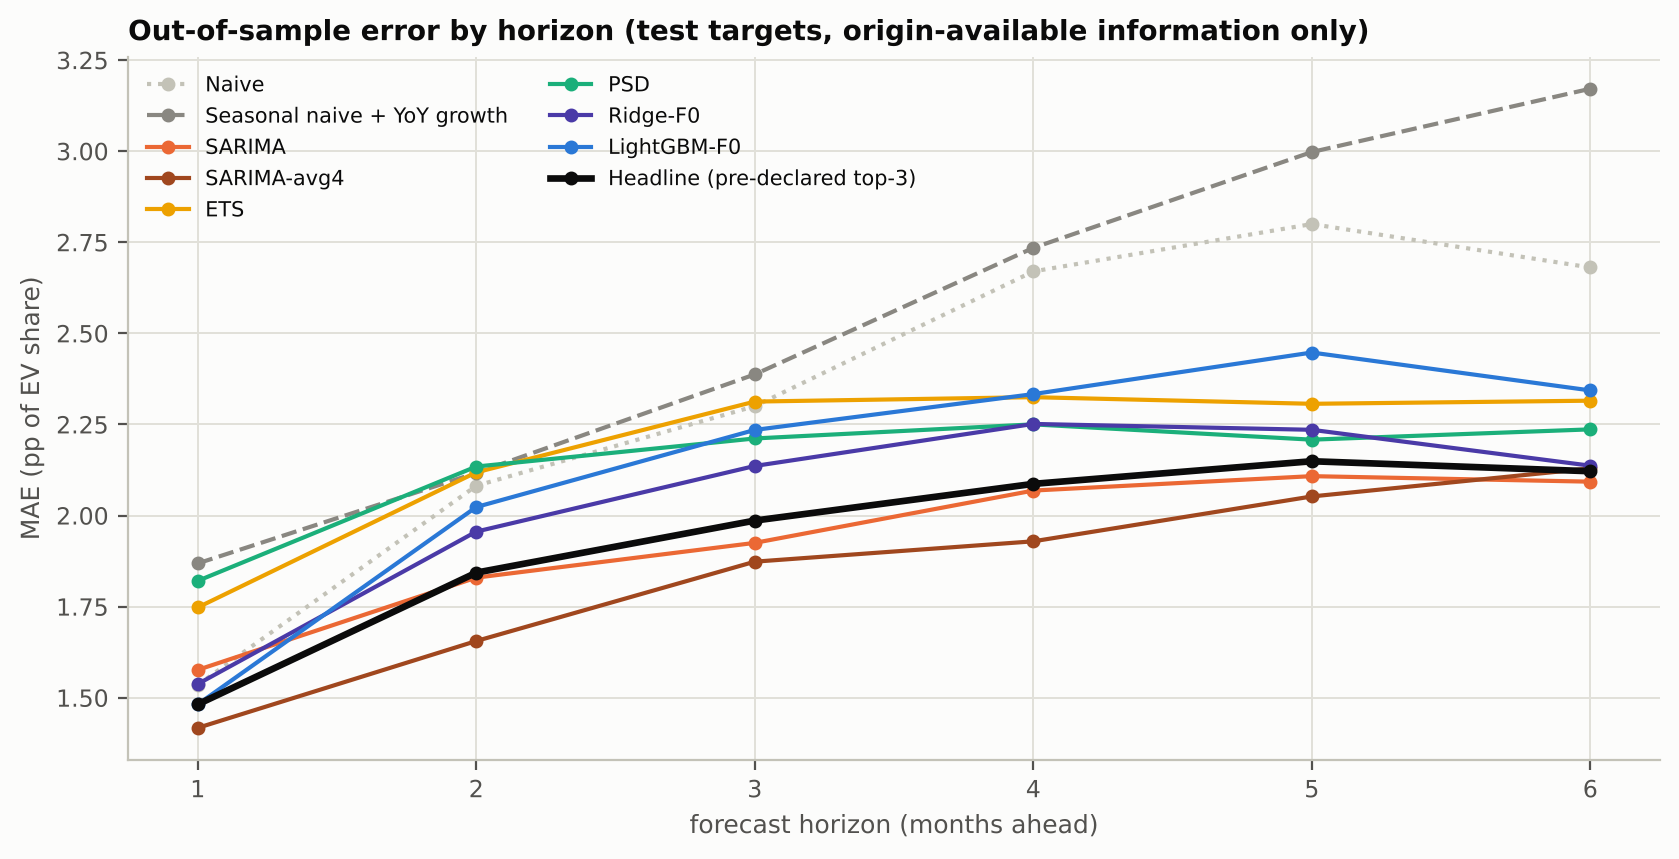

  [figure] outputs/figures/fig16_mae_by_horizon.png


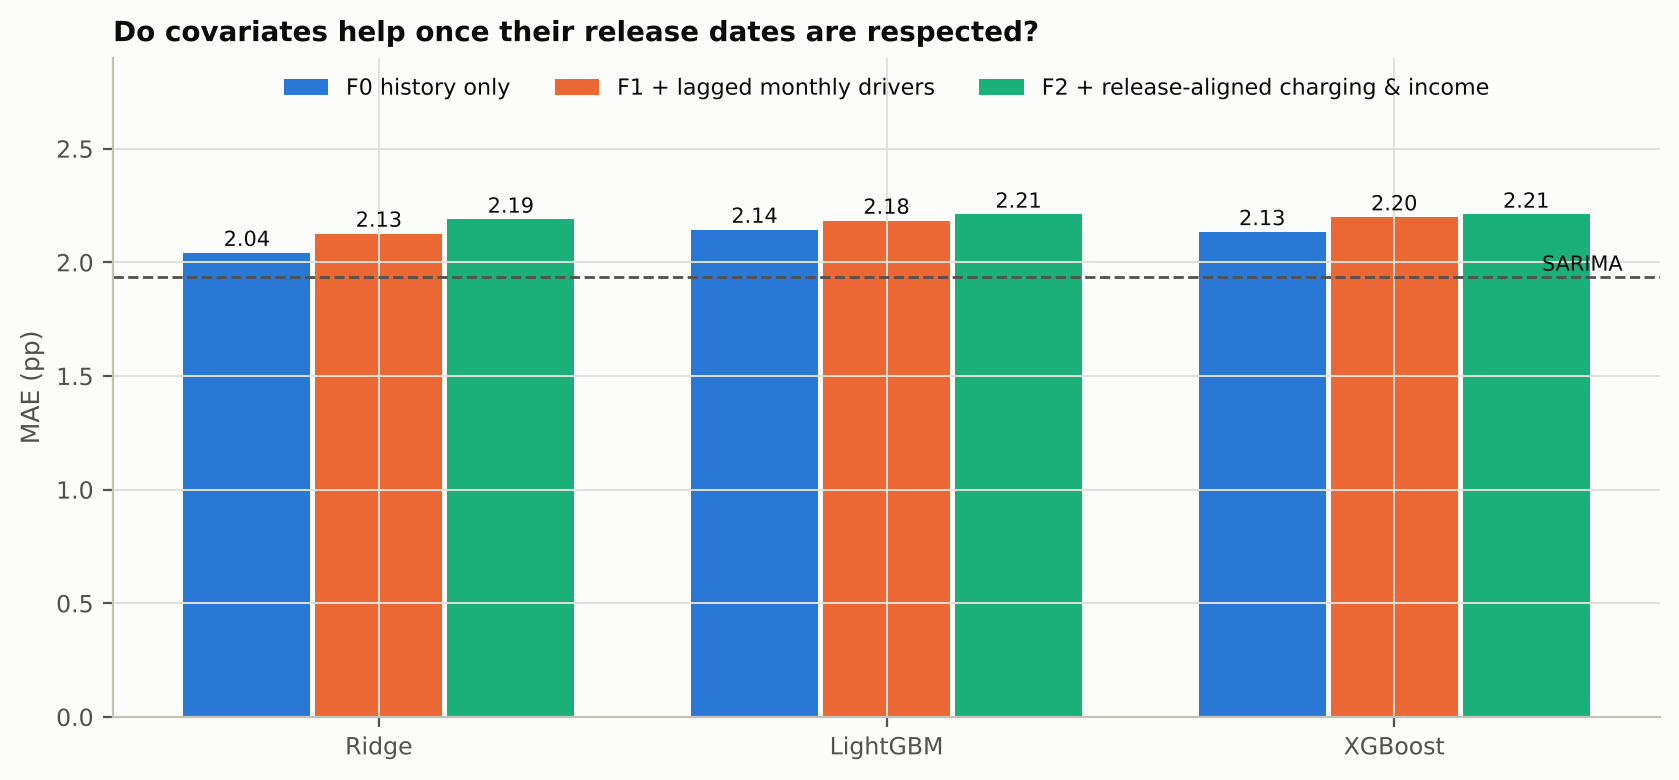

  [figure] outputs/figures/fig19_covariate_value_F0_F1_F2.png


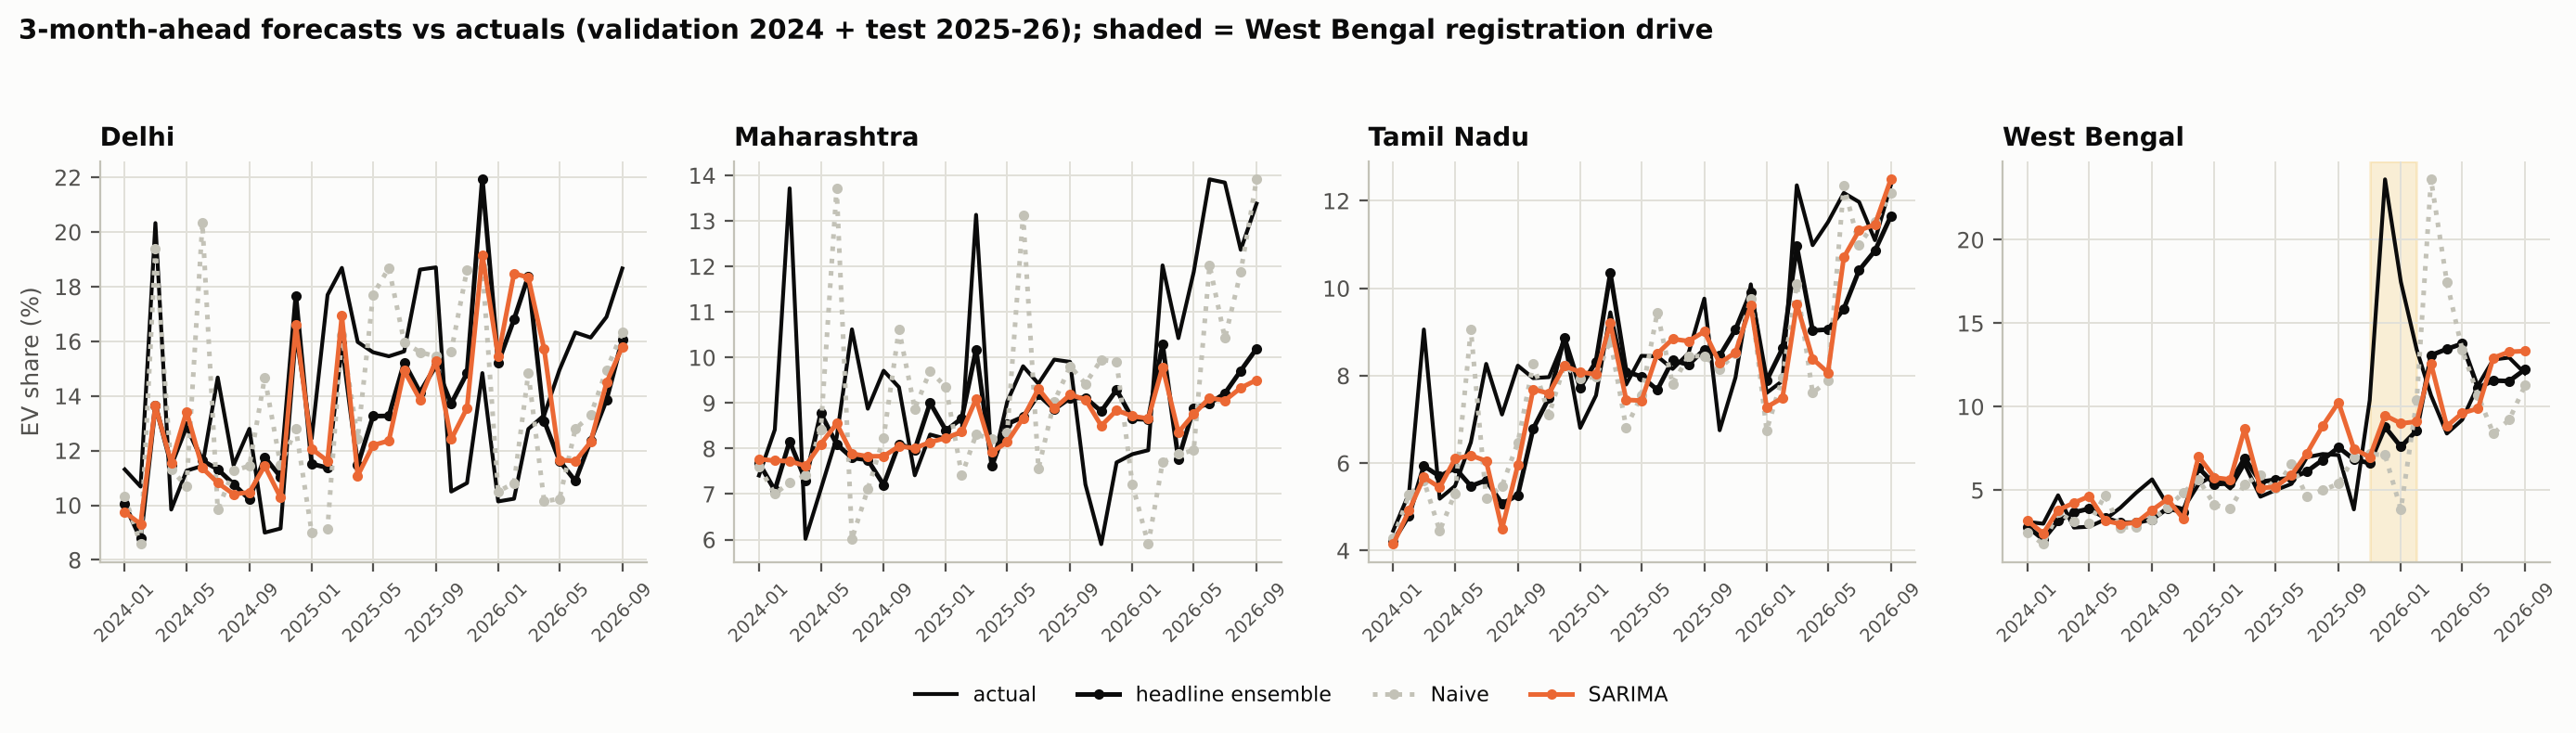

  [figure] outputs/figures/fig17_forecast_vs_actual_h3.png


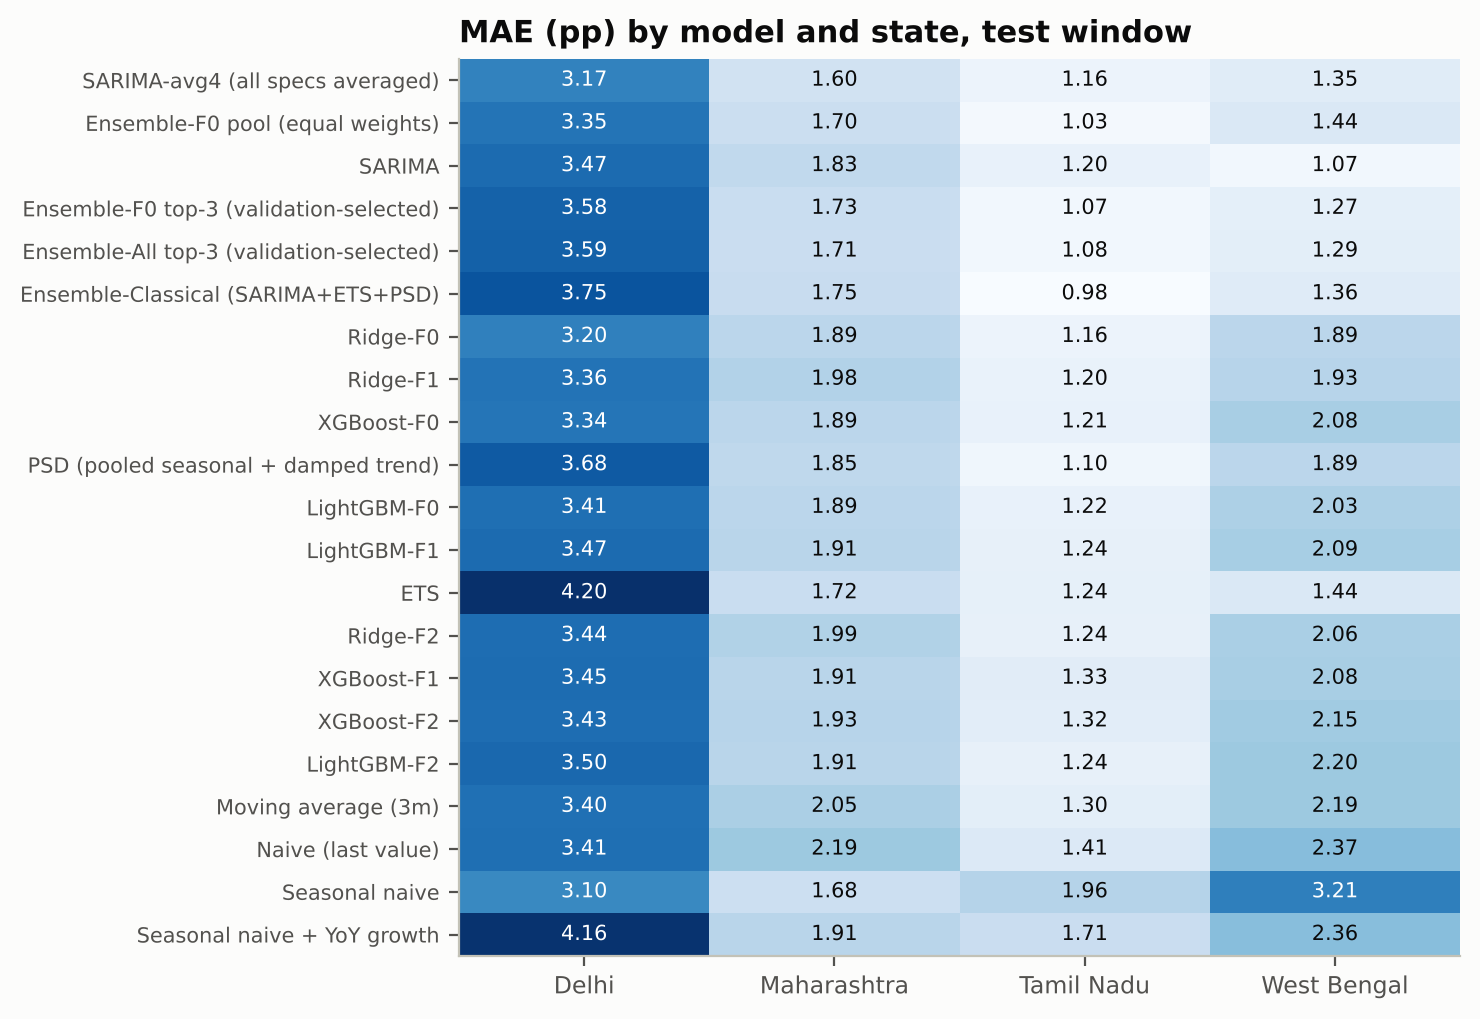

  [figure] outputs/figures/fig18_mae_model_state_heatmap.png
  [json]   outputs/tables/04_summary.json
Best on test: SARIMA-avg4 (all specs averaged)


In [7]:
from common import *
from forecasting_utils import *
from vintage import backlog_adjusted_rate

import lightgbm as lgb
import xgboost as xgb
import joblib
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = load_data(complete=False)
vp = pd.read_csv(BASE_DIR / "data" / "ev_panel_vintage.csv", parse_dates=["date"])
vp = vp[vp.date <= DATA_CUTOFF].sort_values(["state", "date"]).reset_index(drop=True)
protocol = json.loads((TAB_DIR / "02_selected_features_and_protocol.json").read_text())
SEL = protocol["selected_drivers"]
EXOG_F1 = [c for c in SEL if c not in ("charging_stations", "nsdp_per_capita")]
EXOG_F2 = EXOG_F1 + [c for c in ("charging_stations", "nsdp_per_capita") if c in SEL]
FSETS = {"F0": [], "F1": EXOG_F1, "F2": EXOG_F2}
print("F1 drivers:", EXOG_F1, "| F2 adds:", [c for c in EXOG_F2 if c not in EXOG_F1])

HORIZONS = [1, 2, 3, 4, 5, 6]
N_T = int(df.t.max() + 1)
T_TRAIN_END = int(df.loc[df.date == TRAIN_END, "t"].iloc[0])           # 35 = Dec-2024
EVAL_T = list(range(24, N_T))                                           # validation (24..35) + test (36..)
Y = {s: df[df.state == s].sort_values("t")[TARGET].to_numpy() for s in STATES}
DATES = df[df.state == STATES[0]].sort_values("t").date.to_numpy()
EX = {s: vp[vp.state == s].reset_index(drop=True)[EXOG_F2] for s in STATES}           # index = t (origin month)
FLAG = {s: df[df.state == s].sort_values("t").anomaly_flag.to_numpy() for s in STATES}
assert all(len(EX[s]) == N_T for s in STATES)

# backlog-adjusted West Bengal history (data-driven, stage 07) for the sensitivity run
adj, wb_base3w = backlog_adjusted_rate(df)
Y_ADJ = {s: v.copy() for s, v in Y.items()}
for t_, r_ in adj.items():
    Y_ADJ[ANOMALY_STATE][t_] = r_
print(f"WB baseline three-wheelers {wb_base3w:.0f}/month; adjusted rates:", {k: round(v, 3) for k, v in adj.items()})

# --------------------------------------------------------------------------------------------- rows + tuning
ROWS = {fs: {h: make_rows(Y, EX, ex, h, range(14, N_T)) for h in HORIZONS} for fs, ex in FSETS.items()}
FEATS = {fs: ml_feature_names(ex) for fs, ex in FSETS.items()}
print("features:", {k: len(v) for k, v in FEATS.items()})

from forecast_engine import SPACES      # same search spaces as the fixed-origin backtest / final refit
BEST, tune_log = {}, []
for fs in FSETS:
    for h in HORIZONS:
        tr = ROWS[fs][h].query("t <= @T_TRAIN_END").reset_index(drop=True)
        folds = [(tr.index[tr.t < a].to_numpy(), tr.index[(tr.t >= a) & (tr.t <= b)].to_numpy()) for a, b in [(24, 29), (30, 35)]]
        for name, (est, space, n_iter) in SPACES.items():
            rs = RandomizedSearchCV(est, space, n_iter=n_iter, cv=folds, scoring="neg_mean_absolute_error",
                                    random_state=SEED, n_jobs=-1, error_score=np.nan).fit(tr[FEATS[fs]], tr["target"])
            BEST[(name, fs, h)] = rs.best_estimator_
            tune_log.append({"model": name, "feature_set": fs, "h": h, "cv_MAE_log_ratio": -rs.best_score_,
                             "params": {k.split("__")[-1]: (round(float(v), 4) if isinstance(v, (float, np.floating)) else (int(v) if isinstance(v, (int, np.integer)) else v)) for k, v in rs.best_params_.items()}})
    print(f"  tuned {fs}", flush=True)
tune_tab = pd.DataFrame(tune_log)
save_table(tune_tab.assign(params=tune_tab.params.astype(str)), "04_ml_tuning_log", index=False)

# --------------------------------------------------------------------------------------------- SARIMA spec (train window only)
val_origins = range(23, 30)
SARIMA_CHOICE, sel_rows = {}, []
for s in STATES:
    scores = {}
    for spec in SARIMA_SPECS:
        errs = []
        for o in val_origins:
            f = fit_forecast_sarima(Y[s][:o + 1], 6, spec)
            tgt = np.arange(o + 1, o + 7); ok = tgt <= T_TRAIN_END
            errs += list(np.abs(f[ok] - Y[s][tgt[ok]]))
        scores[spec] = np.mean(errs) * 100
        sel_rows.append({"state": s, "spec": spec, "validation_MAE_pp": np.mean(errs) * 100})
    SARIMA_CHOICE[s] = min(scores, key=scores.get)
print("SARIMA spec per state:", SARIMA_CHOICE)
save_table(pd.DataFrame(sel_rows), "04_sarima_spec_selection", index=False)

# --------------------------------------------------------------------------------------------- rolling-origin evaluation
records = []


def add(model, s, o, h, pred):
    t = o + h
    records.append({"model": model, "state": s, "o": o, "t": t, "h": h, "date": DATES[t], "y_true": Y[s][t],
                    "y_pred": float(pred), "flag": int(FLAG[s][t])})


origins_by_h = {h: [t - h for t in EVAL_T] for h in HORIZONS}
all_origins = sorted({o for v in origins_by_h.values() for o in v})
for o in all_origins:
    sf = pooled_seasonal(Y, o + 1)
    sf_adj = pooled_seasonal(Y_ADJ, o + 1)
    for s in STATES:
        y = Y[s]; hist = y[:o + 1]
        ets, sar = fit_forecast_ets(hist, 6), fit_forecast_sarima(hist, 6, SARIMA_CHOICE[s])
        psd = fit_forecast_psd(hist, 6, sf)
        sar_avg = np.exp(np.mean([np.log(fit_forecast_sarima(hist, 6, sp)) for sp in SARIMA_SPECS], axis=0))   # spec-free average
        b = base_level(y, o); b_ly = np.mean(y[o - 14:o - 11])
        if s == ANOMALY_STATE:                     # sensitivity: same models fed the backlog-adjusted history
            ha = Y_ADJ[s][:o + 1]
            ets_a, sar_a, psd_a = fit_forecast_ets(ha, 6), fit_forecast_sarima(ha, 6, SARIMA_CHOICE[s]), fit_forecast_psd(ha, 6, sf_adj)
        for h in HORIZONS:
            t = o + h
            if t not in EVAL_T:
                continue
            add("Naive (last value)", s, o, h, y[o]); add("Moving average (3m)", s, o, h, b)
            add("Seasonal naive", s, o, h, y[t - 12]); add("Seasonal naive + YoY growth", s, o, h, y[t - 12] * b / b_ly)
            add("ETS", s, o, h, ets[h - 1]); add("SARIMA", s, o, h, sar[h - 1]); add("SARIMA-avg4 (all specs averaged)", s, o, h, sar_avg[h - 1]); add("PSD (pooled seasonal + damped trend)", s, o, h, psd[h - 1])
            if s == ANOMALY_STATE:
                add("ETS [backlog-adjusted history]", s, o, h, ets_a[h - 1]); add("SARIMA [backlog-adjusted history]", s, o, h, sar_a[h - 1])
                add("PSD [backlog-adjusted history]", s, o, h, psd_a[h - 1])
    if o % 10 == 0:
        print("  classical origin", o, flush=True)

for fs in FSETS:
    for h in HORIZONS:
        rows_h = ROWS[fs][h]
        for o in origins_by_h[h]:
            tr, te = rows_h[rows_h.t <= o], rows_h[rows_h.o == o]
            if len(tr) < 24:                      # too little realised history for a direct ML refit at this origin
                continue
            for name in SPACES:
                m = clone(BEST[(name, fs, h)]).fit(tr[FEATS[fs]], tr["target"])
                pred = te["base"].to_numpy() * np.exp(m.predict(te[FEATS[fs]]))
                for s, p in zip(te.state, pred):
                    add(f"{name}-{fs}", s, o, h, p)
    print(f"  ML rolling refits done for {fs}", flush=True)
ev = pd.DataFrame(records)
ev["period"] = np.where(ev.t <= T_TRAIN_END, "validation", "test")

# ---------------- ensembles chosen from VALIDATION-window accuracy only
val = ev[(ev.period == "validation") & (ev.flag == 0)].assign(ae=lambda d: (d.y_true - d.y_pred).abs())
_piv = val[~val.model.str.contains(r"\[backlog")].pivot_table(index=["state", "h", "t"], columns="model", values="ae").dropna()   # common support
print(f"validation comparison uses {len(_piv)} (state, horizon, month) cells where every model has a forecast")
val_mae = (100 * _piv.mean()).sort_values()
print("\nValidation-window MAE (pp), 2024 targets:\n", val_mae.round(3).to_string())
save_table(val_mae.round(4).to_frame("validation_MAE_pp"), "04_validation_mae")
CLASSIC = ["SARIMA", "ETS", "PSD (pooled seasonal + damped trend)"]
F0_POOL = CLASSIC + ["SARIMA-avg4 (all specs averaged)", "Ridge-F0", "LightGBM-F0", "XGBoost-F0"]
ALL_POOL = CLASSIC + ["SARIMA-avg4 (all specs averaged)"] + [f"{n}-{fs}" for n in SPACES for fs in FSETS]
ENS_DEF = {"Ensemble-Classical (SARIMA+ETS+PSD)": CLASSIC,
           "Ensemble-F0 top-3 (validation-selected)": list(val_mae[val_mae.index.isin(F0_POOL)].index[:3]),
           "Ensemble-All top-3 (validation-selected)": list(val_mae[val_mae.index.isin(ALL_POOL)].index[:3]),
           "Ensemble-F0 pool (equal weights)": F0_POOL}
print("\nEnsemble membership:"); [print(" ", k, "->", v) for k, v in ENS_DEF.items()]
parts = []
for name, members in ENS_DEF.items():
    e_ = ev[ev.model.isin(members)].groupby(["state", "o", "t", "h", "date", "y_true", "flag", "period"], as_index=False)["y_pred"].mean()
    e_["model"] = name; parts.append(e_)
ev = pd.concat([ev] + parts, ignore_index=True)
ev["abs_err"] = (ev.y_true - ev.y_pred).abs()
save_table(ev, "04_rolling_origin_predictions", index=False)
save_json({"ensemble_members": ENS_DEF}, "04_ensemble_membership")

# --------------------------------------------------------------------------------------------- results (TEST window)
test = ev[ev.period == "test"].copy()
mase_scale = {s: np.mean(np.abs(np.diff(Y[s][:T_TRAIN_END + 1]))) for s in STATES}
test["mase_term"] = test.abs_err / test.state.map(mase_scale)
test["subperiod"] = np.where(test.date.dt.year == 2025, "2025", f"{DATA_CUTOFF.year} YTD")


def summarise(frame, by):
    g = frame.groupby(by)
    return pd.DataFrame({"MAE_pp": 100 * g.abs_err.mean(),
                         "RMSE_pp": 100 * np.sqrt(g.apply(lambda d: np.mean((d.y_true - d.y_pred) ** 2))),
                         "sMAPE_%": 100 * g.apply(lambda d: smape(d.y_true, d.y_pred)),
                         "MASE": g.mase_term.mean(), "n": g.size()})


clean = test[test.flag == 0]
main_models = [m for m in clean.model.unique() if "[backlog" not in m]
by_model_clean = summarise(clean[clean.model.isin(main_models)], "model").sort_values("MAE_pp")
by_model_all = summarise(test[test.model.isin(main_models)], "model").sort_values("MAE_pp")
print(f"\nTEST window, targets {TEST_START:%b-%Y}..{DATA_CUTOFF:%b-%Y}, horizons 1-6, flagged WB months excluded:")
print(by_model_clean.round(3).to_string())
save_table(by_model_clean.round(4), "04_metrics_overall_clean"); save_table(by_model_all.round(4), "04_metrics_overall_all")
by_h = summarise(clean[clean.model.isin(main_models)], ["model", "h"])["MAE_pp"].unstack("h").loc[by_model_clean.index]
by_state = summarise(clean[clean.model.isin(main_models)], ["model", "state"])["MAE_pp"].unstack("state").loc[by_model_clean.index][STATES]
by_period = summarise(clean[clean.model.isin(main_models)], ["model", "subperiod"])["MAE_pp"].unstack("subperiod").loc[by_model_clean.index]
print("\nMAE by horizon:\n", by_h.round(2).to_string()); print("\nMAE by sub-period:\n", by_period.round(2).to_string())
save_table(by_h.round(4), "04_mae_by_horizon_clean"); save_table(by_state.round(4), "04_mae_by_state_clean"); save_table(by_period.round(4), "04_mae_by_period_clean")

# sensitivity: backlog-adjusted history (West Bengal only, flagged months excluded)
sens = []
for m in CLASSIC:
    a = clean[(clean.model == m) & (clean.state == ANOMALY_STATE)].abs_err.mean() * 100
    b = clean[(clean.model == m + " [backlog-adjusted history]") & (clean.state == ANOMALY_STATE)].abs_err.mean() * 100 if m != "PSD (pooled seasonal + damped trend)" else \
        clean[(clean.model == "PSD [backlog-adjusted history]") & (clean.state == ANOMALY_STATE)].abs_err.mean() * 100
    sens.append({"model": m, "WB_MAE_as_reported_history_pp": a, "WB_MAE_backlog_adjusted_history_pp": b})
sens = pd.DataFrame(sens).round(3); print("\nWest Bengal sensitivity to the registration-drive episode:\n", sens.to_string(index=False))
save_table(sens, "04_wb_history_sensitivity", index=False)


def boot_diff(model_a, model_b, frame, n=4000, seed=SEED):
    """Paired block bootstrap (blocks = target months) of mean |error| difference A - B, pp."""
    a = frame[frame.model == model_a].set_index(["state", "h", "t"]).abs_err
    b = frame[frame.model == model_b].set_index(["state", "h", "t"]).abs_err
    d = (a - b).dropna().rename("d").reset_index()
    sums = d.groupby("t").d.sum().to_numpy(); counts = d.groupby("t").d.size().to_numpy()
    k = len(sums); rng = np.random.default_rng(seed); picks = rng.integers(0, k, size=(n, k))
    means = sums[picks].sum(axis=1) / counts[picks].sum(axis=1)
    lo, hi = np.percentile(means, [5, 95])
    return 100 * d.d.mean(), 100 * lo, 100 * hi


bench = "Naive (last value)"
rows = []
for m in by_model_clean.index:
    if m == bench: continue
    dm, lo, hi = boot_diff(m, bench, clean)
    rows.append({"model": m, "MAE diff vs naive (pp)": dm, "90% CI low": lo, "90% CI high": hi, "significantly_better": hi < 0})
sig = pd.DataFrame(rows).set_index("model").round(3); print("\nVs naive (negative = better):\n", sig.to_string())
save_table(sig, "04_bootstrap_vs_benchmark")

# THE KEY TABLE: do covariates help once timing is honest?  (same model, F1 or F2 minus F0)
rows = []
for n in SPACES:
    for fs in ("F1", "F2"):
        dm, lo, hi = boot_diff(f"{n}-{fs}", f"{n}-F0", clean)
        rows.append({"model": n, "comparison": f"{fs} minus F0", "MAE diff (pp)": dm, "90% CI low": lo, "90% CI high": hi,
                     "covariates_help": hi < 0, "covariates_hurt": lo > 0})
for fs in ("F1", "F2"):
    pass
cov = pd.DataFrame(rows).round(3)
print("\nDo origin-available covariates improve the forecast? (negative = yes)\n", cov.to_string(index=False))
save_table(cov, "04_covariate_value_F0_F1_F2", index=False)

head_to_head = []
champ = by_model_clean.index[0]    # best model on the test window - descriptive only, NOT used for any choice
for a_, b_ in [(champ, "SARIMA"), ("Ensemble-F0 top-3 (validation-selected)", "SARIMA"), ("Ensemble-F0 pool (equal weights)", "SARIMA"), ("SARIMA-avg4 (all specs averaged)", "SARIMA"), ("PSD (pooled seasonal + damped trend)", "SARIMA"),
               ("LightGBM-F0", "SARIMA"), ("XGBoost-F0", "SARIMA"), ("Ridge-F0", "SARIMA"),
               ("Ensemble-All top-3 (validation-selected)", "Ensemble-F0 top-3 (validation-selected)")]:
    if a_ == b_: continue
    dm, lo, hi = boot_diff(a_, b_, clean)
    head_to_head.append({"A": a_, "B": b_, "MAE(A)-MAE(B) pp": dm, "90% CI low": lo, "90% CI high": hi})
h2h = pd.DataFrame(head_to_head).round(3); print("\nHead-to-head:\n", h2h.to_string(index=False))
save_table(h2h, "04_bootstrap_head_to_head", index=False)

# --------------------------------------------------------------------------------------------- headline model and intervals
HEADLINE = "Ensemble-F0 top-3 (validation-selected)"   # PRE-DECLARED confirmatory headline: the 3 best exogenous-free models on the 2024 validation window. The equal-weight pool and SARIMA-avg4 are EXPLORATORY (added after test results were seen)
print("\nPre-declared headline (validation-selected top-3):", HEADLINE, "->", ENS_DEF[HEADLINE])
e = ev[(ev.model == HEADLINE) & (ev.flag == 0)].copy(); e["log_err"] = np.log(e.y_true / e.y_pred)
cov_rows = []
for _, r in e[e.period == "test"].iterrows():             # expanding-window intervals: only errors realised by the origin
    past = e[(e.h == r.h) & (e.t <= r.o)]
    lo_q, hi_q = past.log_err.quantile([0.10, 0.90])
    cov_rows.append({"covered": r.y_pred * np.exp(lo_q) <= r.y_true <= r.y_pred * np.exp(hi_q), "width_pp": 100 * r.y_pred * (np.exp(hi_q) - np.exp(lo_q)), "h": r.h})
cov_df = pd.DataFrame(cov_rows)
print(f"Out-of-sample coverage of the 80% intervals (expanding-window calibration): {100 * cov_df.covered.mean():.1f}% | mean width {cov_df.width_pp.mean():.2f} pp")
save_table(cov_df.groupby("h").agg(coverage=("covered", "mean"), mean_width_pp=("width_pp", "mean")).round(3), "04_interval_coverage_by_h")
q = e.groupby("h").log_err.quantile([0.10, 0.90]).unstack(); q.columns = ["q10", "q90"]
save_table(q.round(4), "05_interval_quantiles")

# --------------------------------------------------------------------------------------------- figures
set_style()
STY = {"Naive (last value)": ("#c3c2b7", ":"), "Seasonal naive + YoY growth": ("#898781", "--"), "SARIMA": ("#eb6834", "-"), "SARIMA-avg4 (all specs averaged)": ("#a0471e", "-"), "ETS": ("#eda100", "-"),
       "PSD (pooled seasonal + damped trend)": ("#1baf7a", "-"), "Ridge-F0": ("#4a3aa7", "-"), "LightGBM-F0": ("#2a78d6", "-"),
       HEADLINE: ("#0b0b0b", "-")}
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for m, (c, ls) in STY.items():
    ax.plot(by_h.columns, by_h.loc[m], color=c, ls=ls, marker="o", ms=4, lw=2.4 if m == HEADLINE else 1.5, label=m.split(" (")[0] if m != HEADLINE else "Headline (pre-declared top-3)")
ax.set_xlabel("forecast horizon (months ahead)"); ax.set_ylabel("MAE (pp of EV share)")
ax.set_title("Out-of-sample error by horizon (test targets, origin-available information only)", fontsize=10); ax.legend(fontsize=7.5, ncol=2)
fig.tight_layout(); save_fig(fig, "fig16_mae_by_horizon")

fig, ax = plt.subplots(figsize=(8.5, 4))
mods = ["Ridge", "LightGBM", "XGBoost"]
for i, fs in enumerate(["F0", "F1", "F2"]):
    vals = [by_model_clean.loc[f"{n}-{fs}", "MAE_pp"] for n in mods]
    ax.bar(np.arange(3) + (i - 1) * 0.26, vals, 0.25, color=["#2a78d6", "#eb6834", "#1baf7a"][i], label={"F0": "F0 history only", "F1": "F1 + lagged monthly drivers", "F2": "F2 + release-aligned charging & income"}[fs])
    for x, v in zip(np.arange(3) + (i - 1) * 0.26, vals): ax.text(x, v + 0.03, f"{v:.2f}", ha="center", fontsize=7.5)
ax.axhline(by_model_clean.loc["SARIMA", "MAE_pp"], color=INK2, ls="--", lw=1); ax.text(2.45, by_model_clean.loc["SARIMA", "MAE_pp"] + 0.03, "SARIMA", fontsize=7.5, ha="right")
ax.set_xticks(range(3), mods); ax.set_ylabel("MAE (pp)"); ax.set_ylim(0, 2.9); ax.legend(fontsize=8, loc="upper center", ncol=3)
ax.set_title("Do covariates help once their release dates are respected?", fontsize=10)
fig.tight_layout(); save_fig(fig, "fig19_covariate_value_F0_F1_F2")

fig, axes = plt.subplots(1, 4, figsize=(14, 3.4))
for ax, s in zip(axes, STATES):
    full = df[df.state == s]
    ax.plot(full.date[full.t >= 24], 100 * full[TARGET][full.t >= 24], color=INK, lw=1.5, label="actual")
    for m in [HEADLINE, "Naive (last value)", "SARIMA"]:
        d = ev[(ev.model == m) & (ev.state == s) & (ev.h == 3)].sort_values("t")
        c, ls = STY[m]; ax.plot(d.date, 100 * d.y_pred, color=c, ls=ls, lw=1.8, marker="o", ms=3, label=m.split(" (")[0] if m != HEADLINE else "headline ensemble")
    ax.axvspan(full.date[full.anomaly_flag == 1].min(), full.date[full.anomaly_flag == 1].max(), color="#eda100", alpha=.15) if s == ANOMALY_STATE else None
    ax.set_title(s, fontsize=10); ax.tick_params(axis="x", labelrotation=45, labelsize=7)
axes[0].set_ylabel("EV share (%)")
h_, l_ = axes[0].get_legend_handles_labels(); fig.legend(h_, l_, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.08), fontsize=8)
fig.suptitle("3-month-ahead forecasts vs actuals (validation 2024 + test 2025-26); shaded = West Bengal registration drive", x=0.01, y=1.04, ha="left", fontweight="bold", fontsize=10.5)
fig.tight_layout(); save_fig(fig, "fig17_forecast_vs_actual_h3")

fig, ax = plt.subplots(figsize=(7.5, 5.2)); sub = by_state
im = ax.imshow(sub.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(4), STATES); ax.set_yticks(range(len(sub)), sub.index, fontsize=7.5); ax.grid(False)
for i in range(sub.shape[0]):
    for j in range(4):
        v = sub.iloc[i, j]; ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5, color="white" if v > sub.values.max() * 0.6 else INK)
ax.set_title("MAE (pp) by model and state, test window")
fig.tight_layout(); save_fig(fig, "fig18_mae_model_state_heatmap")

(BASE_DIR / "outputs" / "models").mkdir(exist_ok=True, parents=True)
joblib.dump({"ml_templates": BEST, "sarima_choice": SARIMA_CHOICE, "feats": FEATS, "fsets": FSETS, "headline": HEADLINE,
             "ens_def": ENS_DEF}, BASE_DIR / "outputs" / "models" / "forecasting_config.joblib")
save_json({"headline": HEADLINE, "headline_members": ENS_DEF[HEADLINE], "best_test_model": champ, "benchmark": bench, "sarima_choice": SARIMA_CHOICE,
           "interval_coverage_80_test": float(cov_df.covered.mean()), "wb_baseline_three_wheelers": wb_base3w, "feature_sets": FSETS}, "04_summary")
print("Best on test:", champ)


## `07_west_bengal_evidence.py`
07_west_bengal_evidence.py -- what do the data say about the Nov-2025..Feb-2026 West Bengal surge?
=========================================================================================================
Hypothesis (trade press, to be cited with the official notification): the state made e-rickshaw ("Toto") registration
mandatory in Oct-2025 (deadline 31-Dec-2025, extended to 31-Jan-2026), so the surge could be a BACKLOG of existing vehicles (a hypothesis: the evidence below is consistent with it but does not officially verify it).
Test inside the panel: if true, (a) West Bengal's three-wheeler registrations jump in exactly these months, (b) the
excess EVs almost equal the excess three-wheelers, (c) no other state shows it, (d) removing the excess restores a
normal EV share.  Run from the project root:  python 07_west_bengal_evidence.py

Pre-episode medians (12 months before Nov-2025): three-wheelers 3710/month, EVs 5517/month

      date  vehicle_total  ev_count  rate_%  three_wheeler  3W_share_%  excess_EV  excess_3W  adj_rate_%
2025-08-01          77848      5574     7.2           3871         5.0       57.0      161.0         7.2
2025-09-01          90042      6390     7.1           4495         5.0      873.0      785.0         7.1
2025-10-01         149903      5762     3.8           3248         2.2      245.0        0.0         3.8
2025-11-01         144992     15046    10.4          13107         9.0     9529.0     9397.0         4.2
2025-12-01         131761     31120    23.6          29216        22.2    25603.0    25506.0         5.3
2026-01-01         121088     21158    17.5          19072        15.8    15641.0    15362.0         5.5
2026-02-01         113740     15260    13.4          13246        11.6     9743.0     9536.0         5.5
2026-03-01         118497     12648    10.7           8758         7

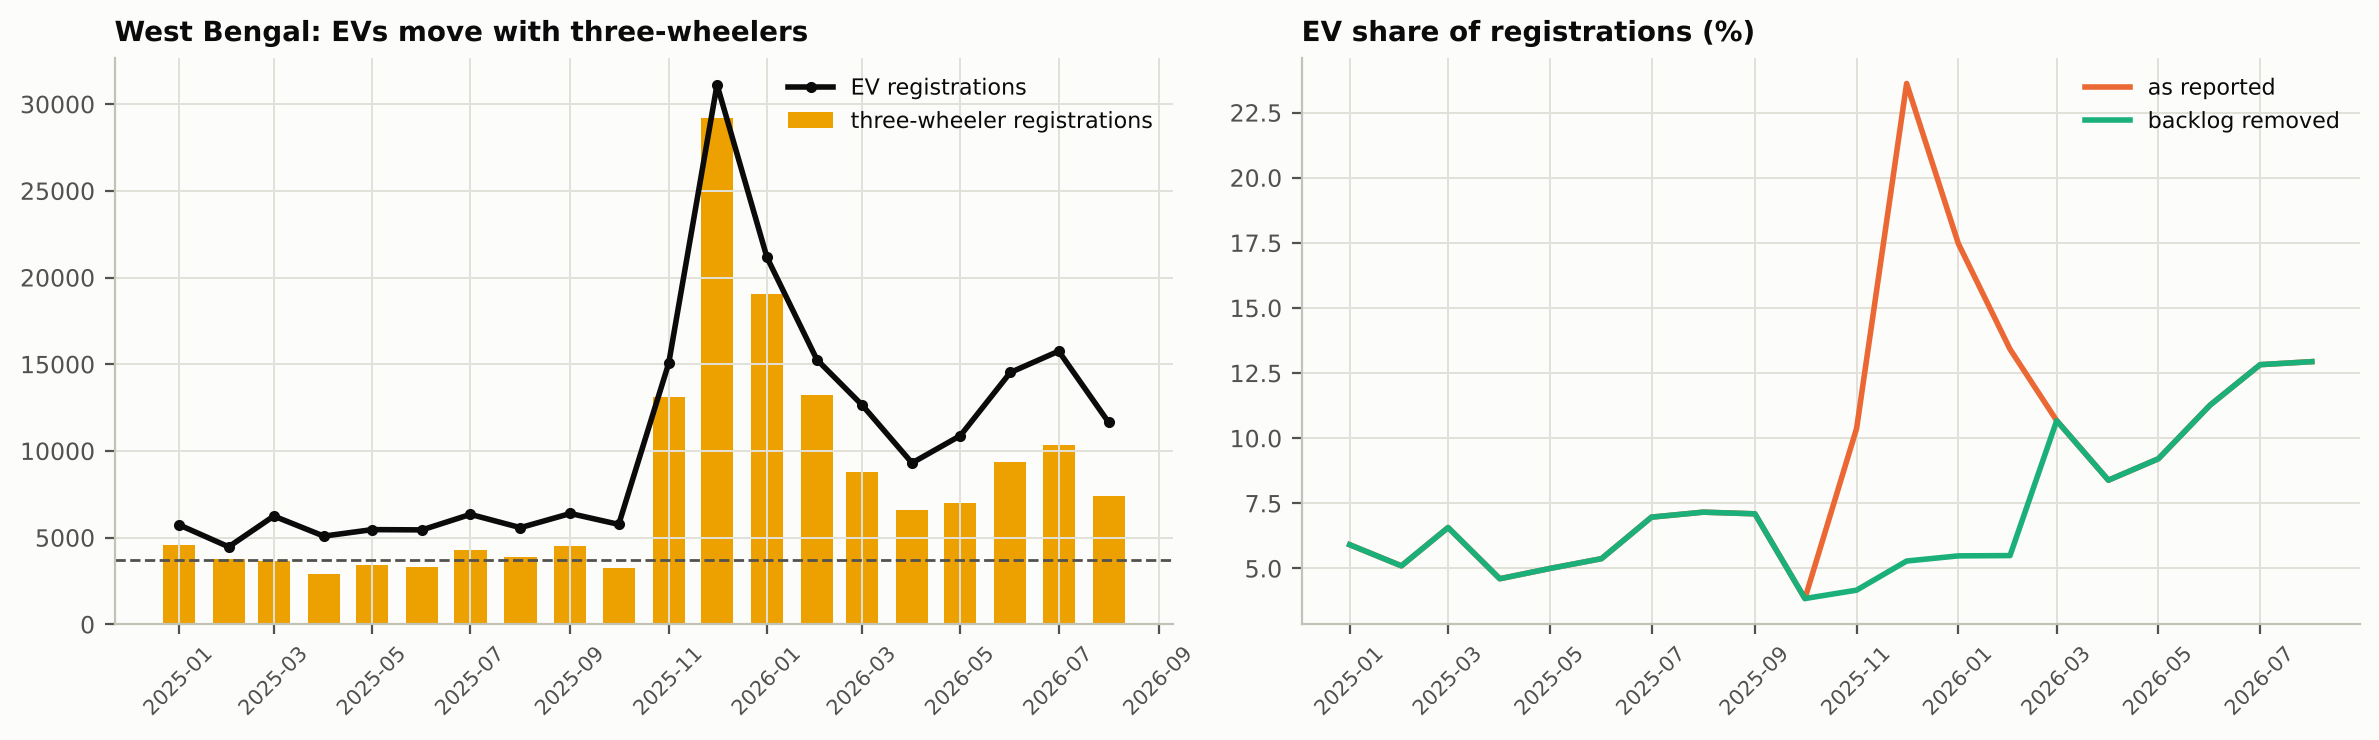

  [figure] outputs/figures/fig21_west_bengal_evidence.png


PosixPath('/home/claude/ev_adoption_project/outputs/figures/fig21_west_bengal_evidence.png')

In [8]:
from common import *
from vintage import backlog_adjusted_rate

df = load_data()
adj, base3w = backlog_adjusted_rate(df)
w = df[df.state == ANOMALY_STATE].sort_values("date").copy()
pre = w[(w.date < ANOMALY_START) & (w.date >= ANOMALY_START - pd.DateOffset(months=12))]
base_ev = float(pre.ev_count.median())
w["3W_baseline"] = base3w; w["excess_3W"] = (w.three_wheeler - base3w).clip(lower=0)
w["excess_EV"] = (w.ev_count - base_ev).clip(lower=0)
w["adj_rate_%"] = [100 * adj[int(t)] if int(t) in adj else 100 * r for t, r in zip(w.t, w[TARGET])]
w["rate_%"] = 100 * w[TARGET]; w["3W_share_%"] = 100 * w.three_wheeler / w.vehicle_total
view = w[w.date >= "2025-08-01"][["date", "vehicle_total", "ev_count", "rate_%", "three_wheeler", "3W_share_%", "excess_EV", "excess_3W", "adj_rate_%"]]
print(f"Pre-episode medians (12 months before {ANOMALY_START:%b-%Y}): three-wheelers {base3w:.0f}/month, EVs {base_ev:.0f}/month\n")
print(view.round(1).to_string(index=False))
fl = w[w.anomaly_flag == 1]
ratio = fl.excess_EV.sum() / fl.excess_3W.sum()
corr = np.corrcoef(w[w.date >= "2025-01-01"].ev_count, w[w.date >= "2025-01-01"].three_wheeler)[0, 1]
print(f"\nIn the {len(fl)} flagged months: excess EV registrations / excess three-wheeler registrations = {ratio:.2f} (1.0 = every extra EV is a three-wheeler)")
print(f"Correlation of monthly EV and three-wheeler counts, WB 2025-26: {corr:.2f}")
others = df[(df.state != ANOMALY_STATE) & df.date.between(ANOMALY_START, ANOMALY_END)].groupby("state").three_wheeler.max() / \
         df[(df.state != ANOMALY_STATE) & (df.date < ANOMALY_START) & (df.date >= ANOMALY_START - pd.DateOffset(months=12))].groupby("state").three_wheeler.median()
print("Other states: peak three-wheelers during the window / their pre-episode median:", others.round(2).to_dict())
print(f"West Bengal: peak three-wheelers / pre-episode median = {fl.three_wheeler.max() / base3w:.1f}x")
summ = {"baseline_three_wheelers_per_month": base3w, "baseline_EV_per_month": base_ev, "excess_EV_over_excess_3W_in_flagged_months": float(ratio),
        "corr_EV_vs_3W_2025_26": float(corr), "wb_peak_3W_multiple": float(fl.three_wheeler.max() / base3w),
        "other_states_peak_3W_multiple": {k: float(v) for k, v in others.items()},
        "adjusted_rates_flagged_months_%": {str(w.loc[w.t == k, 'date'].iloc[0].date()): round(100 * v, 2) for k, v in adj.items()},
        "evidence_status": "evidence CONSISTENT WITH an e-rickshaw registration backlog (numerical correspondence only; NOT officially verified); official notification and Vahan class split still to be cited"}
save_json(summ, "07_wb_evidence"); save_table(view.round(3), "07_wb_episode_table", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
v = w[w.date >= "2025-01-01"]
axes[0].bar(v.date, v.three_wheeler, 20, color="#eda100", label="three-wheeler registrations"); axes[0].plot(v.date, v.ev_count, color="#0b0b0b", lw=2, marker="o", ms=3, label="EV registrations")
axes[0].axhline(base3w, color=INK2, ls="--", lw=1); axes[0].set_title("West Bengal: EVs move with three-wheelers", fontsize=10); axes[0].legend(fontsize=8)
axes[1].plot(v.date, v["rate_%"], color="#eb6834", lw=2, label="as reported"); axes[1].plot(v.date, v["adj_rate_%"], color="#1baf7a", lw=2, label="backlog removed")
axes[1].set_title("EV share of registrations (%)", fontsize=10); axes[1].legend(fontsize=8)
for a in axes: a.tick_params(axis="x", labelrotation=45, labelsize=7.5)
fig.tight_layout(); save_fig(fig, "fig21_west_bengal_evidence")


## `10_fixed_origin_backtest.py`
10_fixed_origin_backtest.py -- "train to March 2026, forecast April-September 2026, compare with what actually happened"
=======================================================================================================================
A single, easy-to-explain pseudo-future test that complements the rolling-origin benchmark of stage 04:
  * origin = Mar-2026.  Every estimate (hyper-parameters, SARIMA specification, seasonal factors, model fits, interval
    calibration) uses ONLY data with t <= Mar-2026; covariates come from the release-aligned vintage panel.
  * targets = Apr..Sep-2026 (horizons 1..6) - six months that the models never saw.
  * the same engine (forecast_engine.py) is then run at origin Sep-2026 on ALL data for the real forecast (stage 05).
Headline = the PRE-DECLARED top-3 ensemble (SARIMA, ETS, XGBoost-F0: best exogenous-free models on the 2024 validation window).  The equal-weight
pool and SARIMA-avg4 are EXPLORATORY comparisons that were added after test results were seen.
Policies for the West Bengal drive months (Nov-25..Feb-26 sit INSIDE the training history): as_reported (all models) and
backlog_removed (history repaired, exogenous-free models only).  No flagged month is a target here.
Caveat to state in the report: 24 forecasts per model (4 states x 6 months), ONE origin - conclusions are indicative; the
statistical weight comes from the 456-forecast rolling test in stage 04.
Run from the project root after stages 00a-04:  python 10_fixed_origin_backtest.py

origin Mar-2026 (t=50); targets Apr-2026..Sep-2026; data end Sep-2026 (t=56)

Covariates visible at the origin (vintage panel):
      state   aqi_mean  petrol_price  charging_stations charging_snapshot_label  nsdp_per_capita nsdp_fy_label nsdp_status_asof
      Delhi 283.209014         94.77             1957.0              2025-12-01         515500.0       2023-24          Revised
Maharashtra  64.485054        103.54             4166.0              2025-12-01         321100.0       2023-24          Revised
 Tamil Nadu  65.266576        100.84             1780.0              2025-12-01         355200.0       2023-24          Revised
West Bengal 161.551891        105.45              891.0              2025-12-01         171200.0       2023-24          Revised


    origin t=50: ML tuned/fitted for F0


    origin t=50: ML tuned/fitted for F1


    origin t=50: ML tuned/fitted for F2


SARIMA spec chosen: {'Delhi': '(1,1,1)(0,1,0,12)', 'Maharashtra': '(0,1,1)(1,0,0,12)', 'Tamil Nadu': '(0,1,1)(1,0,0,12)', 'West Bengal': '(1,1,1)(0,1,0,12)'}


    origin t=50: ML tuned/fitted for F0



Interval calibration errors available at the origin (n per horizon): {1: 104, 2: 104, 3: 104, 4: 104, 5: 104, 6: 104}
  [table]  outputs/tables/10_backtest_forecasts.csv

BACKTEST (origin Mar-2026, targets Apr-Sep 2026, 24 forecasts per model, as_reported history):
                                          MAE_pp  RMSE_pp  MAPE_%  sMAPE_%   MASE  R2_pooled  R2_within_state  direction_correct_%  skill_vs_naive_%     n
Naive (last value)                        1.699    2.188  12.584   13.199  0.950      0.138           -1.536                0.000             0.000  24.0
SARIMA                                    1.964    2.418  15.273   16.940  1.300     -0.052           -2.096               79.167           -15.563  24.0
SARIMA-avg4 (all specs averaged)          2.180    2.601  16.264   18.211  1.272     -0.217           -2.582               62.500           -28.277  24.0
Ensemble-F0 top-3 (validation-selected)   2.405    2.729  18.346   20.375  1.458     -0.340           -2.943        

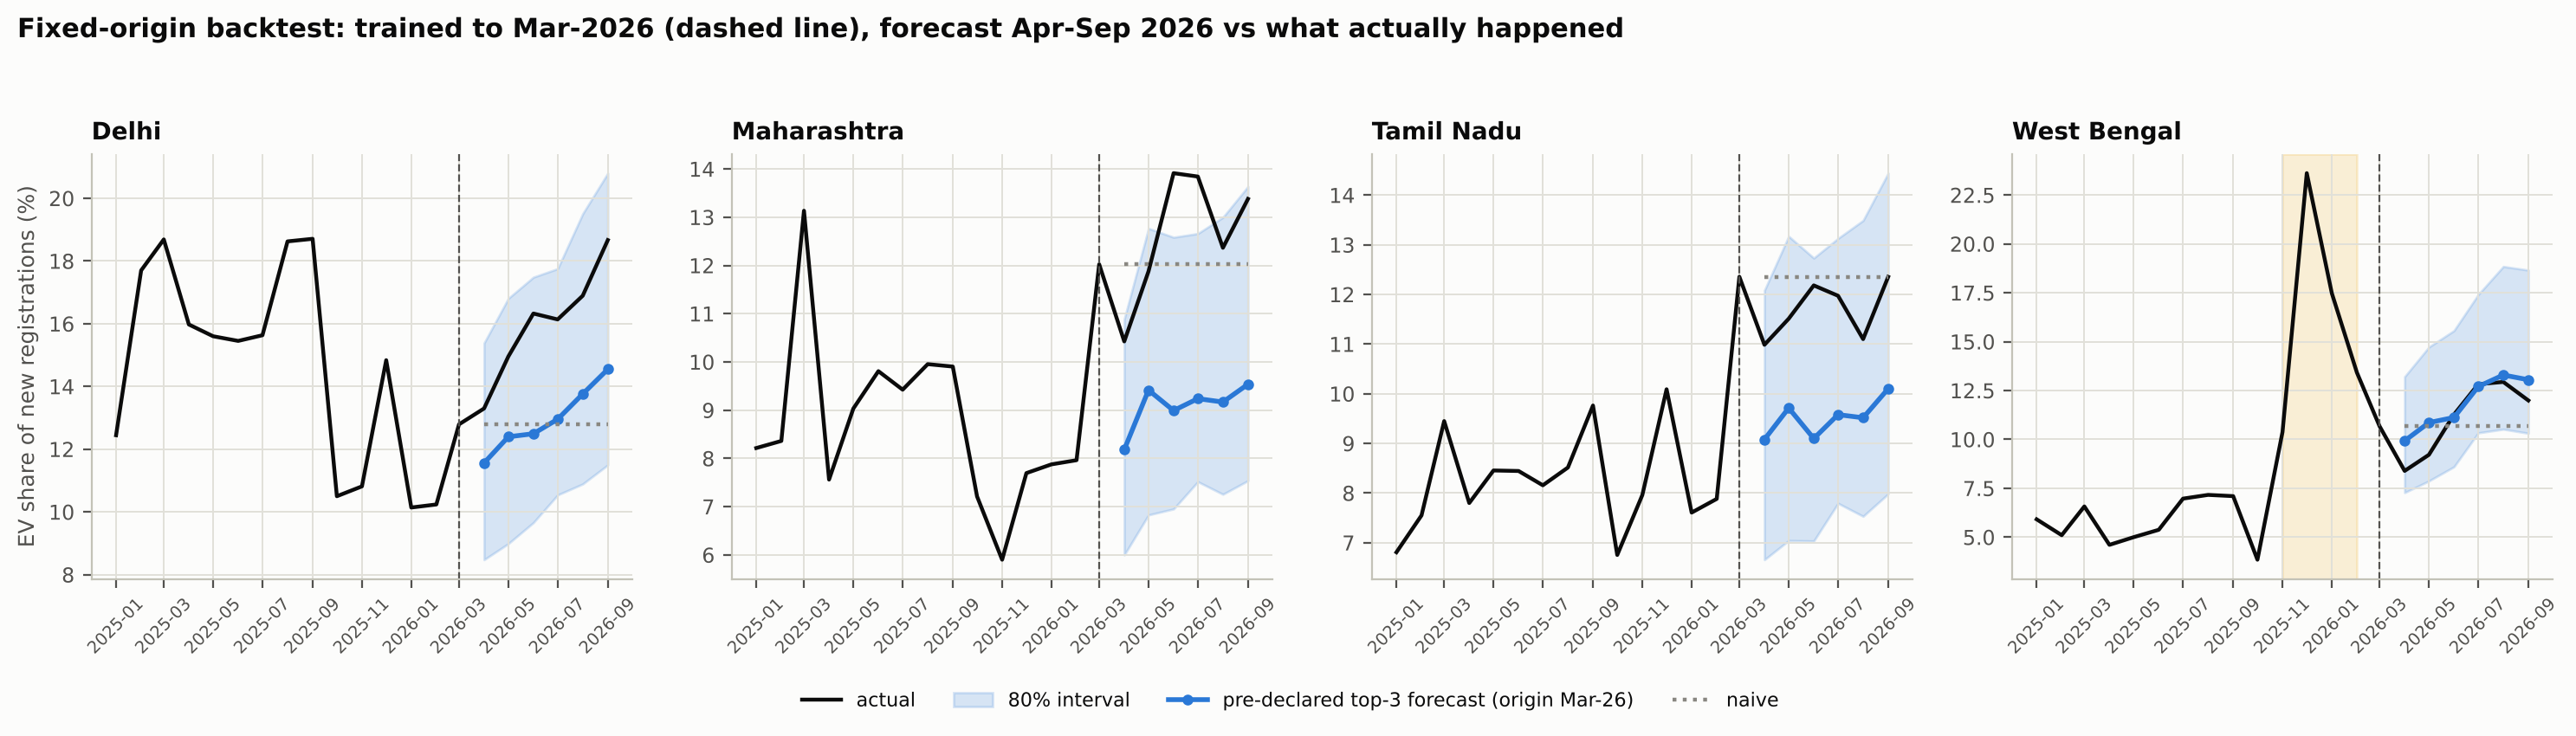

  [figure] outputs/figures/fig30_backtest_actual_vs_forecast.png


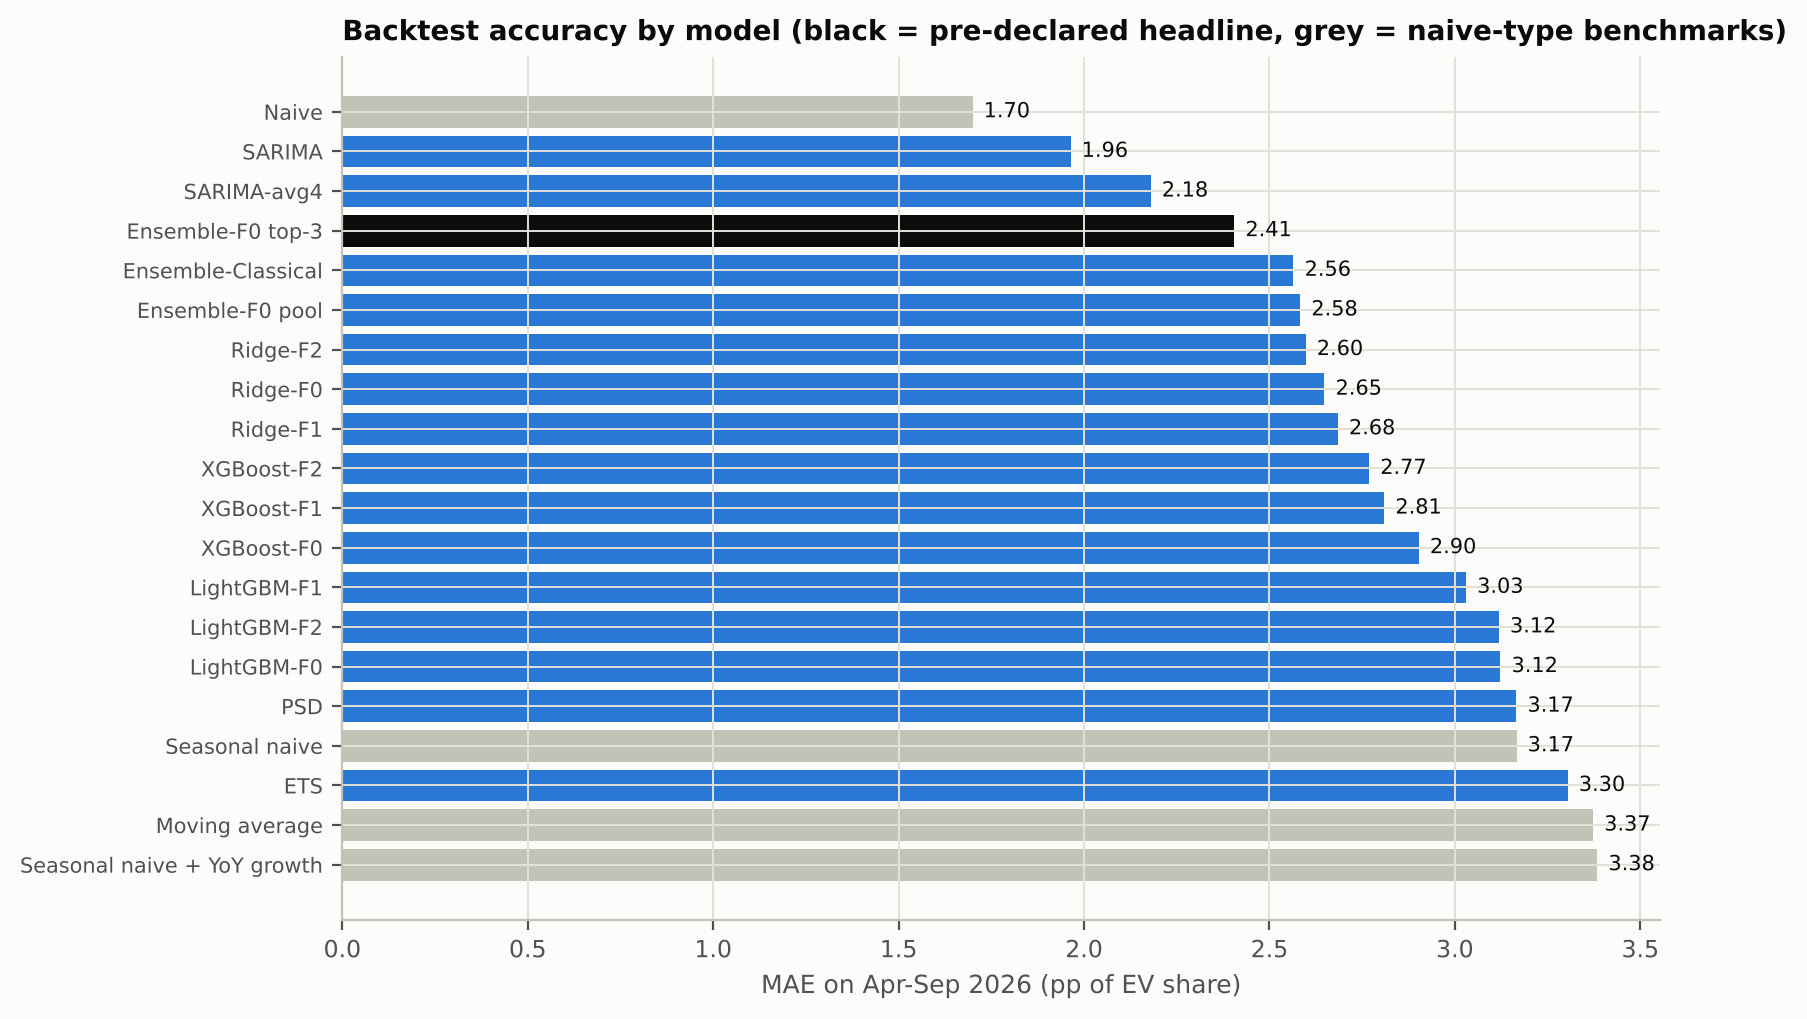

  [figure] outputs/figures/fig31_backtest_mae_by_model.png


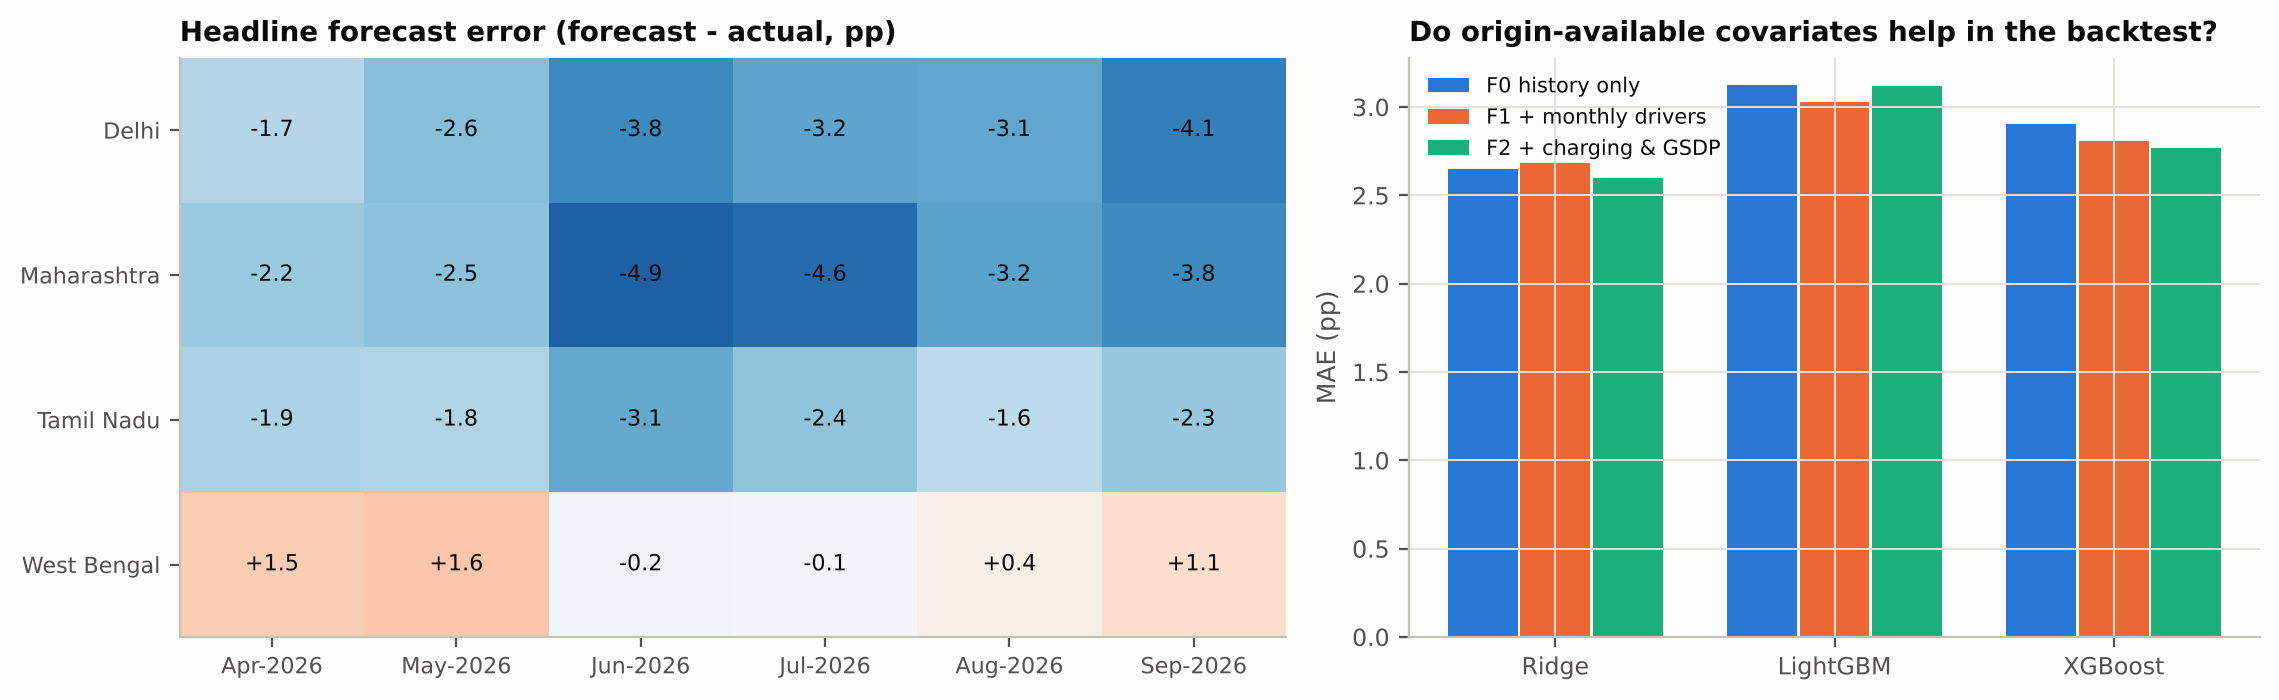

  [figure] outputs/figures/fig32_backtest_errors_and_covariates.png
  [json]   outputs/tables/10_summary.json

Mean signed error (forecast - actual, pp) in the backtest - negative = under-forecast:
 model        Ensemble-F0 top-3 (validation-selected)  Ensemble-F0 pool (equal weights)  SARIMA  Naive (last value)
state                                                                                                             
Delhi                                          -3.09                             -3.83    1.37               -3.26
Maharashtra                                    -3.55                             -3.53   -3.69               -0.61
Tamil Nadu                                     -2.17                             -2.08   -2.25                0.67
West Bengal                                     0.72                              0.85   -0.04               -0.43
  [table]  outputs/tables/10_backtest_bias_by_state.csv

Context - rolling-origin MAE (all origins, horizons 1-

PosixPath('/home/claude/ev_adoption_project/outputs/tables/10_backtest_context_vs_rolling.csv')

In [9]:
from common import *
from forecast_engine import HEADLINE, POOL, AVG4, CLASSIC_ENS, run_origin, interval_quantiles, apply_policy
from vintage import backlog_adjusted_rate

df = load_data(complete=False)
vp = pd.read_csv(BASE_DIR / "data" / "ev_panel_vintage.csv", parse_dates=["date"]).sort_values(["state", "date"])
protocol = json.loads((TAB_DIR / "02_selected_features_and_protocol.json").read_text())
SEL = protocol["selected_drivers"]
EXOG_F1 = [c for c in SEL if c not in ("charging_stations", "nsdp_per_capita")]
EXOG_F2 = EXOG_F1 + [c for c in ("charging_stations", "nsdp_per_capita") if c in SEL]
N_T = int(df.t.max() + 1)
ORIGIN = pd.Timestamp("2026-03-01")
O = int(df.loc[df.date == ORIGIN, "t"].iloc[0])
DATES = df[df.state == STATES[0]].sort_values("t").date.to_numpy()
Y_RAW = {s: df[df.state == s].sort_values("t")[TARGET].to_numpy() for s in STATES}
EX = {s: vp[vp.state == s].reset_index(drop=True)[EXOG_F2] for s in STATES}
adj, base3w = backlog_adjusted_rate(df)
print(f"origin {ORIGIN:%b-%Y} (t={O}); targets {pd.Timestamp(DATES[O + 1]):%b-%Y}..{pd.Timestamp(DATES[O + 6]):%b-%Y}; data end {pd.Timestamp(DATES[-1]):%b-%Y} (t={N_T - 1})")
assert O + 6 == N_T - 1, "six backtest months must exactly fill the data after the origin"

print("\nCovariates visible at the origin (vintage panel):")
print(vp[(vp.date == ORIGIN)][["state", "aqi_mean", "petrol_price", "charging_stations", "charging_snapshot_label", "nsdp_per_capita", "nsdp_fy_label", "nsdp_status_asof"]].to_string(index=False))

# ------------------------------------------------------------------ run the engine (as_reported: F0/F1/F2; backlog_removed: F0)
runs = []
f = run_origin(O, apply_policy(df, Y_RAW, "as_reported", adj), EX, {"F0": [], "F1": EXOG_F1, "F2": EXOG_F2}, DATES)
runs.append(f.assign(policy="as_reported")); print("SARIMA spec chosen:", f.attrs["sarima_choice"])
f2 = run_origin(O, apply_policy(df, Y_RAW, "backlog_removed", adj), EX, {"F0": []}, DATES)
runs.append(f2.assign(policy="backlog_removed"))
fc = pd.concat(runs, ignore_index=True)
truth = pd.DataFrame([{"state": s, "t": t, "y_true": Y_RAW[s][t]} for s in STATES for t in range(O + 1, N_T)])
fc = fc.merge(truth, on=["state", "t"])
fc["flag"] = fc.apply(lambda r: int(r.state == ANOMALY_STATE and ANOMALY_START <= r.date <= ANOMALY_END), axis=1)
assert fc.flag.sum() == 0
fc["abs_err"] = (fc.y_true - fc.y_pred).abs()

# ------------------------------------------------------------------ 80% intervals for the headline (errors realised by the origin only)
q = interval_quantiles(TAB_DIR / "04_rolling_origin_predictions.csv", O)
print("\nInterval calibration errors available at the origin (n per horizon):", q.n_errors.to_dict())
fc = fc.merge(q[["q10", "q90"]], left_on="h", right_index=True, how="left")
fc["lo80"], fc["hi80"] = fc.y_pred * np.exp(fc.q10), fc.y_pred * np.exp(fc.q90)
save_table(fc.drop(columns=["q10", "q90"]).round(5), "10_backtest_forecasts", index=False)

# ------------------------------------------------------------------ metrics
mase_scale = {s: np.mean(np.abs(np.diff(Y_RAW[s][:O + 1]))) for s in STATES}
last = {s: Y_RAW[s][O] for s in STATES}


def metrics(g: pd.DataFrame, naive_mae: float) -> dict:
    y, p = g.y_true.to_numpy(), g.y_pred.to_numpy()
    within = y - g.groupby("state").y_true.transform("mean").to_numpy()
    lo = g.state.map(last).to_numpy()
    return {"MAE_pp": 100 * np.mean(np.abs(y - p)), "RMSE_pp": 100 * np.sqrt(np.mean((y - p) ** 2)),
            "MAPE_%": 100 * np.mean(np.abs(y - p) / y), "sMAPE_%": 100 * smape(y, p),
            "MASE": float(np.mean(np.abs(y - p) / g.state.map(mase_scale).to_numpy())),
            "R2_pooled": 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2),
            "R2_within_state": 1 - np.sum((y - p) ** 2) / np.sum(within ** 2),
            "direction_correct_%": 100 * np.mean(np.sign(p - lo) == np.sign(y - lo)),
            "skill_vs_naive_%": 100 * (1 - np.mean(np.abs(y - p)) / naive_mae), "n": len(g)}


main = fc[fc.policy == "as_reported"]
naive_mae = main[main.model == "Naive (last value)"].abs_err.mean()
tab = pd.DataFrame({m: metrics(g, naive_mae) for m, g in main.groupby("model")}).T.sort_values("MAE_pp")
print("\nBACKTEST (origin Mar-2026, targets Apr-Sep 2026, 24 forecasts per model, as_reported history):\n", tab.round(3).to_string())
save_table(tab.round(4), "10_backtest_metrics")

# West Bengal policy comparison (exogenous-free models)
pol_rows = []
for pol, g in fc.groupby("policy"):
    for m in [HEADLINE, POOL, CLASSIC_ENS, "SARIMA", "ETS", "PSD (pooled seasonal + damped trend)", "SARIMA-avg4 (all specs averaged)", "Ridge-F0", "LightGBM-F0", "XGBoost-F0"]:
        d = g[g.model == m]
        pol_rows.append({"policy": pol, "model": m, "MAE_pp_all_states": 100 * d.abs_err.mean(), "MAE_pp_West_Bengal": 100 * d[d.state == ANOMALY_STATE].abs_err.mean(),
                         "MAE_pp_other_3_states": 100 * d[d.state != ANOMALY_STATE].abs_err.mean()})
pol = pd.DataFrame(pol_rows).pivot(index="model", columns="policy")
print("\nWest Bengal data policy (history fed to the models):\n", pol.round(2).to_string())
save_table(pol.round(4), "10_backtest_wb_policy")

# by state / by month / headline vs actual
H = main[main.model == HEADLINE].copy()
H["inside_80"] = (H.y_true >= H.lo80) & (H.y_true <= H.hi80)
by_state = pd.DataFrame({m: 100 * main[main.model == m].groupby("state").abs_err.mean() for m in [HEADLINE, POOL, "SARIMA", "ETS", "Naive (last value)", "Seasonal naive + YoY growth"]})[[HEADLINE, POOL, "SARIMA", "ETS", "Naive (last value)", "Seasonal naive + YoY growth"]].loc[STATES]
by_h = pd.DataFrame({m: 100 * main[main.model == m].groupby("h").abs_err.mean() for m in [HEADLINE, "SARIMA", "ETS", "Naive (last value)"]})
print("\nMAE (pp) by state:\n", by_state.round(2).to_string()); print("\nMAE (pp) by horizon (h = months after Mar-2026):\n", by_h.round(2).to_string())
save_table(by_state.round(3), "10_backtest_mae_by_state"); save_table(by_h.round(3), "10_backtest_mae_by_horizon")
show = H.assign(actual_pct=100 * H.y_true, forecast_pct=100 * H.y_pred, lo80_pct=100 * H.lo80, hi80_pct=100 * H.hi80, error_pp=100 * (H.y_pred - H.y_true))
show["month"] = show.date.dt.strftime("%b-%Y")
wide_tab = show[["state", "month", "actual_pct", "forecast_pct", "lo80_pct", "hi80_pct", "error_pp", "inside_80"]].round(2)
print(f"\nHeadline ({HEADLINE}) vs actual (EV share, %):\n", wide_tab.to_string(index=False))
save_table(wide_tab, "10_backtest_headline_vs_actual", index=False)
cov = float(H.inside_80.mean()); print(f"\n80% interval coverage on the 24 backtest forecasts: {100 * cov:.0f}% (nominal 80%); mean width {100 * (H.hi80 - H.lo80).mean():.2f} pp")

# do covariates help?  (same model, F0 vs F1 vs F2)
cv_rows = [{"model": n, **{fs: 100 * main[main.model == f"{n}-{fs}"].abs_err.mean() for fs in ("F0", "F1", "F2")}} for n in ("Ridge", "LightGBM", "XGBoost")]
cvt = pd.DataFrame(cv_rows).set_index("model"); cvt["F1 - F0"] = cvt.F1 - cvt.F0; cvt["F2 - F0"] = cvt.F2 - cvt.F0
print("\nBacktest MAE (pp) with / without origin-available covariates:\n", cvt.round(3).to_string())
save_table(cvt.round(3), "10_backtest_covariate_value")

# wins against the naive benchmark by state-month cell
piv = main.pivot_table(index=["state", "t"], columns="model", values="abs_err")
wins = {m: float((piv[m] < piv["Naive (last value)"]).mean() * 100) for m in piv.columns if m != "Naive (last value)"}
wins = pd.Series(wins).sort_values(ascending=False).round(1).to_frame("% of 24 cells beating naive")
save_table(wins, "10_backtest_win_rate_vs_naive"); print("\nShare of the 24 state-month cells where the model beat the naive forecast:\n", wins.head(8).to_string())

# ------------------------------------------------------------------ figures
set_style()
fig, axes = plt.subplots(1, 4, figsize=(15, 3.7), sharex=True)
for ax, s in zip(axes, STATES):
    g = df[(df.state == s) & (df.t >= 36)]
    ax.plot(g.date, 100 * g[TARGET], color=INK, lw=1.6, label="actual")
    h = H[H.state == s].sort_values("h")
    ax.fill_between(h.date, 100 * h.lo80, 100 * h.hi80, color="#2a78d6", alpha=.18, label="80% interval")
    ax.plot(h.date, 100 * h.y_pred, color="#2a78d6", lw=2, marker="o", ms=3.5, label="pre-declared top-3 forecast (origin Mar-26)")
    n_ = main[(main.model == "Naive (last value)") & (main.state == s)].sort_values("h")
    ax.plot(n_.date, 100 * n_.y_pred, color="#898781", ls=":", lw=1.6, label="naive")
    ax.axvline(ORIGIN, color=INK2, lw=0.8, ls="--")
    ax.axvspan(df.date[(df.state == s) & (df.anomaly_flag == 1)].min(), df.date[(df.state == s) & (df.anomaly_flag == 1)].max(), color="#eda100", alpha=.15) if s == ANOMALY_STATE else None
    ax.set_title(s, fontsize=10); ax.tick_params(axis="x", labelrotation=45, labelsize=7)
axes[0].set_ylabel("EV share of new registrations (%)")
h_, l_ = axes[0].get_legend_handles_labels(); fig.legend(h_, l_, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.07), fontsize=8)
fig.suptitle("Fixed-origin backtest: trained to Mar-2026 (dashed line), forecast Apr-Sep 2026 vs what actually happened", x=0.01, y=1.04, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout(); save_fig(fig, "fig30_backtest_actual_vs_forecast")

fig, ax = plt.subplots(figsize=(8.5, 5.2))
order = tab.index[::-1]
cols = ["#0b0b0b" if m == HEADLINE else ("#c3c2b7" if m.startswith(("Naive", "Moving", "Seasonal")) else "#2a78d6") for m in order]
ax.barh([m.split(" (")[0] for m in order], tab.loc[order, "MAE_pp"], color=cols)
for i, m in enumerate(order): ax.text(tab.loc[m, "MAE_pp"] + 0.03, i, f"{tab.loc[m, 'MAE_pp']:.2f}", va="center", fontsize=7.5)
ax.set_xlabel("MAE on Apr-Sep 2026 (pp of EV share)"); ax.tick_params(axis="y", labelsize=7.5)
ax.set_title("Backtest accuracy by model (black = pre-declared headline, grey = naive-type benchmarks)", fontsize=10)
fig.tight_layout(); save_fig(fig, "fig31_backtest_mae_by_model")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})
piv_e = show.pivot(index="state", columns="month", values="error_pp").loc[STATES][[d.strftime("%b-%Y") for d in sorted(show.date.unique())]]
im = axes[0].imshow(piv_e.values, cmap="RdBu_r", vmin=-6, vmax=6, aspect="auto"); axes[0].grid(False)
axes[0].set_xticks(range(6), piv_e.columns, fontsize=8); axes[0].set_yticks(range(4), STATES, fontsize=8)
for i in range(4):
    for j in range(6): axes[0].text(j, i, f"{piv_e.values[i, j]:+.1f}", ha="center", va="center", fontsize=8)
axes[0].set_title("Headline forecast error (forecast - actual, pp)", fontsize=10)
mods = ["Ridge", "LightGBM", "XGBoost"]
for i, fs in enumerate(["F0", "F1", "F2"]):
    axes[1].bar(np.arange(3) + (i - 1) * 0.26, cvt.loc[mods, fs], 0.25, color=["#2a78d6", "#eb6834", "#1baf7a"][i], label={"F0": "F0 history only", "F1": "F1 + monthly drivers", "F2": "F2 + charging & GSDP"}[fs])
axes[1].set_xticks(range(3), mods); axes[1].set_ylabel("MAE (pp)"); axes[1].legend(fontsize=7.5)
axes[1].set_title("Do origin-available covariates help in the backtest?", fontsize=10)
fig.tight_layout(); save_fig(fig, "fig32_backtest_errors_and_covariates")

best = tab.index[0]
save_json({"origin": f"{ORIGIN:%Y-%m}", "targets": f"{pd.Timestamp(DATES[O + 1]):%Y-%m}..{pd.Timestamp(DATES[O + 6]):%Y-%m}", "n_forecasts_per_model": 24,
           "headline": HEADLINE, "headline_MAE_pp": float(tab.loc[HEADLINE, "MAE_pp"]), "headline_R2_pooled": float(tab.loc[HEADLINE, "R2_pooled"]),
           "headline_R2_within_state": float(tab.loc[HEADLINE, "R2_within_state"]), "headline_skill_vs_naive_pct": float(tab.loc[HEADLINE, "skill_vs_naive_%"]),
           "naive_MAE_pp": float(tab.loc["Naive (last value)", "MAE_pp"]), "best_model_in_backtest": best, "best_MAE_pp": float(tab.loc[best, "MAE_pp"]),
           "headline_rank": int(list(tab.index).index(HEADLINE) + 1), "interval_coverage_80": cov, "sarima_choice": f.attrs["sarima_choice"]}, "10_summary")

# ------------------------------------------------------------------ diagnostics: bias, and the same six target months under ALL origins (stage 04)
bias = (100 * (main.assign(e=main.y_pred - main.y_true).pivot_table(index="state", columns="model", values="e"))[[HEADLINE, POOL, "SARIMA", "Naive (last value)"]]).loc[STATES]
print("\nMean signed error (forecast - actual, pp) in the backtest - negative = under-forecast:\n", bias.round(2).to_string())
save_table(bias.round(3), "10_backtest_bias_by_state")
ev04 = pd.read_csv(TAB_DIR / "04_rolling_origin_predictions.csv", parse_dates=["date"])
same = ev04[(ev04.date >= "2026-04-01") & (ev04.date <= "2026-09-01") & (ev04.flag == 0) & ~ev04.model.str.contains(r"\[backlog")]
ctx = pd.DataFrame({"rolling_MAE_same_target_months_pp": 100 * same.groupby("model").abs_err.mean(),
                    "rolling_all_test_MAE_pp": 100 * ev04[(ev04.period == "test") & (ev04.flag == 0) & ~ev04.model.str.contains(r"\[backlog")].groupby("model").abs_err.mean()}).loc[[HEADLINE, POOL, "SARIMA", AVG4, "Naive (last value)"]]
print("\nContext - rolling-origin MAE (all origins, horizons 1-6) for the SAME Apr-Sep 2026 targets vs the whole test window:\n", ctx.round(2).to_string())
save_table(ctx.round(3), "10_backtest_context_vs_rolling")


## `05_final_forecast_and_scenarios.py`
05_final_forecast_and_scenarios.py -- RETRAIN ON ALL DATA and forecast the next six months (frozen on creation); what-if scenarios
================================================================================================================================
Origin = Sep-2026 (last month with verified registrations).  Same engine as the backtest (forecast_engine.py): hyper-parameters, SARIMA
specifications and all model fits are re-estimated on every observation through Sep-2026; covariates come from the release-aligned vintage
panel.  HEADLINE = the pre-declared top-3 ensemble (3 best exogenous-free models on the 2024 validation window: SARIMA, ETS, XGBoost-F0).  The equal-weight
pool of 7 exogenous-free models is reported alongside as an EXPLORATORY comparison.  Intervals: 10/90%
quantiles of log forecast errors already realised by the origin (stage 04 rolling-origin errors).
Three West Bengal data policies for the Nov-25..Feb-26 registration-drive months:
  as_reported      - data as supplied (a seasonal model replays the winter spike next winter: implausible)
  capped           - flagged months limited to the pre-episode 12-month maximum
  backlog_removed  - excess three-wheelers removed (stage 07): the PRINCIPLED default
Scenario layer (retrospective explanatory models): associations only, see the cautions printed at the end.
The forecast file is frozen ONCE per run date (data/frozen_forecasts_made_<date>.csv, never overwritten); earlier frozen files are kept.
Run from the project root after stages 00a-04:  python 05_final_forecast_and_scenarios.py

Retrain on ALL data through Sep-2026 (t=56); forecast Oct-2026..Mar-2027 | headline: Ensemble-F0 top-3 (validation-selected)
interval calibration errors per horizon: {1: 128, 2: 128, 3: 128, 4: 128, 5: 128, 6: 128}

--- policy as_reported


    origin t=56: ML tuned/fitted for F0



--- policy capped


    origin t=56: ML tuned/fitted for F0



--- policy backlog_removed


    origin t=56: ML tuned/fitted for F0


  [table]  outputs/tables/05_forecast_next6m.csv
  [frozen file for this data cut-off and headline already exists - not overwritten]: frozen_forecasts_made_2026-11-18.csv

Headline (pre-declared top-3) forecast, EV share % (policy = backlog_removed):
state       Delhi  Maharashtra  Tamil Nadu  West Bengal
date                                                   
2026-10-01  14.20        10.51        9.81         8.94
2026-11-01  13.71         8.20       10.10         8.00
2026-12-01  19.47        10.32       12.59        10.98
2027-01-01  14.58         9.95        9.44        10.11
2027-02-01  15.42        10.72       10.61        10.62
2027-03-01  19.30        16.34       16.25        17.90

80% intervals:
       state       date  lo80  Headline  hi80
      Delhi 2026-10-01 10.72     14.20 18.84
      Delhi 2026-11-01 10.43     13.71 18.65
      Delhi 2026-12-01 15.25     19.47 27.65
      Delhi 2027-01-01 11.79     14.58 20.71
      Delhi 2027-02-01 12.42     15.42 22.51
      Delhi 20

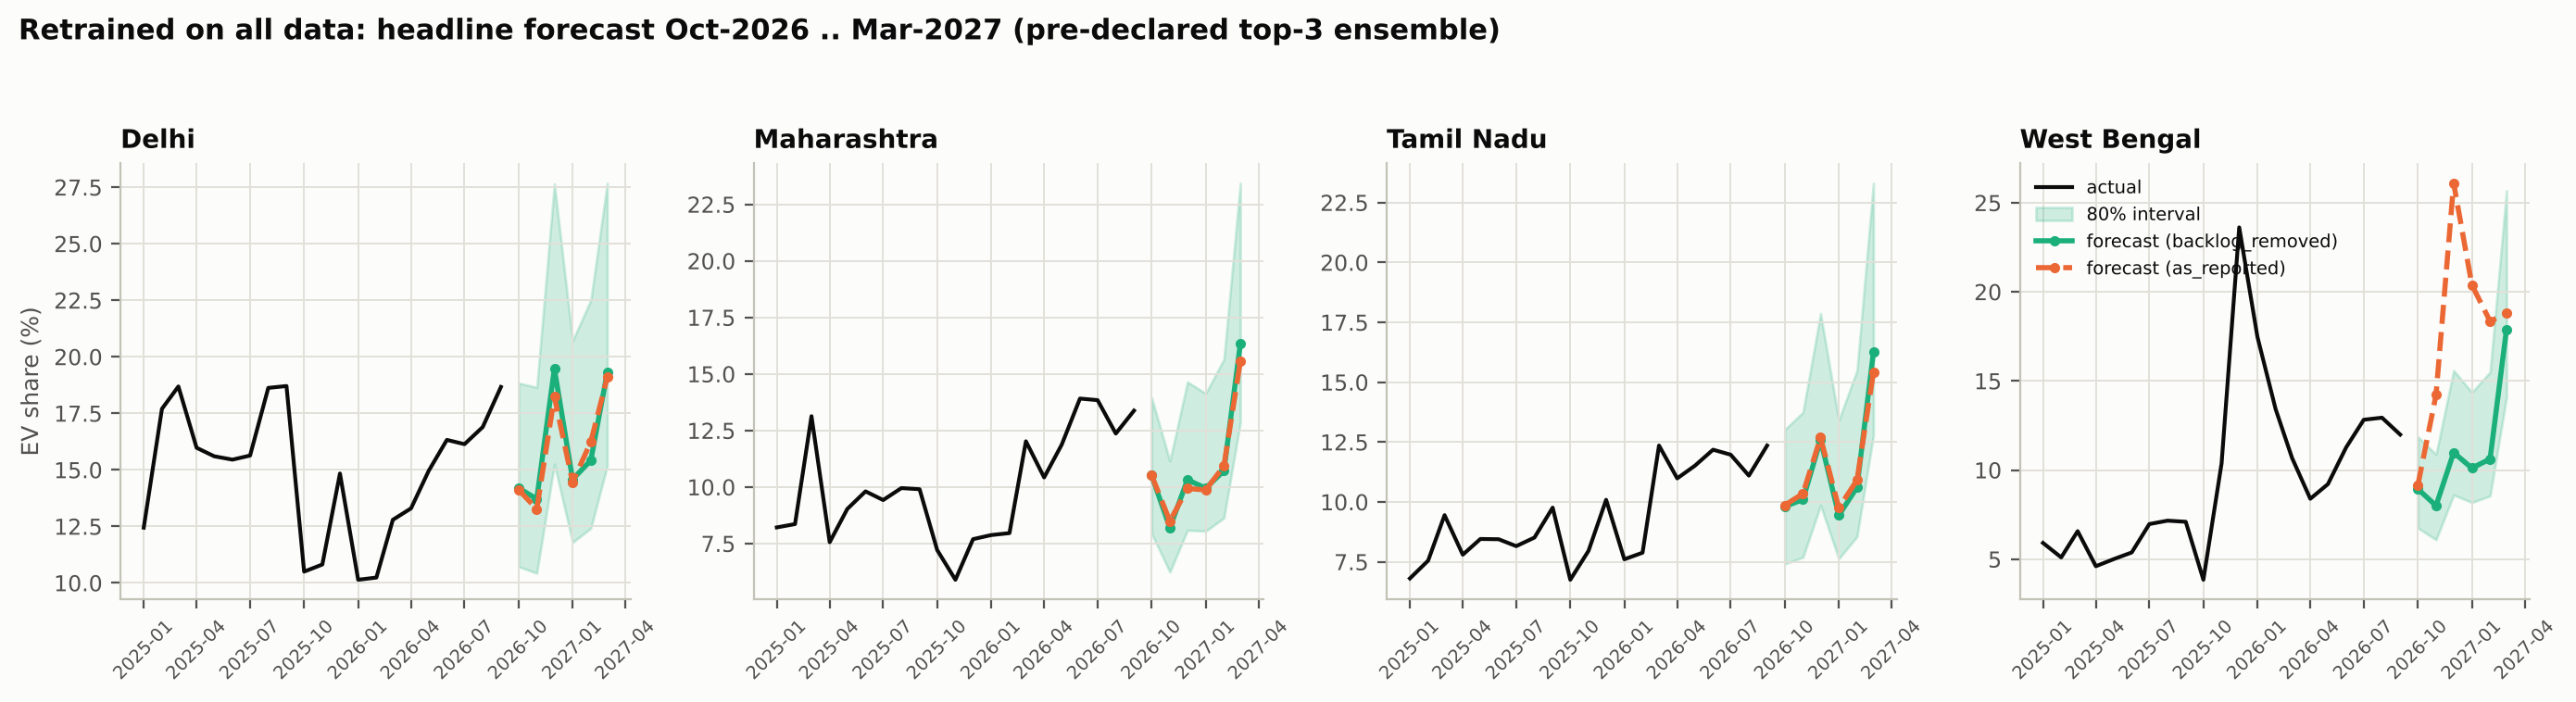

  [figure] outputs/figures/fig19b_forecast_next6m.png

WHAT-IF SCENARIOS - retrospective explanatory models, associations only


model                               LightGBM  RandomForest  Ridge  XGBoost   min   max  models_agree_on_sign
scenario               state                                                                                
Both                   Delhi            0.01         -0.78   0.71    -0.47 -0.78  0.71                 False
                       Maharashtra      0.49          0.11   1.68     0.59  0.11  1.68                  True
                       Tamil Nadu       1.10          0.92   0.49     1.27  0.49  1.27                  True
                       West Bengal     -0.01         -0.05   0.04    -0.06 -0.06  0.04                 False
Charging stations +50% Delhi           -0.00         -0.16   1.02    -0.09 -0.16  1.02                 False
                       Maharashtra      0.00          0.00   2.02     0.08  0.00  2.02                 False
                       Tamil Nadu       0.71          0.80   0.82     0.87  0.71  0.87                  True
                   

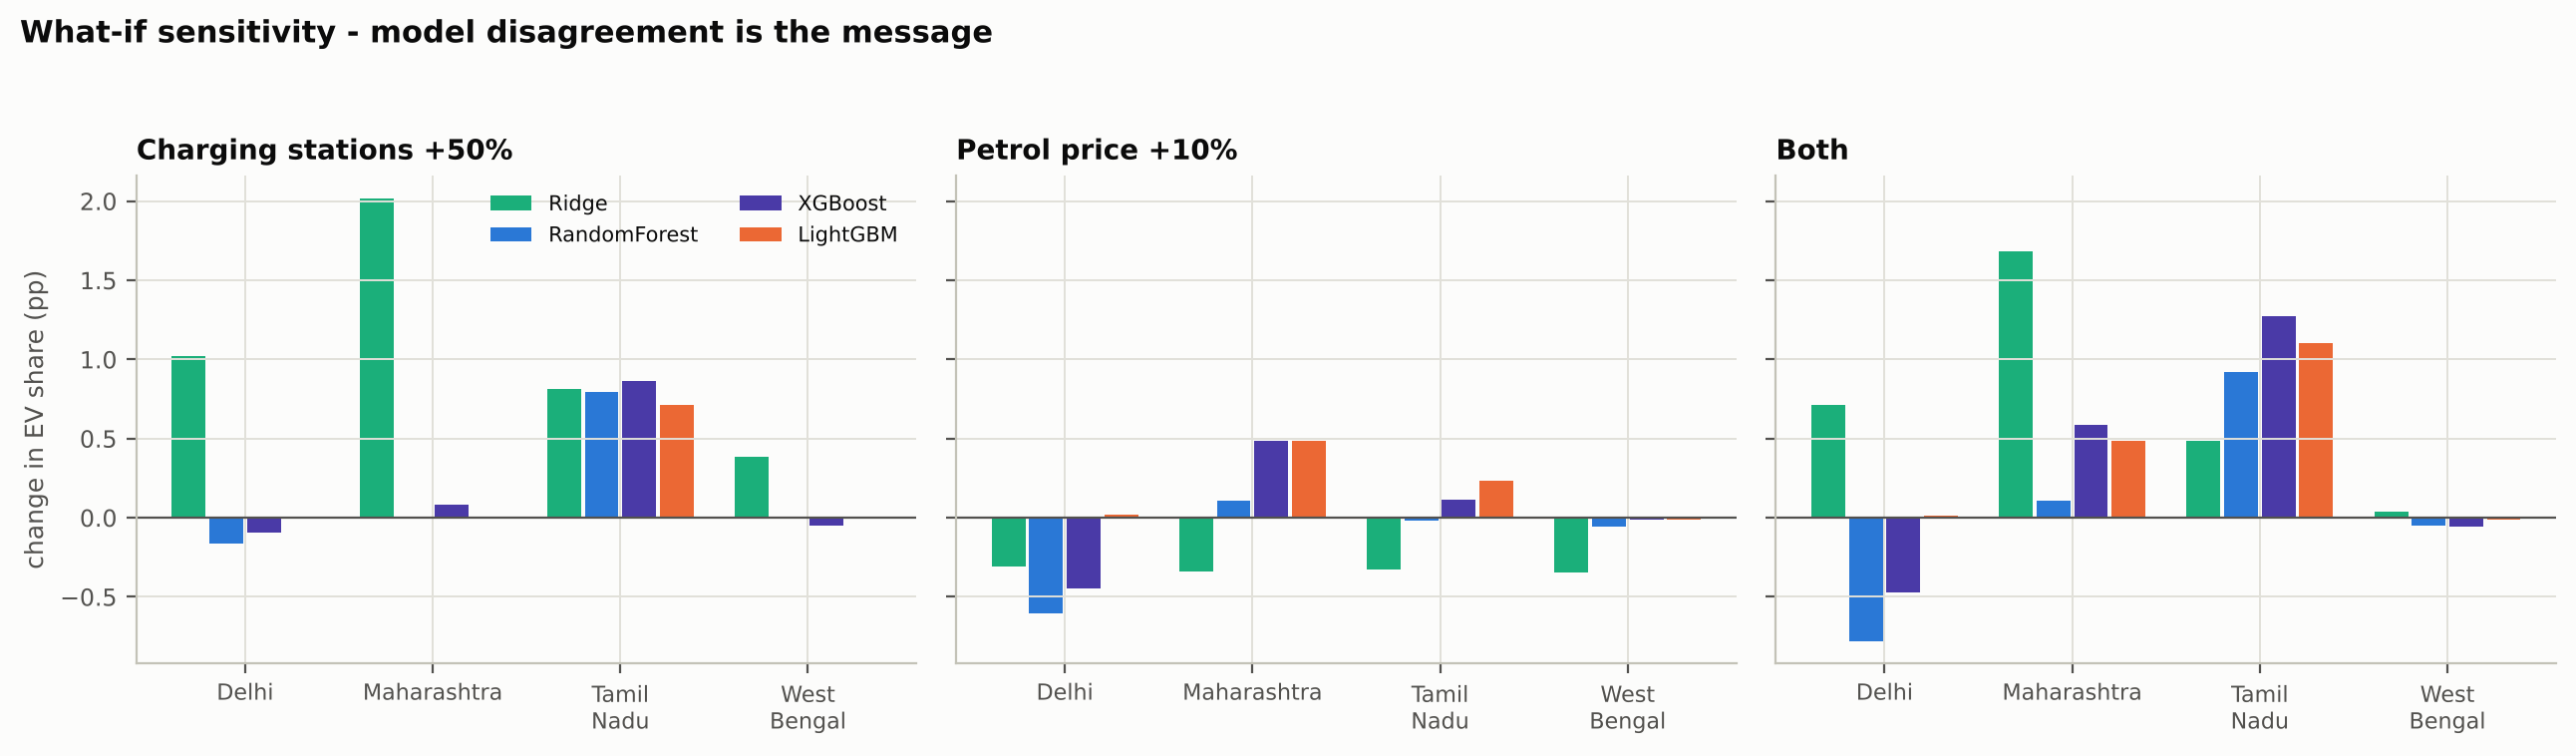

  [figure] outputs/figures/fig20_scenarios.png

Share of scenario cells where all four models agree on the sign: 33%
Treat any scenario number as a model-implied association, not as the causal effect of a policy.
CAUTION 1: the models disagree on the sign of a petrol-price change - the data do not identify a fuel-price effect.
CAUTION 2: charging +50% has near-zero effect in trees (flat between observed step values) and a different sign in some models
  - the data contain too few distinct charging values (3-4 per state) to support a what-if on infrastructure.


In [10]:
from common import *
from forecast_engine import HEADLINE, POOL, run_origin, interval_quantiles, apply_policy
from vintage import backlog_adjusted_rate
import joblib
from sklearn.base import clone

dfa = load_data(complete=False)                                    # registrations through Sep-2026
vp = pd.read_csv(BASE_DIR / "data" / "ev_panel_vintage.csv", parse_dates=["date"]).sort_values(["state", "date"])
protocol = json.loads((TAB_DIR / "02_selected_features_and_protocol.json").read_text())
EXOG = protocol["selected_drivers"]
EXOG_F2 = EXOG
N_A = int(dfa.t.max() + 1); O = N_A - 1
Y_RAW = {s: dfa[dfa.state == s].sort_values("t")[TARGET].to_numpy() for s in STATES}
EX = {s: vp[vp.state == s].reset_index(drop=True)[EXOG_F2] for s in STATES}
future_dates = pd.date_range(dfa.date.max() + pd.offsets.MonthBegin(1), periods=6, freq="MS")
DATES = list(dfa[dfa.state == STATES[0]].sort_values("t").date) + list(future_dates)
adj, base3w = backlog_adjusted_rate(dfa)
print(f"Retrain on ALL data through {dfa.date.max():%b-%Y} (t={O}); forecast {future_dates[0]:%b-%Y}..{future_dates[-1]:%b-%Y} | headline: {HEADLINE}")
q = interval_quantiles(TAB_DIR / "04_rolling_origin_predictions.csv", O)
print("interval calibration errors per horizon:", q.n_errors.to_dict())

frames = []
for policy in ["as_reported", "capped", "backlog_removed"]:
    print(f"\n--- policy {policy}", flush=True)
    f = run_origin(O, apply_policy(dfa, Y_RAW, policy, adj), EX, {"F0": []}, DATES)
    wide = f.pivot_table(index=["state", "h", "date"], columns="model", values="y_pred").reset_index()
    wide["Headline"] = wide[HEADLINE]; wide["Pool (equal weights)"] = wide[POOL]
    wide = wide.merge(q[["q10", "q90"]], left_on="h", right_index=True)
    wide["lo80"], wide["hi80"] = wide.Headline * np.exp(wide.q10), wide.Headline * np.exp(wide.q90)
    wide["policy"] = policy; frames.append(wide)
fc = pd.concat(frames, ignore_index=True)
pct = [c for c in fc.columns if c not in ("state", "h", "date", "q10", "q90", "policy")]
fc_out = fc.copy(); fc_out[pct] = (100 * fc_out[pct]).round(2); fc_out = fc_out.drop(columns=["q10", "q90"])
save_table(fc_out, "05_forecast_next6m", index=False)
frozen_name = f"frozen_forecasts_made_{pd.Timestamp.today():%Y-%m-%d}.csv"
_already = [p_ for p_ in (BASE_DIR / "data").glob("frozen_forecasts_made_*.csv")
            if {"data_cutoff", "headline_model"} <= set(pd.read_csv(p_, nrows=1).columns)
            and pd.read_csv(p_, nrows=1).data_cutoff.iloc[0] == f"{DATA_CUTOFF:%Y-%m}" and pd.read_csv(p_, nrows=1).headline_model.iloc[0] == HEADLINE]
if not _already:                                                      # freeze ONCE per (data cut-off, headline definition); never overwrite
    fc_out[["state", "h", "date", "policy", "Headline", "Pool (equal weights)", "lo80", "hi80", "SARIMA", "ETS", "XGBoost-F0"]].assign(
        data_cutoff=f"{DATA_CUTOFF:%Y-%m}", headline_model=HEADLINE).to_csv(BASE_DIR / "data" / frozen_name, index=False)
    print("  [frozen]", frozen_name)
else:
    print("  [frozen file for this data cut-off and headline already exists - not overwritten]:", _already[0].name)

main = fc_out[fc_out.policy == "backlog_removed"]
print("\nHeadline (pre-declared top-3) forecast, EV share % (policy = backlog_removed):")
print(main.pivot(index="date", columns="state", values="Headline")[STATES].to_string())
print("\n80% intervals:\n", main[["state", "date", "lo80", "Headline", "hi80"]].to_string(index=False))
print("\nWest Bengal headline forecast by policy (EV share %):")
print(pd.DataFrame({p: fc_out[(fc_out.policy == p) & (fc_out.state == ANOMALY_STATE)].set_index("date").Headline for p in ["as_reported", "capped", "backlog_removed"]}).to_string())
prev = dfa[dfa.date.isin(future_dates - pd.DateOffset(years=1))].groupby("state")[TARGET].mean() * 100
last6 = dfa[dfa.date > dfa.date.max() - pd.DateOffset(months=6)].groupby("state")[TARGET].mean() * 100
summ = main.groupby("state").Headline.mean().to_frame("forecast_next6m_mean_%").join(prev.rename("same_months_last_year_%")).join(last6.rename("last6m_actual_mean_%")).loc[STATES]
summ["change_vs_last_year_pp"] = summ.iloc[:, 0] - summ.iloc[:, 1]; summ["change_vs_last6m_pp"] = summ.iloc[:, 0] - summ.iloc[:, 2]
print("\nNext-6-month average vs the same months a year earlier and vs the last 6 observed months (WB year-earlier base contains the drive):"); print(summ.round(2).to_string())
save_table(summ.round(3), "05_next6m_vs_year_earlier")

set_style()
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharex=True)
for ax, s in zip(axes, STATES):
    g = dfa[(dfa.state == s) & (dfa.t >= 36)]
    ax.plot(g.date, 100 * g[TARGET], color=INK, lw=1.5, label="actual")
    for pol, col, ls in [("backlog_removed", "#1baf7a", "-"), ("as_reported", "#eb6834", "--")]:
        d = fc_out[(fc_out.policy == pol) & (fc_out.state == s)].sort_values("h")
        if pol == "backlog_removed":
            ax.fill_between(d.date, d.lo80, d.hi80, color=col, alpha=.2, label="80% interval")
        ax.plot(d.date, d.Headline, color=col, ls=ls, lw=2, marker="o", ms=3, label=f"forecast ({pol})" if s == ANOMALY_STATE else None)
    ax.set_title(s, fontsize=10); ax.tick_params(axis="x", labelrotation=45, labelsize=7)
axes[0].set_ylabel("EV share (%)"); axes[-1].legend(fontsize=7)
fig.suptitle(f"Retrained on all data: headline forecast {future_dates[0]:%b-%Y} .. {future_dates[-1]:%b-%Y} (pre-declared top-3 ensemble)", x=0.01, y=1.04, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout(); save_fig(fig, "fig19b_forecast_next6m")

# scenarios use the complete-covariate panel (through Aug-2026)
df = load_data(); N_T = int(df.t.max() + 1)
# ----------------------------------------------------------------------------------------------- scenarios (retrospective)
print("\n" + "=" * 100 + "\nWHAT-IF SCENARIOS - retrospective explanatory models, associations only\n" + "=" * 100)
expl = joblib.load(BASE_DIR / "outputs" / "models" / "explanatory_models_tuned.joblib")
FEATURES = EXOG + protocol["calendar_features"]
fit_all = {n: clone(m).fit(df[FEATURES], df[TARGET]) for n, m in expl.items()}
base_rows = df[(df.t > N_T - 13) & (df.anomaly_flag == 0)].copy()

SCENARIOS = {"Charging stations +50%": {"charging_stations": 1.5},
             "Petrol price +10%": {"petrol_price": 1.10},
             "Both": {"charging_stations": 1.5, "petrol_price": 1.10}}
out = []
for sc, mult in SCENARIOS.items():
    shifted = base_rows.copy()
    for c, f in mult.items():
        shifted[c] = shifted[c] * f
    for n, m in fit_all.items():
        delta = 100 * (m.predict(shifted[FEATURES]) - m.predict(base_rows[FEATURES]))
        by = pd.Series(delta, index=base_rows.index).groupby(base_rows.state).mean()
        for s in STATES:
            out.append({"scenario": sc, "model": n, "state": s, "delta_pp": by[s]})
sc_tab = pd.DataFrame(out)
sc_piv = sc_tab.pivot_table(index=["scenario", "state"], columns="model", values="delta_pp")
sc_piv["min"] = sc_piv.min(axis=1); sc_piv["max"] = sc_piv[list(expl)].max(axis=1)
sc_piv["models_agree_on_sign"] = np.sign(sc_piv[list(expl)]).nunique(axis=1) == 1
print(sc_piv.round(2).to_string())
save_table(sc_piv.round(3), "05_scenario_analysis")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
mcol = {"Ridge": "#1baf7a", "RandomForest": "#2a78d6", "XGBoost": "#4a3aa7", "LightGBM": "#eb6834"}
for ax, sc in zip(axes, SCENARIOS):
    d = sc_tab[sc_tab.scenario == sc]
    for i, n in enumerate(expl):
        v = d[d.model == n].set_index("state").loc[STATES, "delta_pp"]
        ax.bar(np.arange(4) + (i - 1.5) * 0.2, v, 0.18, color=mcol[n], label=n)
    ax.axhline(0, color=INK2, lw=0.8); ax.set_xticks(range(4), [s.replace(" ", "\n") for s in STATES], fontsize=8)
    ax.set_title(sc, fontsize=10)
axes[0].set_ylabel("change in EV share (pp)"); axes[0].legend(fontsize=7.5, ncol=2)
fig.suptitle("What-if sensitivity - model disagreement is the message", x=0.01, y=1.04, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout(); save_fig(fig, "fig20_scenarios")

agree_share = float(sc_piv.models_agree_on_sign.mean())
print(f"\nShare of scenario cells where all four models agree on the sign: {100 * agree_share:.0f}%")
print("Treat any scenario number as a model-implied association, not as the causal effect of a policy.")
petrol_delta = sc_tab[(sc_tab.scenario == "Petrol price +10%")].delta_pp
if (petrol_delta < 0).all():
    print("CAUTION 1: a +10% petrol price LOWERS predicted EV share in every state-model cell - the OPPOSITE of the economic prior"
          "\n  (dearer petrol should favour EVs). The model has learned a trend/composition effect, not a price elasticity.")
elif (petrol_delta > 0).mean() > 0.75:
    print("CAUTION 1: a +10% petrol price RAISES predicted EV share in most cells, as theory would suggest - but the identifying variation"
          "\n  is mostly ONE fuel-price step in May-Jun 2026 that coincides with a general upswing, so treat the size as indicative only.")
else:
    print("CAUTION 1: the models disagree on the sign of a petrol-price change - the data do not identify a fuel-price effect.")
print("CAUTION 2: charging +50% has near-zero effect in trees (flat between observed step values) and a different sign in some models"
      "\n  - the data contain too few distinct charging values (3-4 per state) to support a what-if on infrastructure.")


## `06_frozen_forecast_scorecard.py`
06_frozen_forecast_scorecard.py -- score a FROZEN forecast file against actuals that arrived afterwards
=======================================================================================================
Stage 05 freezes its forecast once (data/frozen_forecasts_made_<date>.csv, never overwritten).  Re-run this script
whenever new months are added to the raw file and DATA_CUTOFF in common.py is moved forward: it scores every frozen
month that now has an actual.  The earlier 2026-10-09 freeze (origin Dec-2025, targets Jan-Jun 2026, produced by the earlier pipeline) is recorded in
docs/frozen_forecast_2026-10-09_scorecard.md.
Run from the project root:  python 06_frozen_forecast_scorecard.py [frozen_file.csv]

In [11]:
import sys
from common import *

files = sorted((BASE_DIR / "data").glob("frozen_forecasts_made_*.csv"))
if len(sys.argv) > 1 and sys.argv[1].endswith(".csv"):
    files = [BASE_DIR / sys.argv[1]]
raw = load_data(complete=False)
actual = raw[["state", "date", TARGET]].assign(actual=lambda d: 100 * d[TARGET]).drop(columns=TARGET)
summary = {}
for path in files:
    frozen = pd.read_csv(path, parse_dates=["date"])
    f = frozen.merge(actual, on=["state", "date"], how="inner")
    print(f"\nFrozen file: {path.name} | forecast months {frozen.date.min():%b-%Y}..{frozen.date.max():%b-%Y} | verified actuals available through {DATA_CUTOFF:%b-%Y}")
    if f.empty:
        print("  no frozen month has a verified actual yet"); summary[path.name] = {"scored_months": 0}; continue
    cols = [c for c in ["Headline", "Pool (equal weights)", "SARIMA", "ETS", "XGBoost-F0"] if c in f.columns]
    rows = {}
    for pol, g in f.groupby("policy"):
        rows[pol] = {c: (g[c] - g.actual).abs().mean() for c in cols}
        rows[pol]["80% interval coverage %"] = 100 * ((g.actual >= g.lo80) & (g.actual <= g.hi80)).mean()
        rows[pol]["n forecasts"] = len(g)
    score = pd.DataFrame(rows); print(score.round(2).to_string())
    save_table(score.round(3), f"06_frozen_forecast_mae_{path.stem[-10:]}"); summary[path.name] = {"scored_months": int(f.date.nunique())}
save_json(summary, "06_summary")



Frozen file: frozen_forecasts_made_2026-11-11.csv | forecast months Sep-2026..Feb-2027 | verified actuals available through Sep-2026
                         as_reported  backlog_removed  capped
Headline                        0.97             0.91    0.70
Pool (equal weights)            0.93             0.89    0.72
SARIMA                          1.05             0.88    0.87
ETS                             1.19             1.30    0.84
XGBoost-F0                      0.66             0.55    0.54
80% interval coverage %       100.00           100.00  100.00
n forecasts                     4.00             4.00    4.00
  [table]  outputs/tables/06_frozen_forecast_mae_2026-11-11.csv

Frozen file: frozen_forecasts_made_2026-11-16.csv | forecast months Oct-2026..Mar-2027 | verified actuals available through Sep-2026
  no frozen month has a verified actual yet

Frozen file: frozen_forecasts_made_2026-11-18.csv | forecast months Oct-2026..Mar-2027 | verified actuals available through Sep

PosixPath('/home/claude/ev_adoption_project/outputs/tables/06_summary.json')

## `08_additional_metrics.py`
08_additional_metrics.py -- R2, percentage errors and skill scores for the rolling-origin forecasts
==================================================================================================
Reader-friendly views of the SAME forecasts as stage 04 (test window, flagged West Bengal months excluded).
  * pooled R2 mixes between-state differences (easy) with within-state movement (hard) -> also report within-state R2
    (each state's own mean removed) and R2 of CHANGES (forecast minus last observed value vs actual change).
  * skill vs naive = 1 - MAE / MAE(naive).   Percentages are of the actual EV share.
Run from the project root after stage 04:  python 08_additional_metrics.py

In [12]:
from common import *

ev = pd.read_csv(TAB_DIR / "04_rolling_origin_predictions.csv", parse_dates=["date"])
ev = ev[(ev.period == "test") & (ev.flag == 0) & ~ev.model.str.contains(r"\[backlog")]
naive = ev[ev.model == "Naive (last value)"].set_index(["state", "h", "t"]).y_pred.rename("last_obs")
rows = []
mae_naive = ev[ev.model == "Naive (last value)"].eval("abs(y_true-y_pred)").mean()
for m, g in ev.groupby("model"):
    g = g.set_index(["state", "h", "t"]).join(naive)
    y, p = g.y_true.to_numpy(), g.y_pred.to_numpy()
    within_y = y - g.groupby("state").y_true.transform("mean").to_numpy()
    r2_pooled = 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)
    r2_within = 1 - np.sum((y - p) ** 2) / np.sum(within_y ** 2)
    dy, dp = y - g.last_obs.to_numpy(), p - g.last_obs.to_numpy()
    r2_change = 1 - np.sum((dy - dp) ** 2) / np.sum((dy - dy.mean()) ** 2)
    rows.append({"model": m, "R2_pooled": r2_pooled, "R2_within_state": r2_within, "R2_of_changes": r2_change,
                 "MAE_pp": 100 * np.mean(np.abs(y - p)), "MAPE_%": 100 * np.mean(np.abs(y - p) / y),
                 "median_abs_%_error": 100 * np.median(np.abs(y - p) / y), "within_1pp_%": 100 * np.mean(np.abs(y - p) <= 0.01),
                 "within_2pp_%": 100 * np.mean(np.abs(y - p) <= 0.02), "skill_vs_naive_%": 100 * (1 - np.mean(np.abs(y - p)) / mae_naive)})
out = pd.DataFrame(rows).set_index("model").sort_values("MAE_pp").round(3)
print(out.to_string())
save_table(out, "08_additional_metrics")
h = ev[ev.model == "SARIMA-avg4 (all specs averaged)"]
byh = h.groupby("h").apply(lambda d: pd.Series({"MAE_pp": 100 * d.abs_err.mean(), "MAPE_%": 100 * (d.abs_err / d.y_true).mean()})).round(2)
print("\nBest single model by horizon:\n", byh.to_string()); save_table(byh, "08_best_model_by_horizon")


                                          R2_pooled  R2_within_state  R2_of_changes  MAE_pp  MAPE_%  median_abs_%_error  within_1pp_%  within_2pp_%  skill_vs_naive_%
model                                                                                                                                                                
SARIMA-avg4 (all specs averaged)              0.487           -0.083          0.339   1.843  17.045              11.644        46.250        64.583            21.398
Ensemble-F0 pool (equal weights)              0.488           -0.080          0.341   1.904  17.529              13.063        42.292        63.750            18.785
SARIMA                                        0.475           -0.106          0.325   1.933  17.727              12.047        42.292        62.083            17.537
Ensemble-F0 top-3 (validation-selected)       0.474           -0.110          0.322   1.945  17.694              13.475        40.417        62.917            17.053
Ense

PosixPath('/home/claude/ev_adoption_project/outputs/tables/08_best_model_by_horizon.csv')

## `09_aggregate_analysis.py`
09_aggregate_analysis.py -- ONE combined series (4 states pooled): forecast it, then look for the drivers
===========================================================================================================
Aggregate EV share = sum(EV registrations) / sum(all registrations) over Delhi, Maharashtra, Tamil Nadu and West Bengal.
(This is a four-state aggregate, NOT India; Maharashtra's volume dominates it.)

Part A  FORECAST  : same rolling-origin protocol as stage 04 (test targets Jan-2025..cut-off, horizons 1-6, validation 2024),
                    release-aligned covariates (vintage panel), models run on a single series.
Part B  COMPARE   : top-down (this aggregate model) vs bottom-up (state SARIMA forecasts weighted by trailing volumes).
Part C  EXPLAIN   : same-month associations - ML + SHAP and HAC regressions on the aggregate (n ~ 56 months: treat as indicative).
Two versions of the series are used:  as_reported (PRINCIPAL; the 4 flagged West Bengal months are excluded from the scores,
exactly as in stage 04) and backlog_removed (sensitivity: excess e-rickshaw registrations taken out of numerator and
denominator, stage 07, all months scored; its R2 is lower because the removal is an estimate and the series is noisier).
Run from the project root after stages 00-04:  python 09_aggregate_analysis.py

Aggregate series: 57 months | flagged months 4 | WB baseline three-wheelers 3710
Aggregate EV share % (as reported vs backlog removed), flagged window:
            as_reported_%  backlog_removed_%
2025-11-01           7.68               6.63
2025-12-01          12.31               8.60
2026-01-01           9.47               7.71
2026-02-01           9.05               7.76


series as_reported: SARIMA spec chosen on validation = (0,1,1)(1,0,0,12)


series backlog_removed: SARIMA spec chosen on validation = (0,1,1)(1,0,0,12)


  [table]  outputs/tables/09_aggregate_rolling_predictions.csv

=== TEST window, aggregate series = as_reported  (targets Jan-2025..Sep-2026, horizons 1-6) ===
                                         MAE_pp  RMSE_pp  sMAPE_%  MAPE_%   MASE     R2    n  skill_vs_naive_%
model                                                                                                         
SARIMA-avg4 (all specs averaged)          0.996    1.303    9.771   9.791  0.812  0.573  102            39.186
Ensemble (SARIMA-avg4 + ETS + Ridge-F0)   1.188    1.487   11.540  11.269  0.968  0.444  102            27.480
Ridge-F0                                  1.298    1.627   12.594  12.336  1.057  0.334  102            20.799
Seasonal naive + YoY growth               1.464    1.810   13.973  14.478  1.193  0.175  102            10.659
Ridge-F1                                  1.473    1.784   14.525  14.185  1.200  0.200  102            10.126
Ridge-F2                                  1.480    1.783   14.6

  [table]  outputs/tables/09_top_down_vs_bottom_up.csv


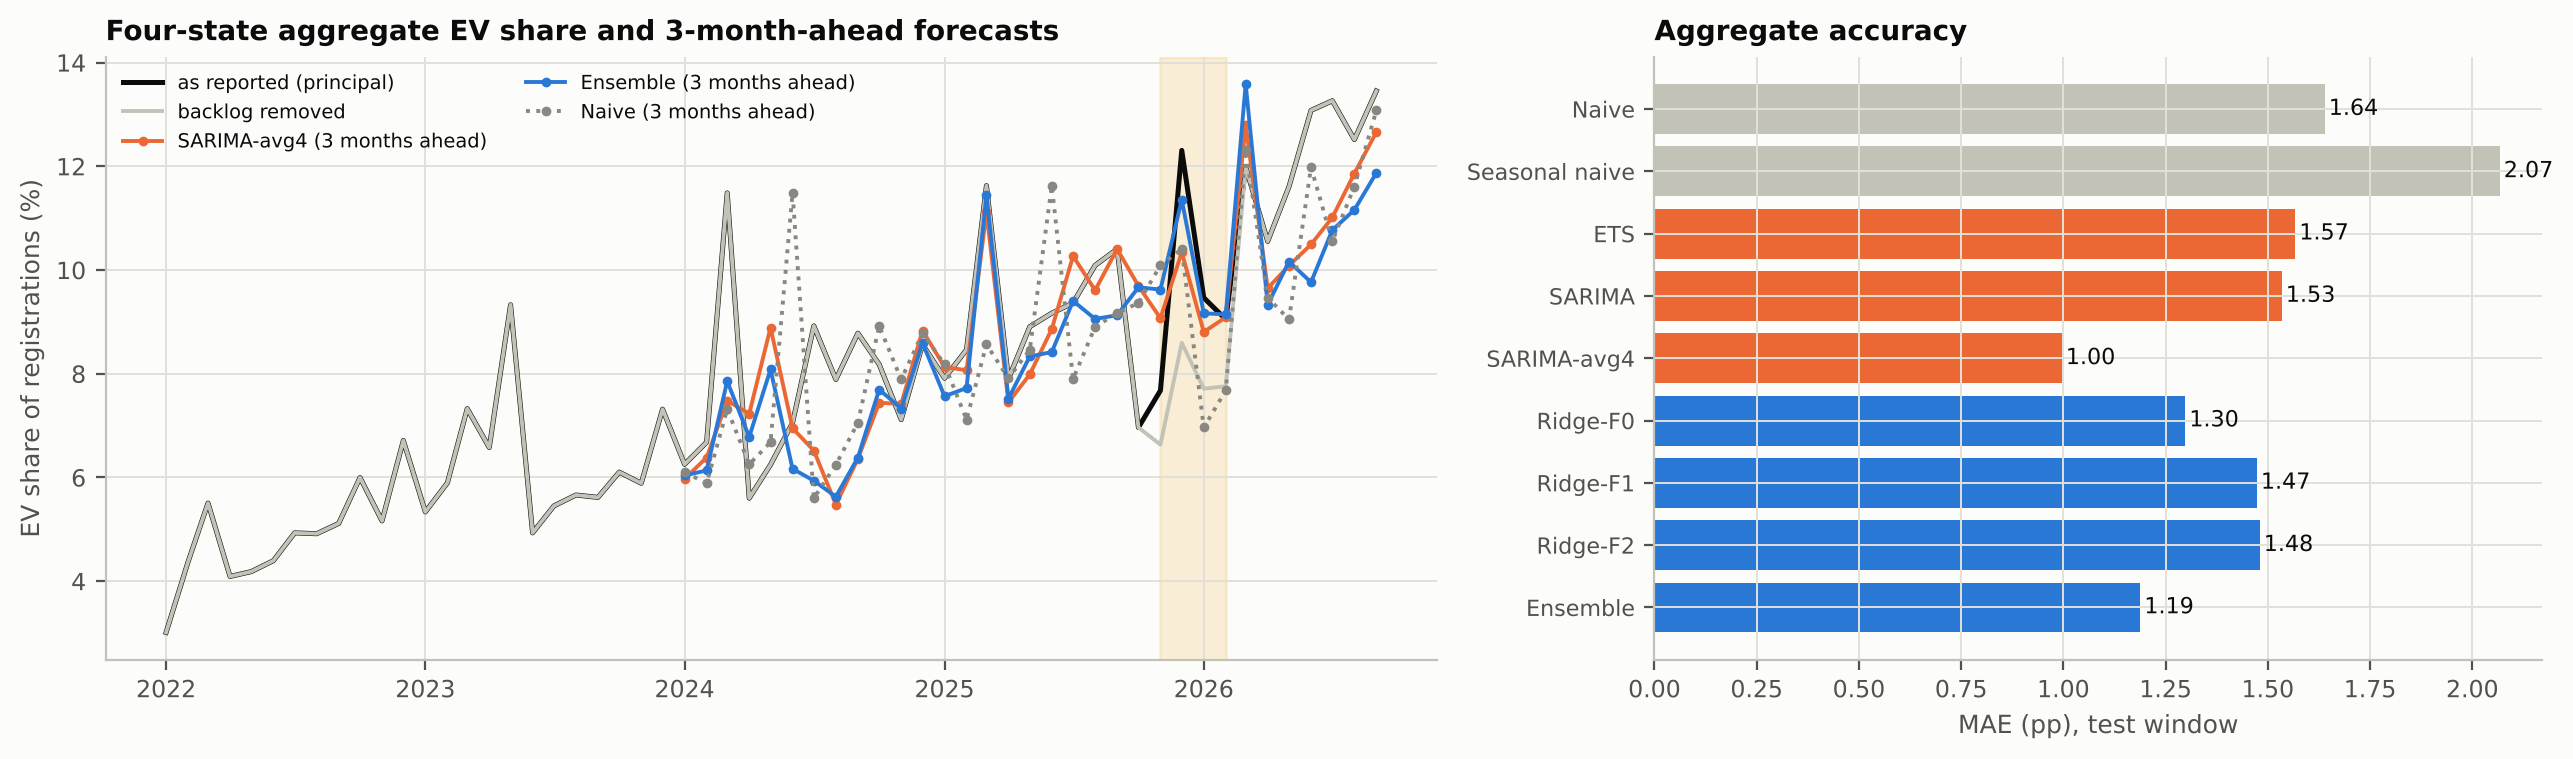

  [figure] outputs/figures/fig22_aggregate_forecast.png

PART C - aggregate drivers (same-month associations, n = 56 months)
VIF of aggregate drivers (standardised): {'aqi_mean': 7.0, 'no2_mean': 2.0, 'so2_mean': 1.9, 'petrol_price': 1.9, 'charging_stations': 5.7, 'nsdp_per_capita': 6.0, 'mean_temp_c': 5.3, 'precipitation_mm': 2.9}
  [table]  outputs/tables/09_aggregate_vif.csv
Correlation of each driver with calendar time (aggregate): {'aqi_mean': -0.17, 'no2_mean': -0.3, 'so2_mean': 0.37, 'petrol_price': -0.23, 'charging_stations': 0.85, 'nsdp_per_capita': 0.97, 'mean_temp_c': 0.07, 'precipitation_mm': 0.1}



Same-month explanatory models on the aggregate (hold-out = test window, flagged months excluded):
             feature set        model  cv_MAE (log)  holdout_MAE_pp  holdout_R2
       trend + calendar        Ridge         0.139           1.170       0.433
     drivers + calendar        Ridge         0.140           2.018      -0.863
reference: mean of 2024     constant           NaN           2.603      -1.738
     drivers + calendar RandomForest         0.196           3.135      -3.000
          calendar only        Ridge         0.254           4.159      -4.749
          calendar only RandomForest         0.252           4.183      -4.851
  [table]  outputs/tables/09_aggregate_explanatory_models.csv

SHAP mean |value| (random forest, all months):
 charging_stations    0.1634
nsdp_per_capita      0.0700
so2_mean             0.0271
petrol_price         0.0206
aqi_mean             0.0118
no2_mean             0.0102
precipitation_mm     0.0061
mean_temp_c          0.0059
month_cos   

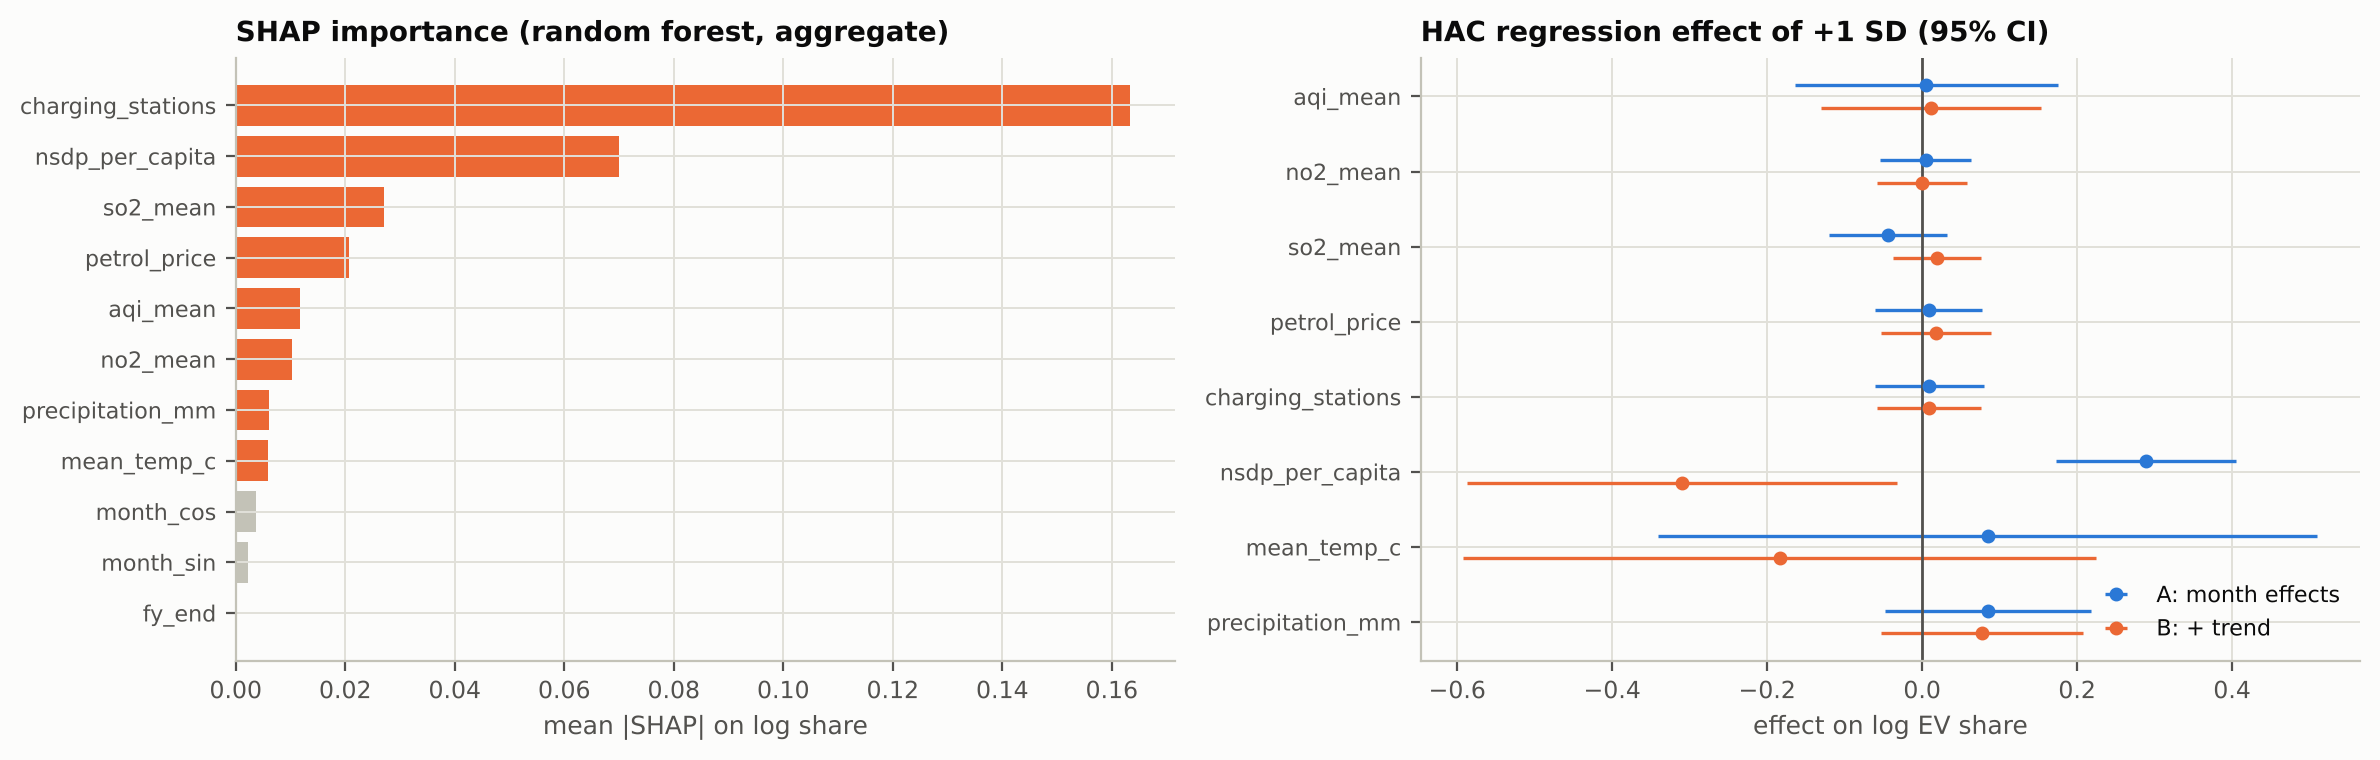

  [figure] outputs/figures/fig23_aggregate_drivers.png


PosixPath('/home/claude/ev_adoption_project/outputs/figures/fig23_aggregate_drivers.png')

In [13]:
from common import *
from forecasting_utils import *
from vintage import backlog_adjusted_rate

import shap
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = load_data(complete=False)        # registrations through Sep-2026 (forecast part); Part C trims to complete-covariate months
vp = pd.read_csv(BASE_DIR / "data" / "ev_panel_vintage.csv", parse_dates=["date"])
vp = vp[vp.date <= DATA_CUTOFF]
protocol = json.loads((TAB_DIR / "02_selected_features_and_protocol.json").read_text())
SEL = protocol["selected_drivers"]
EXOG_F1 = [c for c in SEL if c not in ("charging_stations", "nsdp_per_capita")]
EXOG_F2 = EXOG_F1 + [c for c in ("charging_stations", "nsdp_per_capita") if c in SEL]
FSETS = {"F0": [], "F1": EXOG_F1, "F2": EXOG_F2}
HORIZONS = [1, 2, 3, 4, 5, 6]
dates = sorted(df.date.unique()); N_T = len(dates)
T_TRAIN_END = int(df.loc[df.date == TRAIN_END, "t"].iloc[0]); EVAL_T = list(range(24, N_T))

# ----------------------------------------------------------------------------- build the aggregate series
adj, base3w = backlog_adjusted_rate(df)
g = df.groupby("date")[["ev_count", "vehicle_total"]].sum()
y_rep = (g.ev_count / g.vehicle_total).to_numpy()
wb = df[df.state == ANOMALY_STATE].sort_values("date").set_index("date")
excess = ((wb.three_wheeler - base3w).clip(lower=0) * wb.anomaly_flag)
ev_adj = (g.ev_count - np.minimum(excess, wb.ev_count)).clip(lower=1); tot_adj = (g.vehicle_total - excess).clip(lower=1)
y_adj = (ev_adj / tot_adj).to_numpy()
FLAG = (df[df.state == ANOMALY_STATE].sort_values("date").anomaly_flag.to_numpy())
SERIES = {"as_reported": y_rep, "backlog_removed": y_adj}
PRIN = "as_reported"
print(f"Aggregate series: {N_T} months | flagged months {int(FLAG.sum())} | WB baseline three-wheelers {base3w:.0f}")
print("Aggregate EV share % (as reported vs backlog removed), flagged window:")
print(pd.DataFrame({"as_reported_%": 100 * y_rep, "backlog_removed_%": 100 * y_adj}, index=pd.to_datetime(dates))[FLAG == 1].round(2).to_string())


def agg_exog(frame: pd.DataFrame, cols: list) -> pd.DataFrame:
    gg = frame.sort_values(["date", "state"]).groupby("date")
    out = pd.DataFrame({c: (gg[c].sum(min_count=4) if c == "charging_stations" else gg[c].mean()) for c in cols})
    return out.reset_index(drop=True)


EX_V = agg_exog(vp, EXOG_F2)                                     # release-aligned (as known at the origin)
EX_S = agg_exog(df, EXOG_F2)                                     # same-month (retrospective layer)
FEATS = {fs: ml_feature_names(ex) for fs, ex in FSETS.items()}

# ----------------------------------------------------------------------------- Part A: forecasting
def run_series(name: str, y: np.ndarray):
    Yd = {"ALL": y}
    rows = {fs: {h: make_rows(Yd, {"ALL": EX_V}, ex, h, range(14, N_T), states=["ALL"]) for h in HORIZONS} for fs, ex in FSETS.items()}
    best = {}
    for fs in FSETS:                                             # tiny data (<40 rows): Ridge alpha by expanding-window validation
        for h in HORIZONS:
            tr = rows[fs][h].query("t <= @T_TRAIN_END").reset_index(drop=True)
            folds = [(tr.index[tr.t < a].to_numpy(), tr.index[(tr.t >= a) & (tr.t <= b)].to_numpy()) for a, b in [(24, 29), (30, 35)]]
            folds = [f for f in folds if len(f[0]) >= 5 and len(f[1]) >= 1]
            est = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler(), Ridge())
            gs = GridSearchCV(est, {"ridge__alpha": [1, 3, 10, 30, 100, 300]}, cv=folds, scoring="neg_mean_absolute_error", error_score=np.nan).fit(tr[FEATS[fs]], tr["target"])
            best[(fs, h)] = gs.best_estimator_
    # SARIMA spec on validation origins
    spec_scores = {}
    for spec in SARIMA_SPECS:
        errs = []
        for o in range(23, 30):
            f = fit_forecast_sarima(y[:o + 1], 6, spec); tgt = np.arange(o + 1, o + 7); ok = tgt <= T_TRAIN_END
            errs += list(np.abs(f[ok] - y[tgt[ok]]))
        spec_scores[spec] = np.mean(errs)
    spec = min(spec_scores, key=spec_scores.get)
    recs = []

    def add(m, o, h, p):
        t = o + h; recs.append({"series": name, "model": m, "o": o, "t": t, "h": h, "date": pd.Timestamp(dates[t]), "y_true": y[t], "y_pred": float(p), "flag": int(FLAG[t])})

    origins = sorted({t - h for t in EVAL_T for h in HORIZONS if t - h >= 17})
    for o in origins:
        hist = y[:o + 1]; ets = fit_forecast_ets(hist, 6); sar = fit_forecast_sarima(hist, 6, spec)
        avg = np.exp(np.mean([np.log(fit_forecast_sarima(hist, 6, sp)) for sp in SARIMA_SPECS], axis=0))
        b = base_level(y, o); b_ly = np.mean(y[o - 14:o - 11])
        for h in HORIZONS:
            t = o + h
            if t not in EVAL_T: continue
            add("Naive (last value)", o, h, y[o]); add("Moving average (3m)", o, h, b); add("Seasonal naive", o, h, y[t - 12])
            add("Seasonal naive + YoY growth", o, h, y[t - 12] * b / b_ly); add("ETS", o, h, ets[h - 1]); add("SARIMA", o, h, sar[h - 1])
            add("SARIMA-avg4 (all specs averaged)", o, h, avg[h - 1])
    for fs in FSETS:
        for h in HORIZONS:
            rh = rows[fs][h]
            for o in [t - h for t in EVAL_T]:
                tr, te = rh[rh.t <= o], rh[rh.o == o]
                if len(tr) < 8 or te.empty: continue
                m = clone(best[(fs, h)]).fit(tr[FEATS[fs]], tr["target"])
                add(f"Ridge-{fs}", o, h, te["base"].iloc[0] * np.exp(m.predict(te[FEATS[fs]])[0]))
    ev = pd.DataFrame(recs)
    ens = ev[ev.model.isin(["SARIMA-avg4 (all specs averaged)", "ETS", "Ridge-F0"])].groupby(["series", "o", "t", "h", "date", "y_true", "flag"], as_index=False).y_pred.mean()
    ens["model"] = "Ensemble (SARIMA-avg4 + ETS + Ridge-F0)"
    ev = pd.concat([ev, ens], ignore_index=True); ev["abs_err"] = (ev.y_true - ev.y_pred).abs()
    ev["period"] = np.where(ev.t <= T_TRAIN_END, "validation", "test")
    return ev, spec


all_ev, specs = [], {}
for name, y in SERIES.items():
    e_, sp_ = run_series(name, y); all_ev.append(e_); specs[name] = sp_
    print(f"series {name}: SARIMA spec chosen on validation = {sp_}", flush=True)
EV = pd.concat(all_ev, ignore_index=True)
save_table(EV, "09_aggregate_rolling_predictions", index=False)

naive_mae = {}
tabs = {}
for name in SERIES:
    t_ = EV[(EV.series == name) & (EV.period == "test")]
    t_ = t_[t_.flag == 0] if name == "as_reported" else t_             # backlog_removed: every test month is scored
    mase_scale = np.mean(np.abs(np.diff(SERIES[name][:T_TRAIN_END + 1])))
    rows = []
    for m, d in t_.groupby("model"):
        y, p = d.y_true.to_numpy(), d.y_pred.to_numpy()
        rows.append({"model": m, "MAE_pp": 100 * np.mean(np.abs(y - p)), "RMSE_pp": 100 * np.sqrt(np.mean((y - p) ** 2)), "sMAPE_%": 100 * smape(y, p),
                     "MAPE_%": 100 * np.mean(np.abs(y - p) / y), "MASE": np.mean(np.abs(y - p)) / mase_scale, "R2": r2(y, p), "n": len(d)})
    tab = pd.DataFrame(rows).set_index("model").sort_values("MAE_pp")
    tab["skill_vs_naive_%"] = 100 * (1 - tab.MAE_pp / tab.loc["Naive (last value)", "MAE_pp"])
    tabs[name] = tab.round(3)
    print(f"\n=== TEST window, aggregate series = {name}  (targets {TEST_START:%b-%Y}..{DATA_CUTOFF:%b-%Y}, horizons 1-6) ===")
    print(tabs[name].to_string())
    save_table(tabs[name], f"09_aggregate_metrics_{name}")
    r2h = t_[t_.model == tab.index[0]].groupby("h").apply(lambda d: r2(d.y_true, d.y_pred)).round(3)
    print(f"R2 by horizon, best model ({tab.index[0]}):", r2h.to_dict())
    save_table(t_.groupby(["model", "h"]).abs_err.mean().mul(100).unstack("h").loc[tab.index].round(3), f"09_aggregate_mae_by_horizon_{name}")


def boot_diff(a, b, frame, n=4000, seed=SEED):
    A = frame[frame.model == a].set_index(["h", "t"]).abs_err; B = frame[frame.model == b].set_index(["h", "t"]).abs_err
    d = (A - B).dropna().rename("d").reset_index(); sums = d.groupby("t").d.sum().to_numpy(); cnt = d.groupby("t").d.size().to_numpy()
    rng = np.random.default_rng(seed); k = len(sums); picks = rng.integers(0, k, size=(n, k)); means = sums[picks].sum(1) / cnt[picks].sum(1)
    lo, hi = np.percentile(means, [5, 95]); return 100 * d.d.mean(), 100 * lo, 100 * hi


main = EV[(EV.series == PRIN) & (EV.period == "test") & (EV.flag == 0)]
rows = []
for m in tabs[PRIN].index:
    if m == "Naive (last value)": continue
    dm, lo, hi = boot_diff(m, "Naive (last value)", main)
    rows.append({"model": m, "MAE diff vs naive (pp)": dm, "90% CI low": lo, "90% CI high": hi, "significantly_better": hi < 0})
sig = pd.DataFrame(rows).set_index("model").round(3); print("\nVs naive, aggregate (as_reported, flagged months excluded):\n", sig.to_string()); save_table(sig, "09_aggregate_bootstrap_vs_naive")
cov = []
for fs in ("F1", "F2"):
    dm, lo, hi = boot_diff(f"Ridge-{fs}", "Ridge-F0", main); cov.append({"comparison": f"Ridge-{fs} minus Ridge-F0", "MAE diff (pp)": dm, "90% CI low": lo, "90% CI high": hi})
cov = pd.DataFrame(cov).round(3); print("\nDo release-aligned covariates help the aggregate forecast? (negative = yes)\n", cov.to_string(index=False)); save_table(cov, "09_aggregate_covariate_value", index=False)

# ----------------------------------------------------------------------------- Part B: top-down vs bottom-up
st = pd.read_csv(TAB_DIR / "04_rolling_origin_predictions.csv", parse_dates=["date"])
st = st[(st.model == "SARIMA-avg4 (all specs averaged)") & (st.period == "test")]
vol = df.pivot(index="t", columns="state", values="vehicle_total")[STATES]
rows = []
for (o, t, h), d in st.groupby(["o", "t", "h"]):
    w = vol.loc[max(0, o - 11):o].sum(); w = w / w.sum()
    rows.append({"o": o, "t": t, "h": h, "bottom_up": float((d.set_index("state").y_pred.reindex(STATES) * w).sum())})
bu = pd.DataFrame(rows)
td = EV[(EV.series == "as_reported") & (EV.model == "SARIMA-avg4 (all specs averaged)") & (EV.period == "test")][["o", "t", "h", "y_true", "y_pred", "flag"]].rename(columns={"y_pred": "top_down"})
cmp_ = td.merge(bu, on=["o", "t", "h"]); cmp_ = cmp_[cmp_.flag == 0]
bu_tab = pd.DataFrame({"top-down (aggregate SARIMA-avg4)": [100 * (cmp_.y_true - cmp_.top_down).abs().mean(), r2(cmp_.y_true, cmp_.top_down)],
                       "bottom-up (state SARIMA-avg4, volume-weighted)": [100 * (cmp_.y_true - cmp_.bottom_up).abs().mean(), r2(cmp_.y_true, cmp_.bottom_up)]}, index=["MAE_pp", "R2"]).round(3)
print("\nTop-down vs bottom-up (as-reported aggregate, flagged months excluded):\n", bu_tab.to_string()); save_table(bu_tab, "09_top_down_vs_bottom_up")

# ----------------------------------------------------------------------------- figures (forecast part)
set_style()
dts = pd.to_datetime(dates)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
ax.plot(dts, 100 * y_rep, color=INK, lw=1.8, label="as reported (principal)"); ax.plot(dts, 100 * y_adj, color="#c3c2b7", lw=1.4, label="backlog removed")
ax.axvspan(dts[FLAG == 1].min(), dts[FLAG == 1].max(), color="#eda100", alpha=.15)
for m, c in [("SARIMA-avg4 (all specs averaged)", "#eb6834"), ("Ensemble (SARIMA-avg4 + ETS + Ridge-F0)", "#2a78d6"), ("Naive (last value)", "#898781")]:
    d = EV[(EV.series == PRIN) & (EV.model == m) & (EV.h == 3)].sort_values("t")
    ax.plot(d.date, 100 * d.y_pred, color=c, ls=":" if m.startswith("Naive") else "-", marker="o", ms=2.5, lw=1.4, label=f"{m.split(' (')[0]} (3 months ahead)")
ax.set_ylabel("EV share of registrations (%)"); ax.set_title("Four-state aggregate EV share and 3-month-ahead forecasts", fontsize=10); ax.legend(fontsize=7, ncol=2)
ax = axes[1]; bt = tabs[PRIN]; show = ["Naive (last value)", "Seasonal naive", "ETS", "SARIMA", "SARIMA-avg4 (all specs averaged)", "Ridge-F0", "Ridge-F1", "Ridge-F2", "Ensemble (SARIMA-avg4 + ETS + Ridge-F0)"]
vals = bt.loc[show, "MAE_pp"]; ax.barh(range(len(show)), vals, color=["#c3c2b7" if "Naive" in s or "Seasonal" in s else ("#2a78d6" if "Ridge" in s else "#eb6834") for s in show])
ax.set_yticks(range(len(show)), [s.split(" (")[0] for s in show], fontsize=8); ax.invert_yaxis()
for i, v in enumerate(vals): ax.text(v + .01, i, f"{v:.2f}", va="center", fontsize=8)
ax.set_xlabel("MAE (pp), test window"); ax.set_title("Aggregate accuracy", fontsize=10)
fig.tight_layout(); save_fig(fig, "fig22_aggregate_forecast")

# ----------------------------------------------------------------------------- Part C: explanation on the aggregate
N_C = int((pd.to_datetime(dates) <= COVARIATE_CUTOFF).sum())      # months with every covariate observed (through Aug-2026)
print("\n" + "=" * 90 + "\nPART C - aggregate drivers (same-month associations, n = %d months)\n" % N_C + "=" * 90)
D = EX_S.iloc[:N_C][SEL].copy(); D["month"] = pd.to_datetime(dates[:N_C]).month; D["t"] = np.arange(N_C)
D["month_sin"] = np.sin(2 * np.pi * D.month / 12); D["month_cos"] = np.cos(2 * np.pi * D.month / 12); D["fy_end"] = (D.month == 3).astype(int)
D["y"] = y_adj[:N_C]; D["log_y"] = np.log(y_adj[:N_C])
CAL = ["month_sin", "month_cos", "fy_end"]

from statsmodels.stats.outliers_influence import variance_inflation_factor as _vif
X0 = (D[SEL] - D[SEL].mean()) / D[SEL].std()
vif = pd.Series([_vif(sm.add_constant(X0).values, i + 1) for i in range(len(SEL))], index=SEL).round(1)
print("VIF of aggregate drivers (standardised):", vif.to_dict()); save_table(vif.to_frame("VIF"), "09_aggregate_vif")
print("Correlation of each driver with calendar time (aggregate):", D[SEL + ["t"]].corr()["t"].drop("t").round(2).to_dict())

# --- ML explanatory models with expanding-window validation, hold-out = test window
tr_idx, te_idx = D.index[D.t <= T_TRAIN_END], D.index[D.t > T_TRAIN_END]
te_ok = [i for i in te_idx if FLAG[i] == 0]
folds = [(D.index[D.t < a].to_numpy(), D.index[(D.t >= a) & (D.t <= b)].to_numpy()) for a, b in [(18, 23), (24, 29), (30, 35)]]
folds = [(a, b) for a, b in folds if len(a) >= 8]
FSETS_X = {"calendar only": CAL, "trend + calendar": CAL + ["t"], "drivers + calendar": SEL + CAL}
mods = {"Ridge": (make_pipeline(StandardScaler(), Ridge()), {"ridge__alpha": [0.1, 1, 3, 10, 30, 100]}),
        "RandomForest": (RandomForestRegressor(random_state=SEED, n_jobs=1), {"n_estimators": [150], "max_depth": [2, 3, 4], "min_samples_leaf": [2, 4, 6], "max_features": [0.5, 1.0]})}
res, fitted = [], {}
for fsn, cols in FSETS_X.items():
    for mn, (est, grid) in mods.items():
        if fsn == "trend + calendar" and mn == "RandomForest": continue          # trees cannot extrapolate a trend
        gs = GridSearchCV(est, grid, cv=folds, scoring="neg_mean_absolute_error").fit(D.loc[tr_idx, cols], D.loc[tr_idx, "log_y"])
        pred = np.exp(gs.predict(D.loc[te_ok, cols])); y_te = D.loc[te_ok, "y"].to_numpy()
        res.append({"feature set": fsn, "model": mn, "cv_MAE (log)": -gs.best_score_, "holdout_MAE_pp": 100 * np.mean(np.abs(y_te - pred)), "holdout_R2": r2(y_te, pred)})
        fitted[(fsn, mn)] = gs.best_estimator_
ref = np.full(len(te_ok), D.loc[tr_idx, "y"].iloc[-12:].mean())
res.append({"feature set": "reference: mean of 2024", "model": "constant", "cv_MAE (log)": np.nan, "holdout_MAE_pp": 100 * np.mean(np.abs(D.loc[te_ok, "y"].to_numpy() - ref)), "holdout_R2": r2(D.loc[te_ok, "y"].to_numpy(), ref)})
res = pd.DataFrame(res).round(3).sort_values("holdout_MAE_pp"); print("\nSame-month explanatory models on the aggregate (hold-out = test window, flagged months excluded):\n", res.to_string(index=False))
save_table(res, "09_aggregate_explanatory_models", index=False)

# --- SHAP on the best driver model fitted to ALL months (descriptive)
best_drv = res[res["feature set"] == "drivers + calendar"].sort_values("holdout_MAE_pp").iloc[0]
rf = clone(fitted[("drivers + calendar", "RandomForest")]).fit(D[SEL + CAL], D["log_y"])
sv = shap.TreeExplainer(rf).shap_values(D[SEL + CAL])
shap_imp = pd.Series(np.abs(sv).mean(0), index=SEL + CAL).sort_values(ascending=False)
shap_dir = pd.Series({c: np.sign(np.corrcoef(D[c], sv[:, (SEL + CAL).index(c)])[0, 1]) if np.std(sv[:, (SEL + CAL).index(c)]) > 0 else 0 for c in SEL})
print("\nSHAP mean |value| (random forest, all months):\n", shap_imp.round(4).to_string())

# --- HAC regressions (spec A: month dummies; spec B: + linear trend; spec C: first differences)
Z = D.copy(); Z[SEL] = (Z[SEL] - Z[SEL].mean()) / Z[SEL].std()
fa = "log_y ~ " + " + ".join(SEL) + " + C(month)"; fb = fa + " + t"
ma = smf.ols(fa, Z).fit(cov_type="HAC", cov_kwds={"maxlags": 3}); mb = smf.ols(fb, Z).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
dZ = Z[["log_y"] + SEL].diff().dropna(); dZ["month"] = Z.month.iloc[1:].values
mc = smf.ols("log_y ~ " + " + ".join(SEL), dZ).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
tri = pd.DataFrame({"coef_A (month FE)": ma.params[SEL], "p_A": ma.pvalues[SEL], "coef_B (+trend)": mb.params[SEL], "p_B": mb.pvalues[SEL],
                    "coef_C (differences)": mc.params[SEL], "p_C": mc.pvalues[SEL], "SHAP importance": shap_imp[SEL], "SHAP direction": shap_dir})
tri["robust"] = ((np.sign(tri["coef_A (month FE)"]) == np.sign(tri["coef_B (+trend)"])) & (np.sign(tri["coef_A (month FE)"]) == tri["SHAP direction"]) & (tri.p_A < .10) & (tri.p_B < .10))
print("\nDriver triangulation, aggregate (coefficients = effect on log share of +1 SD):\n", tri.round(3).to_string())
print(f"\nRobust drivers (same sign in SHAP, A and B; p<0.10 in A and B): {list(tri.index[tri.robust]) or 'none'}")
print(f"Spec A R2 = {ma.rsquared:.2f}, spec B R2 = {mb.rsquared:.2f}, first-difference R2 = {mc.rsquared:.2f}")
save_table(tri.round(4), "09_aggregate_driver_triangulation")
save_json({"robust_drivers": list(tri.index[tri.robust]), "n_months": int(N_C), "spec_A_R2": float(ma.rsquared), "spec_B_R2": float(mb.rsquared), "diff_R2": float(mc.rsquared),
           "best_forecast_model_principal_series": tabs[PRIN].index[0], "best_forecast_MAE_pp": float(tabs[PRIN].MAE_pp.iloc[0]), "best_forecast_R2": float(tabs[PRIN].R2.iloc[0]),
           "sarima_spec_chosen": specs}, "09_summary")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
ax = axes[0]; imp = shap_imp.sort_values(); ax.barh(range(len(imp)), imp.values, color=["#eb6834" if i in SEL else "#c3c2b7" for i in imp.index])
ax.set_yticks(range(len(imp)), imp.index, fontsize=8); ax.set_title("SHAP importance (random forest, aggregate)", fontsize=10); ax.set_xlabel("mean |SHAP| on log share")
ax = axes[1]
for k, (mdl, col, off) in enumerate([(ma, "#2a78d6", -.15), (mb, "#eb6834", .15)]):
    ci = mdl.conf_int().loc[SEL]; ax.errorbar(mdl.params[SEL], np.arange(len(SEL)) + off, xerr=[mdl.params[SEL] - ci[0], ci[1] - mdl.params[SEL]], fmt="o", color=col, ms=4, lw=1.2, label=["A: month effects", "B: + trend"][k])
ax.axvline(0, color=INK2, lw=1); ax.set_yticks(range(len(SEL)), SEL, fontsize=8); ax.invert_yaxis(); ax.legend(fontsize=8, loc="lower right")
ax.set_title("HAC regression effect of +1 SD (95% CI)", fontsize=10); ax.set_xlabel("effect on log EV share")
fig.tight_layout(); save_fig(fig, "fig23_aggregate_drivers")


## `11_master_results_table.py`
11_master_results_table.py -- ONE master table of every reported accuracy number, with its exact sample
=========================================================================================================
Rule: results from different samples must never be mixed into one headline comparison.  Every row below states
the evaluation window (first/last TARGET month), the number of target months and state-month forecasts, the horizons,
whether the flagged West Bengal months are excluded, the series level (state-level vs pooled four-state series), the model
and its status (primary pre-declared / exploratory / benchmark), and the feature set.
Run from the project root after stages 04, 09 and 10:  python 11_master_results_table.py
Outputs: outputs/tables/11_master_results.csv, docs/MASTER_RESULTS_TABLE.md

In [14]:
from common import *

NAIVE = "Naive (last value)"
PRIMARY = "Ensemble-F0 top-3 (validation-selected)"
EXPLORATORY = ["Ensemble-F0 pool (equal weights)", "SARIMA-avg4 (all specs averaged)"]


def status(m):
    if m == PRIMARY: return "PRIMARY (pre-declared)"
    if m in EXPLORATORY: return "exploratory (added after seeing test results)"
    if m.startswith(("Naive", "Moving", "Seasonal")): return "benchmark"
    return "comparison model"


def fset(m):
    for fs in ("F0", "F1", "F2"):
        if m.endswith(f"-{fs}"): return fs
    return "F0 (history only)" if not m.startswith("Ensemble-All") else "F0"


def score(g, naive_mae):
    y, p = g.y_true.to_numpy(), g.y_pred.to_numpy()
    return {"MAE_pp": 100 * np.mean(np.abs(y - p)), "RMSE_pp": 100 * np.sqrt(np.mean((y - p) ** 2)), "sMAPE_%": 100 * smape(y, p),
            "R2_pooled": 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2), "skill_vs_naive_%": 100 * (1 - np.mean(np.abs(y - p)) / naive_mae)}


rows = []


def add_eval(eid, label, g, level, wb_excl, horizons, source, model_filter=None):
    g = g.copy()
    nm = g[g.model == NAIVE].eval("abs_err").mean() if (g.model == NAIVE).any() else np.nan
    n_t = g.date.nunique()
    for m, gm in g.groupby("model"):
        if model_filter is not None and m not in model_filter: continue
        rows.append({"eval_id": eid, "evaluation": label, "first_target_month": f"{gm.date.min():%Y-%m}", "last_target_month": f"{gm.date.max():%Y-%m}",
                     "n_target_months": n_t, "n_forecasts_per_model": len(gm), "horizons": horizons, "series_level": level,
                     "WB_flagged_months_excluded": wb_excl, "model": m, "model_status": status(m), "feature_set": fset(m), **score(gm, nm), "source_table": source})


ev = pd.read_csv(TAB_DIR / "04_rolling_origin_predictions.csv", parse_dates=["date"])
ev = ev[~ev.model.str.contains(r"\[backlog")]
test = ev[(ev.period == "test")]
KEEP = [PRIMARY] + EXPLORATORY + ["SARIMA", "ETS", "PSD (pooled seasonal + damped trend)", "Ridge-F0", "LightGBM-F0", "XGBoost-F0", "Ridge-F2", "LightGBM-F2", "XGBoost-F2",
                                  "Moving average (3m)", "Seasonal naive + YoY growth", NAIVE]
clean = test[test.flag == 0]
add_eval("E1", "State-level rolling origin, all test targets", clean, "state-level (4 states)", "yes", "1-6", "04_rolling_origin_predictions.csv", KEEP)
add_eval("E1a", "State-level rolling origin, 2025 targets only", clean[clean.date < "2026-01-01"], "state-level (4 states)", "yes", "1-6", "04_rolling_origin_predictions.csv", KEEP)
add_eval("E1b", "State-level rolling origin, 2026 targets only", clean[clean.date >= "2026-01-01"], "state-level (4 states)", "yes", "1-6", "04_rolling_origin_predictions.csv", KEEP)
add_eval("E1c", "State-level rolling origin, flagged WB months INCLUDED (sensitivity)", test, "state-level (4 states)", "no", "1-6", "04_rolling_origin_predictions.csv", KEEP)

bt = pd.read_csv(TAB_DIR / "10_backtest_forecasts.csv", parse_dates=["date"])
bt = bt[bt.policy == "as_reported"]
add_eval("E2", "Fixed-origin backtest: train to Mar-2026, forecast Apr-Sep 2026 (single origin)", bt, "state-level (4 states)", "yes (none in window)", "1-6", "10_backtest_forecasts.csv",
         [PRIMARY] + EXPLORATORY + ["SARIMA", "ETS", "Ridge-F0", "LightGBM-F0", "XGBoost-F0", "Ridge-F2", "LightGBM-F2", "XGBoost-F2", NAIVE])

ag = pd.read_csv(TAB_DIR / "09_aggregate_metrics_as_reported.csv")
agp = pd.read_csv(TAB_DIR / "09_aggregate_rolling_predictions.csv", parse_dates=["date"]) if (TAB_DIR / "09_aggregate_rolling_predictions.csv").exists() else None
for _, r in ag.iterrows():
    rows.append({"eval_id": "E3", "evaluation": "Pooled four-state series, rolling origin (stage 09)", "first_target_month": "2025-01", "last_target_month": "2026-09",
                 "n_target_months": int(r.n / 6), "n_forecasts_per_model": int(r.n), "horizons": "1-6", "series_level": "pooled four-state series (NOT India)",
                 "WB_flagged_months_excluded": "yes", "model": r.model, "model_status": "exploratory (added after seeing test results)" if "avg4" in r.model or r.model.startswith("Ensemble") else status(r.model),
                 "feature_set": fset(r.model), "MAE_pp": r.MAE_pp, "RMSE_pp": r.RMSE_pp, "sMAPE_%": r["sMAPE_%"], "R2_pooled": r.R2, "skill_vs_naive_%": r["skill_vs_naive_%"], "source_table": "09_aggregate_metrics_as_reported.csv"})

M = pd.DataFrame(rows)
M = M.sort_values(["eval_id", "MAE_pp"]).reset_index(drop=True)
save_table(M.round(4), "11_master_results", index=False)

# markdown version for the docs
md = ["# Master results table (generated by `11_master_results_table.py`)", "",
      "Every number reported in the README, the scorecard and the paper comes from this table. **Rows from different evaluation IDs use different samples and must not be compared with each other.**", "",
      "| Eval | Targets (first..last) | Months | Forecasts / model | Horizons | Level | WB flagged excl. | n windows |", "|---|---|---|---|---|---|---|---|"]
hdr = M.drop_duplicates("eval_id")
for _, r in hdr.iterrows():
    md.append(f"| {r.eval_id}: {r.evaluation} | {r.first_target_month}..{r.last_target_month} | {r.n_target_months} | {r.n_forecasts_per_model} | {r.horizons} | {r.series_level} | {r.WB_flagged_months_excluded} | |".replace(" |  |", " |"))
for eid, g in M.groupby("eval_id", sort=True):
    md += ["", f"## {eid}: {g.evaluation.iloc[0]}", "", "| Model | Status | Feature set | MAE (pp) | RMSE (pp) | sMAPE (%) | R2 (pooled) | Skill vs naive (%) |", "|---|---|---|---|---|---|---|---|"]
    for _, r in g.iterrows():
        f = lambda v, d=2: "" if pd.isna(v) else f"{v:.{d}f}"
        md.append(f"| {r.model} | {r.model_status} | {r.feature_set} | {f(r.MAE_pp)} | {f(r.RMSE_pp)} | {f(r['sMAPE_%'], 1)} | {f(r.R2_pooled)} | {f(r['skill_vs_naive_%'], 1)} |")
(BASE_DIR / "docs" / "MASTER_RESULTS_TABLE.md").write_text("\n".join(md) + "\n")
print(M[M.model.isin([PRIMARY, EXPLORATORY[0], NAIVE, "SARIMA"])][["eval_id", "model", "n_target_months", "n_forecasts_per_model", "MAE_pp", "R2_pooled", "skill_vs_naive_%"]].round(2).to_string(index=False))
print("wrote docs/MASTER_RESULTS_TABLE.md")


  [table]  outputs/tables/11_master_results.csv
eval_id                                   model  n_target_months  n_forecasts_per_model  MAE_pp  R2_pooled  skill_vs_naive_%
     E1        Ensemble-F0 pool (equal weights)               21                    480    1.90       0.49             18.79
     E1                                  SARIMA               21                    480    1.93       0.48             17.54
     E1 Ensemble-F0 top-3 (validation-selected)               21                    480    1.94       0.47             17.05
     E1                      Naive (last value)               21                    480    2.34       0.21             -0.00
    E1a        Ensemble-F0 pool (equal weights)               12                    276    1.42       0.75             27.00
    E1a Ensemble-F0 top-3 (validation-selected)               12                    276    1.53       0.71             21.34
    E1a                                  SARIMA               12             

## `12_report_figures.py`
12_report_figures.py -- print-quality PDF figures for the IEEE/Overleaf report (writes report/figs/*.pdf)
Run from the project root after stages 00a-11:  python 12_report_figures.py

In [15]:
from common import *
import matplotlib as mpl

OUT = BASE_DIR / "report" / "figs"; OUT.mkdir(parents=True, exist_ok=True)
mpl.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white", "font.size": 7.5, "axes.titlesize": 8.5,
                     "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 7.5, "xtick.labelsize": 6.8, "ytick.labelsize": 6.8,
                     "legend.fontsize": 6.8, "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.5, "axes.spines.top": False, "axes.spines.right": False,
                     "lines.linewidth": 1.3, "font.family": "DejaVu Sans"})
COL = {"Delhi": "#1f4e9c", "Maharashtra": "#d6641a", "Tamil Nadu": "#2e8b57", "West Bengal": "#8b3a8b"}
PRIMARY = "Ensemble-F0 top-3 (validation-selected)"
df = load_data(complete=False)

# ---- Fig 1: trajectories and seasonality
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.05), gridspec_kw={"width_ratios": [1.75, 1]})
for s in STATES:
    g = df[df.state == s]; ax[0].plot(g.date, 100 * g[TARGET], color=COL[s], label=s)
ax[0].axvspan(ANOMALY_START, ANOMALY_END + pd.offsets.MonthEnd(0), color="#f2c14e", alpha=.35, lw=0)
ax[0].axvspan(TEST_START, DATA_CUTOFF + pd.offsets.MonthEnd(0), color="#888888", alpha=.10, lw=0)
ax[0].text(TEST_START, 0.8, "test window", fontsize=6.2)
ax[0].set_ylabel("EV share of new registrations (%)"); ax[0].set_title("(a) Monthly EV adoption rate"); ax[0].legend(ncol=4, loc="upper left", frameon=False, fontsize=6.3)
ax[0].set_ylim(0, 30)
si = pd.read_csv(TAB_DIR / "02_pooled_seasonal_index.csv"); si.columns = ["month", "idx"]
ax[1].bar(si.month, si.idx, color=["#1f4e9c" if v > 1.15 else "#9fb4d4" for v in si.idx]); ax[1].axhline(1, color="k", lw=.6)
ax[1].set_xticks(range(1, 13), list("JFMAMJJASOND")); ax[1].set_ylim(0.6, 1.35); ax[1].set_title("(b) Pooled seasonal index (STL)")
fig.tight_layout(pad=0.4); fig.savefig(OUT / "fig1_eda.pdf"); plt.close(fig)

# ---- Fig 2: SHAP
gi = pd.read_csv(TAB_DIR / "03_shap_global_importance.csv", index_col=0).iloc[:, 0].sort_values()
gc = pd.read_csv(TAB_DIR / "03_state_group_contributions.csv", index_col=0)
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.0), gridspec_kw={"width_ratios": [1, 1.15]})
lab = {"charging_stations": "Charging stations", "nsdp_per_capita": "GSDP per capita", "petrol_price": "Petrol price", "so2_mean": "SO2", "no2_mean": "NO2", "aqi_mean": "AQI",
       "mean_temp_c": "Temperature", "precipitation_mm": "Rainfall", "month_cos": "Month cos", "month_sin": "Month sin", "fy_end": "FY-end flag"}
ax[0].barh([lab[i] for i in gi.index], gi.values, color="#1f4e9c"); ax[0].set_xlabel("mean |SHAP| (pp of EV share)"); ax[0].set_title("(a) Global SHAP importance")
im = ax[1].imshow(gc.values, cmap="RdBu_r", vmin=-2.6, vmax=2.6, aspect="auto"); ax[1].grid(False)
ax[1].set_xticks(range(4), gc.columns, fontsize=6.5); ax[1].set_yticks(range(len(gc)), gc.index, fontsize=6.5)
for i in range(gc.shape[0]):
    for j in range(gc.shape[1]): ax[1].text(j, i, f"{gc.values[i, j]:+.1f}", ha="center", va="center", fontsize=6.3)
ax[1].set_title("(b) Contribution vs baseline (pp)")
fig.tight_layout(pad=0.4); fig.savefig(OUT / "fig2_shap.pdf"); plt.close(fig)

# ---- Fig 3: fixed-origin backtest
bt = pd.read_csv(TAB_DIR / "10_backtest_forecasts.csv", parse_dates=["date"]); bt = bt[bt.policy == "as_reported"]
fig, ax = plt.subplots(1, 4, figsize=(7.2, 1.95), sharex=True)
for a, s in zip(ax, STATES):
    g = df[(df.state == s) & (df.date >= "2025-07-01")]; a.plot(g.date, 100 * g[TARGET], color="k", lw=1.2, label="actual")
    h = bt[(bt.model == PRIMARY) & (bt.state == s)].sort_values("h"); a.fill_between(h.date, 100 * h.lo80, 100 * h.hi80, color="#1f4e9c", alpha=.15, lw=0, label="80% interval")
    a.plot(h.date, 100 * h.y_pred, color="#1f4e9c", marker="o", ms=2.2, label="top-3 ensemble")
    n = bt[(bt.model == "Naive (last value)") & (bt.state == s)].sort_values("h"); a.plot(n.date, 100 * n.y_pred, color="#777", ls=":", label="naive")
    a.axvline(pd.Timestamp("2026-03-01"), color="#444", lw=.6, ls="--"); a.set_title(s, fontsize=7.5)
    a.tick_params(axis="x", labelrotation=60, labelsize=5.8)
    a.xaxis.set_major_locator(mpl.dates.MonthLocator(bymonth=[7, 1, 4, 9])); a.xaxis.set_major_formatter(mpl.dates.DateFormatter("%b-%y"))
h_, l_ = ax[0].get_legend_handles_labels(); fig.legend(h_, l_, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.03), frameon=False, fontsize=6.5)
fig.tight_layout(pad=0.4, rect=(0, 0.07, 1, 1)); fig.savefig(OUT / "fig3_backtest.pdf"); plt.close(fig)

# ---- Fig 4: final forecast
fc = pd.read_csv(TAB_DIR / "05_forecast_next6m.csv", parse_dates=["date"])
fig, ax = plt.subplots(1, 4, figsize=(7.2, 1.95), sharex=True)
for a, s in zip(ax, STATES):
    g = df[(df.state == s) & (df.date >= "2025-10-01")]; a.plot(g.date, 100 * g[TARGET], color="k", lw=1.2, label="actual")
    p = fc[(fc.state == s) & (fc.policy == "as_reported")].sort_values("h")
    a.fill_between(p.date, p.lo80, p.hi80, color="#1f4e9c", alpha=.15, lw=0, label="80% interval (as reported)")
    a.plot(p.date, p.Headline, color="#1f4e9c", marker="o", ms=2.2, label="forecast (as reported)")
    if s == ANOMALY_STATE:
        b = fc[(fc.state == s) & (fc.policy == "backlog_removed")].sort_values("h"); a.plot(b.date, b.Headline, color="#d6641a", marker="s", ms=2.2, ls="--", label="forecast (backlog removed)")
    a.set_title(s, fontsize=7.5); a.tick_params(axis="x", labelrotation=60, labelsize=5.8)
    a.xaxis.set_major_locator(mpl.dates.MonthLocator(bymonth=[10, 1, 3, 6])); a.xaxis.set_major_formatter(mpl.dates.DateFormatter("%b-%y"))
h_, l_ = ax[-1].get_legend_handles_labels(); h0, l0 = ax[0].get_legend_handles_labels()
fig.legend(h0 + h_[-1:], l0 + l_[-1:], ncol=5, loc="lower center", bbox_to_anchor=(0.5, -0.03), frameon=False, fontsize=6.3)
fig.tight_layout(pad=0.4, rect=(0, 0.07, 1, 1)); fig.savefig(OUT / "fig4_forecast.pdf"); plt.close(fig)
print("wrote", sorted(p.name for p in OUT.glob("*.pdf")))


wrote ['fig1_eda.pdf', 'fig2_shap.pdf', 'fig3_backtest.pdf', 'fig4_forecast.pdf']
